# Final Project — Course Cancellation Prediction

**Course:** Introduction to Machine Learning  
**Project:** Predicting whether a course order will be cancelled  
**Group number:** 42  
**Student:** Gili Assour        
**Student:** Yael Ben Dor

This notebook presents our machine-learning workflow for predicting the probability that a course order will be cancelled. The analysis follows the CRISP-DM framework and includes exploratory data analysis, missing-value handling, feature engineering, outlier analysis, dimensionality reduction, model training, hyperparameter tuning, model evaluation and SHAP-based interpretation.

The official evaluation metric is ROC-AUC. We therefore focus on predicting continuous cancellation probabilities and on ranking course orders by cancellation risk, rather than only producing hard 0/1 classifications.

# Stage A — Enriched EDA and Missing Value Imputation

This notebook expands the initial EDA and provides a richer exploratory analysis for the final project in the course: Introduction to Machine Learning.

The objective of Stage A is to understand the dataset deeply before moving to feature engineering and modeling. Therefore, this notebook includes both standard EDA tools covered in class and additional practical tools that are commonly used in real-world Machine Learning workflows.

## Main EDA checks included

1. General dataset overview and target distribution.  
2. Missingness analysis and the relationship between missingness and cancellation.  
3. Category cleaning and cardinality analysis.  
4. Numerical distributions, ECDF plots, and outlier analysis.  
5. Relationship between numerical features and the target.  
6. Relationship between categorical features and the target, including confidence intervals.  
7. Time-based and seasonality analysis.  
8. Correlations, redundancy, and Cramer's V for categorical variables.  
9. Interaction analysis between important features.  
10. Initial feature screening using Mutual Information, univariate AUC, and Lift charts.


## Notebook structure

The notebook is organized according to the five project stages. Stage A explores the data and develops a justified missing-value strategy. Stage B creates business-oriented features, handles clearly implausible values and controls the number of encoded dimensions. Stage C trains and tunes three individual models and a fourth weighted-ensemble model. Stage D compares their performance and interprets the selected approach. Stage E summarizes the main findings and limitations.

## Imports and data loading

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score

try:
    from scipy.stats import chi2_contingency
    SCIPY_AVAILABLE = True
except Exception:
    SCIPY_AVAILABLE = False

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 120)

DATA_PATH = Path("Train_Data.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Train_Data.csv was not found. Make sure the file is in the same folder as the notebook."
    )

df_raw = pd.read_csv(DATA_PATH)

# The project description may use Course_Dropped, while some dataset versions use Dropped_Course.
TARGET_CANDIDATES = ["Dropped_Course", "Course_Dropped"]
TARGET = next((col for col in TARGET_CANDIDATES if col in df_raw.columns), None)

if TARGET is None:
    raise ValueError(f"Target column not found. Expected one of: {TARGET_CANDIDATES}")

print("Target column:", TARGET)
display(df_raw.head())

Target column: Dropped_Course


,Client_ID,Professionals_Count,Students_Count,Observers_Count,Course_Start_Date,Practical_Hours,Theory_Hours,Registration_Days_Before,Origin_Country,Catering_Package,Welcome_Gift_Type,Requested_Lab_Config,Assigned_Lab_Config,Prev_Course_Dropouts,Prev_Course_Attended,Pre_Course_Supports_Tickets,Physical_Course_Kits,Waiting_List_Days,Registration_Changes,Enrollment_Type,Lanyard_Color,Client_Category,Submission_Source,Returning_Client,Agent_ID,Company_ID,Payment_Terms,Daily_Tuition_Cost,Dropped_Course
0,13766,2,0.0,0,2015-07-01,0,2,257.0,PRT,Lunch Included,Branded Notebook,Standard PC (Windows),Standard PC (Windows),0,0,0,0.0,0,0,General Admission,Blue,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,101.5,0
1,78660,1,0.0,0,2015-07-01,0,2,257.0,PRT,Lunch Included,Branded Notebook,Standard PC (Windows),Standard PC (Windows),0,0,0,0.0,0,1,General Admission,Blue,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,80.0,0
2,51396,1,0.0,0,2015-07-01,0,2,257.0,PRT,Lunch Included,USB Drive,Standard PC (Windows),Standard PC (Windows),0,0,0,0.0,0,1,General Admission,Red,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,80.0,0
3,34000,2,0.0,0,2015-07-01,0,2,257.0,PRT,Lunch Included,Branded Notebook,Standard PC (Windows),Standard PC (Windows),0,0,0,0.0,0,0,General Admission,Red,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,101.5,0
4,69025,1,0.0,0,2015-07-01,0,2,257.0,PRT,Lunch Included,Branded Notebook,Standard PC (Windows),Standard PC (Windows),0,0,0,0.0,0,1,General Admission,Orange,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,80.0,0


### File location

`Train_Data.csv` and `Test_Data_No_Target.csv` should be saved in the same folder as this notebook. No Google Drive mounting is required.

In [ ]:
print("Dataset shape:", df_raw.shape)
display(pd.DataFrame({
    "column": df_raw.columns,
    "dtype": df_raw.dtypes.astype(str).values,
    "n_unique": [df_raw[c].nunique(dropna=True) for c in df_raw.columns],
    "missing_pct": [df_raw[c].isna().mean() * 100 for c in df_raw.columns]
}).round(2))

Dataset shape: (63464, 29)


,column,dtype,n_unique,missing_pct
0,Client_ID,int64,63464,0.00
1,Professionals_Count,int64,5,0.00
2,Students_Count,float64,5,0.01
3,Observers_Count,int64,5,0.00
4,Course_Start_Date,object,666,0.00
5,Practical_Hours,int64,18,0.00
6,Theory_Hours,int64,29,0.00
7,Registration_Days_Before,float64,423,4.20
8,Origin_Country,object,721,0.88
9,Catering_Package,object,321,0.64


## Utility functions

The helper functions below are used throughout the notebook to keep the analysis consistent and readable.

In [ ]:
def first_existing(cols, data):
    """Return the first column from cols that exists in data, or None."""
    return next((c for c in cols if c in data.columns), None)


def existing(cols, data):
    """Return all columns from cols that exist in data."""
    return [c for c in cols if c in data.columns]


def normalize_category(x):
    """Normalize categorical values consistently across EDA and modeling."""
    if pd.isna(x):
        return np.nan

    s = str(x).strip().lower()
    s = re.sub(r"[!?#*]", "", s)
    s = re.sub(r"\s+", " ", s)

    if s == "":
        return np.nan

    return s


def wilson_interval(successes, n, z=1.96):
    """Wilson confidence interval for a binomial proportion."""
    if n == 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2*n)) / denom
    margin = z * np.sqrt((p*(1-p) + z**2/(4*n)) / n) / denom
    return center - margin, center + margin


def plot_heatmap_from_df(mat, title, figsize=(10, 8), annotate=False, fmt="{:.2f}"):
    """Simple heatmap using matplotlib only."""
    plt.figure(figsize=figsize)
    plt.imshow(mat, aspect="auto")
    plt.colorbar()
    plt.xticks(range(len(mat.columns)), mat.columns, rotation=90)
    plt.yticks(range(len(mat.index)), mat.index)
    plt.title(title)
    if annotate:
        for i in range(mat.shape[0]):
            for j in range(mat.shape[1]):
                val = mat.iloc[i, j]
                if pd.notna(val):
                    plt.text(j, i, fmt.format(val), ha="center", va="center", fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_missing_matrix(data, max_rows=3000):
    """Visualize missing-value patterns across features."""
    sample = data.sample(min(max_rows, len(data)), random_state=42)
    plt.figure(figsize=(12, 6))
    plt.imshow(sample.isna().T, aspect="auto", interpolation="nearest")
    plt.yticks(range(sample.shape[1]), sample.columns)
    plt.xlabel("Sampled rows")
    plt.ylabel("Features")
    plt.title("Missingness Matrix")
    plt.tight_layout()
    plt.show()


def plot_ecdf_by_target(data, col, target=TARGET):
    """Plot empirical cumulative distribution by target class."""
    plt.figure(figsize=(7, 4))
    for label in sorted(data[target].dropna().unique()):
        vals = data.loc[data[target] == label, col].dropna().sort_values()
        if len(vals) == 0:
            continue
        y = np.arange(1, len(vals) + 1) / len(vals)
        plt.step(vals, y, where="post", label=f"{target}={label}")
    plt.title(f"ECDF of {col} by {target}")
    plt.xlabel(col)
    plt.ylabel("Cumulative proportion")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


def category_target_table(data, col, target=TARGET, min_count=100):
    """Create a target-rate table for a categorical variable."""
    tmp = data.copy()
    tmp[col] = tmp[col].fillna("missing")
    tab = tmp.groupby(col, dropna=False)[target].agg(["count", "sum", "mean"]).rename(columns={"mean": "drop_rate"})
    ci = tab.apply(lambda r: wilson_interval(r["sum"], r["count"]), axis=1, result_type="expand")
    tab["ci_low"] = ci[0]
    tab["ci_high"] = ci[1]
    tab["drop_pct"] = tab["drop_rate"] * 100
    tab["ci_low_pct"] = tab["ci_low"] * 100
    tab["ci_high_pct"] = tab["ci_high"] * 100
    return tab[tab["count"] >= min_count].sort_values("drop_pct", ascending=False)


def plot_category_drop_rates(data, col, target=TARGET, min_count=200, top_n=12):
    """Plot the highest cancellation-rate categories with enough observations."""
    tab = category_target_table(data, col, target=target, min_count=min_count).head(top_n)
    if tab.empty:
        print(f"No categories in {col} with count >= {min_count}")
        return tab
    plt.figure(figsize=(8, 5))
    plt.barh(tab.index.astype(str)[::-1], tab["drop_pct"].values[::-1])
    plt.xlabel("Cancellation rate (%)")
    plt.ylabel(col)
    plt.title(f"Highest cancellation rates in {col} | count >= {min_count}")
    plt.tight_layout()
    plt.show()
    display(tab[["count", "drop_pct", "ci_low_pct", "ci_high_pct"]].round(2))
    return tab


def cramers_v(x, y):
    """Cramer's V association measure for two categorical variables."""
    if not SCIPY_AVAILABLE:
        return np.nan
    confusion = pd.crosstab(pd.Series(x).fillna("missing"), pd.Series(y).fillna("missing"))
    if confusion.shape[0] < 2 or confusion.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(confusion)[0]
    n = confusion.to_numpy().sum()
    r, k = confusion.shape
    return np.sqrt(chi2 / (n * (min(k - 1, r - 1))))

## Reading the visual analysis

Each graph is followed by a short interpretation that focuses on the pattern that is relevant for the cancellation problem. The analysis distinguishes between descriptive patterns, which help us understand the dataset, and modeling decisions, which are implemented later inside leakage-safe pipelines.

# Check 1 — General overview and target distribution

This check provides the first overview of the dataset: size, column types, number of unique values, and the target distribution.

The overall cancellation rate is an important baseline. Later, any model should provide added value beyond this simple baseline.

Shape: (63464, 29)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63464 entries, 0 to 63463
Data columns (total 29 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Client_ID                    63464 non-null  int64  
 1   Professionals_Count          63464 non-null  int64  
 2   Students_Count               63460 non-null  float64
 3   Observers_Count              63464 non-null  int64  
 4   Course_Start_Date            63464 non-null  object 
 5   Practical_Hours              63464 non-null  int64  
 6   Theory_Hours                 63464 non-null  int64  
 7   Registration_Days_Before     60798 non-null  float64
 8   Origin_Country               62907 non-null  object 
 9   Catering_Package             63057 non-null  object 
 10  Welcome_Gift_Type            63464 non-null  object 
 11  Requested_Lab_Config         61728 non-null  object 
 12  Assigned_Lab_Config          63464 non-null  object 
 1

None

,count,percent
Dropped_Course,,
0,37165,58.56
1,26299,41.44


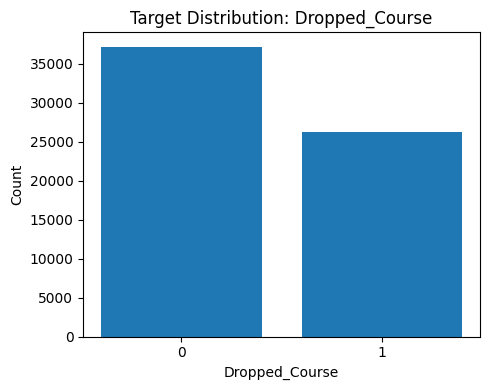

Baseline cancellation/drop rate: 41.44%


In [ ]:
df = df_raw.copy()

print("Shape:", df.shape)
display(df.info())

target_counts = df[TARGET].value_counts().sort_index()
target_pct = (target_counts / len(df) * 100).round(2)

target_summary = pd.DataFrame({"count": target_counts, "percent": target_pct})
display(target_summary)

plt.figure(figsize=(5, 4))
plt.bar(target_counts.index.astype(str), target_counts.values)
plt.title(f"Target Distribution: {TARGET}")
plt.xlabel(TARGET)
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print(f"Baseline cancellation/drop rate: {df[TARGET].mean()*100:.2f}%")

In [ ]:
id_cols = existing(["Client_ID", "ID_Client", "Agent_ID", "ID_Agent", "Company_ID", "ID_Company"], df)
date_cols = existing(["Course_Start_Date", "Date_Start_Course"], df)

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_features = [c for c in numeric_cols if c != TARGET]
categorical_cols = [c for c in df.select_dtypes(include="object").columns if c not in date_cols]

summary_cols = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "n_unique": [df[c].nunique(dropna=True) for c in df.columns],
    "missing_pct": [df[c].isna().mean() * 100 for c in df.columns]
}).sort_values(["missing_pct", "n_unique"], ascending=[False, False])

display(summary_cols.round(2))

,column,dtype,n_unique,missing_pct
25,Company_ID,float64,184,95.08
24,Agent_ID,float64,203,17.61
7,Registration_Days_Before,float64,423,4.20
11,Requested_Lab_Config,object,8,2.74
16,Physical_Course_Kits,float64,4,1.64
19,Enrollment_Type,object,298,1.13
22,Submission_Source,object,328,0.95
26,Payment_Terms,object,236,0.92
8,Origin_Country,object,721,0.88
9,Catering_Package,object,321,0.64


**Main takeaway:**  
The cancellation rate is substantial but not extremely imbalanced. Therefore, ROC-AUC is an appropriate central evaluation metric, because the business goal is to rank course orders by cancellation risk and not only to classify observations using a fixed 0/1 threshold.

# Check 1.5 — Per-variable statistical profile

This table gives a compact statistical profile for **every variable** in the dataset.  
For numerical variables, it includes central tendency and distribution statistics.  
For categorical variables, it includes the most common value and its frequency.  
This directly supports the project requirement to provide statistical analysis for each variable.

**What this table shows:** missingness, uniqueness, type, basic numerical statistics, and dominant categorical values.  
**What we learn from it:** which variables are sparse, high-cardinality, skewed, dominated by a single value, or potentially problematic for modeling.

In [ ]:
# Per-variable statistical profile
profile_rows = []

for col in df.columns:
    s = df[col]
    row = {
        "feature": col,
        "dtype": str(s.dtype),
        "missing_count": int(s.isna().sum()),
        "missing_pct": round(s.isna().mean() * 100, 3),
        "n_unique": int(s.nunique(dropna=True))
    }

    if pd.api.types.is_numeric_dtype(s):
        row.update({
            "mean": s.mean(),
            "std": s.std(),
            "min": s.min(),
            "p25": s.quantile(0.25),
            "median": s.median(),
            "p75": s.quantile(0.75),
            "max": s.max(),
            "top_value": np.nan,
            "top_value_pct": np.nan
        })
    else:
        vc = s.fillna("missing").value_counts(normalize=True)
        row.update({
            "mean": np.nan,
            "std": np.nan,
            "min": np.nan,
            "p25": np.nan,
            "median": np.nan,
            "p75": np.nan,
            "max": np.nan,
            "top_value": vc.index[0] if len(vc) else np.nan,
            "top_value_pct": vc.iloc[0] * 100 if len(vc) else np.nan
        })
    profile_rows.append(row)

variable_profile = pd.DataFrame(profile_rows)
display(variable_profile.round(3))

,feature,dtype,missing_count,missing_pct,n_unique,mean,std,min,p25,median,p75,max,top_value,top_value_pct
0,Client_ID,int64,0,0.000,63464,39761.753,22878.981,1.0,19959.75,39819.5,59570.25,79330.0,NaN,NaN
1,Professionals_Count,int64,0,0.000,5,1.835,0.509,0.0,2.00,2.0,2.00,4.0,NaN,NaN
2,Students_Count,float64,4,0.006,5,8.752,294.239,0.0,0.00,0.0,0.00,9999.0,NaN,NaN
3,Observers_Count,int64,0,0.000,5,0.005,0.090,0.0,0.00,0.0,0.00,10.0,NaN,NaN
4,Course_Start_Date,object,0,0.000,666,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-10-16,0.536
5,Practical_Hours,int64,0,0.000,18,6.609,215.503,-5.0,0.00,1.0,1.00,10000.0,NaN,NaN
6,Theory_Hours,int64,0,0.000,29,2.164,1.470,0.0,1.00,2.0,3.00,41.0,NaN,NaN
7,Registration_Days_Before,float64,2666,4.201,423,102.894,109.179,0.0,19.00,65.0,150.00,629.0,NaN,NaN
8,Origin_Country,object,557,0.878,721,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PRT,38.220
9,Catering_Package,object,407,0.641,321,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard (Coffee Only),71.400


# Check 2 — Missingness analysis

Missing values are not only a technical issue. In real business data, the fact that a value is missing can itself be informative.

This section checks:
- which features contain missing values;
- whether missingness is concentrated in specific rows;
- whether missingness is associated with higher or lower cancellation rates.

**Visualization explanation for this section:**  
The missing-value bar chart shows which columns have the largest missingness rate. The missingness matrix shows whether missing values appear randomly across the dataset or whether they are concentrated in particular rows/features. The missingness-correlation heatmap shows whether missing values in different columns tend to appear together.  

**What we learn:** these plots help decide whether to impute a column, add a missingness indicator, treat missingness as an `unknown` category, or potentially exclude a column with excessive missingness.

In [ ]:
missing = df.isna().sum()
missing_pct = df.isna().mean() * 100

missing_table = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": missing_pct,
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(dropna=True)
}).sort_values("missing_pct", ascending=False)

display(missing_table[missing_table["missing_count"] > 0].round(2))

,missing_count,missing_pct,dtype,n_unique
Company_ID,60344,95.08,float64,184
Agent_ID,11173,17.61,float64,203
Registration_Days_Before,2666,4.20,float64,423
Requested_Lab_Config,1736,2.74,object,8
Physical_Course_Kits,1040,1.64,float64,4
Enrollment_Type,719,1.13,object,298
Submission_Source,605,0.95,object,328
Payment_Terms,587,0.92,object,236
Origin_Country,557,0.88,object,721
Catering_Package,407,0.64,object,321


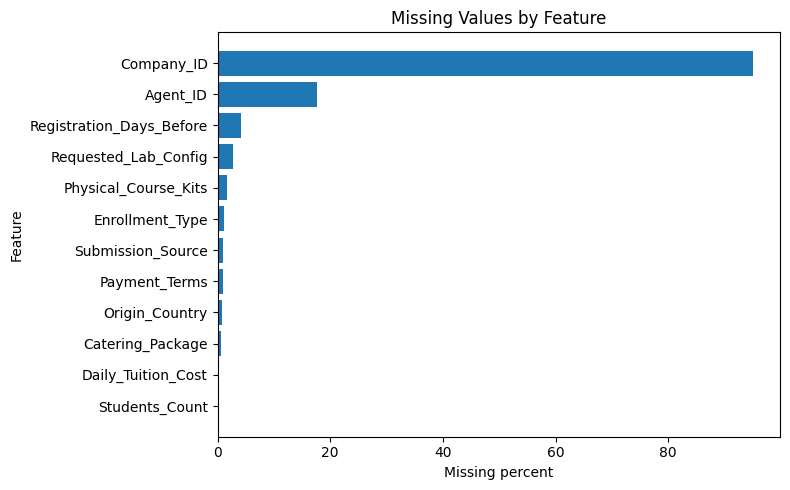

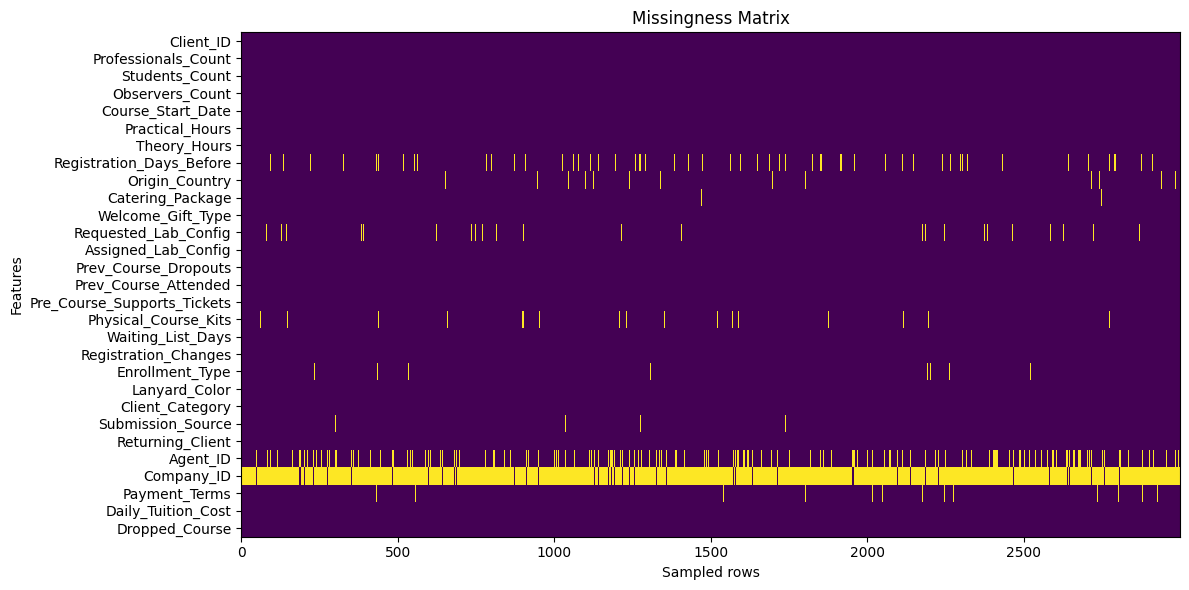

In [ ]:
miss_plot = missing_table[missing_table["missing_count"] > 0].sort_values("missing_pct")

plt.figure(figsize=(8, 5))
plt.barh(miss_plot.index, miss_plot["missing_pct"])
plt.title("Missing Values by Feature")
plt.xlabel("Missing percent")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

plot_missing_matrix(df)

In [ ]:
missing_rows = []
for col in df.columns:
    if df[col].isna().sum() > 0:
        missing_rows.append({
            "feature": col,
            "missing_n": df[col].isna().sum(),
            "missing_pct": df[col].isna().mean() * 100,
            "drop_rate_when_missing": df.loc[df[col].isna(), TARGET].mean() * 100,
            "drop_rate_when_present": df.loc[df[col].notna(), TARGET].mean() * 100,
            "difference_missing_minus_present": (
                df.loc[df[col].isna(), TARGET].mean() - df.loc[df[col].notna(), TARGET].mean()
            ) * 100
        })

missing_vs_target = pd.DataFrame(missing_rows).sort_values("missing_pct", ascending=False)
display(missing_vs_target.round(2))

,feature,missing_n,missing_pct,drop_rate_when_missing,drop_rate_when_present,difference_missing_minus_present
9,Company_ID,60344,95.08,42.48,21.22,21.27
8,Agent_ID,11173,17.61,33.51,43.13,-9.62
1,Registration_Days_Before,2666,4.20,41.52,41.44,0.09
4,Requested_Lab_Config,1736,2.74,40.96,41.45,-0.50
5,Physical_Course_Kits,1040,1.64,39.33,41.47,-2.15
6,Enrollment_Type,719,1.13,41.17,41.44,-0.27
7,Submission_Source,605,0.95,45.45,41.40,4.05
10,Payment_Terms,587,0.92,35.43,41.50,-6.06
2,Origin_Country,557,0.88,43.27,41.42,1.84
3,Catering_Package,407,0.64,38.57,41.46,-2.88


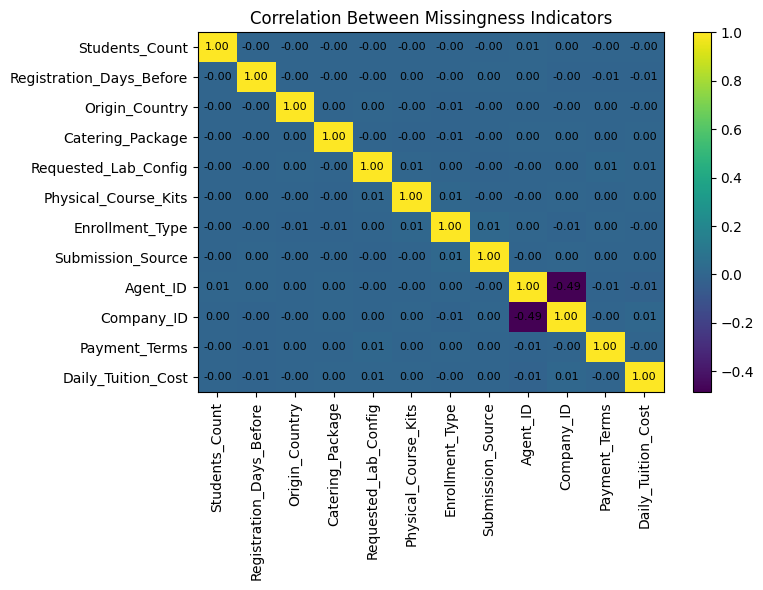

In [ ]:
missing_indicators = df.isna().astype(int)
cols_with_missing = missing_indicators.columns[missing_indicators.sum() > 0].tolist()

if len(cols_with_missing) >= 2:
    miss_corr = missing_indicators[cols_with_missing].corr()
    plot_heatmap_from_df(miss_corr, "Correlation Between Missingness Indicators", figsize=(8, 6), annotate=True)
else:
    print("Not enough columns with missing values for a missingness-correlation heatmap.")

**Main takeaway:**  
The missingness analysis suggests that missing values are not only a technical issue. In several variables, missingness may reflect meaningful business processes, such as incomplete registration information, unavailable company details or different operational handling. Therefore, missingness indicators should be preserved in the modeling stage rather than simply filling all missing values mechanically.

# Check 3 — Category cleaning and cardinality analysis

Categorical variables often contain inconsistent text formatting. For example, the same value may appear with different capitalization or extra spaces.

This section checks how many categories remain after basic cleaning and identifies high-cardinality variables that may require special treatment later.

**Visualization explanation for this section:**  
The top-category bar charts show the most common values in each categorical variable after basic text cleaning.  

**What we learn:** these plots reveal dominant categories, rare-category problems, and high-cardinality columns that may require grouping or special encoding in later modeling stages.

In [ ]:
df_eda = df.copy()

date_col = date_cols[0] if len(date_cols) > 0 else None
if date_col is not None:
    df_eda["Course_Start_Date_dt"] = pd.to_datetime(df_eda[date_col], errors="coerce")
else:
    df_eda["Course_Start_Date_dt"] = pd.NaT

cat_cols = [c for c in df_eda.select_dtypes(include="object").columns if c not in date_cols]
category_cleaning_rows = []

for col in cat_cols:
    raw_unique = df_eda[col].nunique(dropna=True)
    cleaned = df_eda[col].map(normalize_category)
    cleaned_unique = cleaned.nunique(dropna=True)
    category_cleaning_rows.append({
        "feature": col,
        "raw_unique": raw_unique,
        "cleaned_unique": cleaned_unique,
        "reduction": raw_unique - cleaned_unique,
        "missing_pct": df_eda[col].isna().mean() * 100
    })
    df_eda[col] = cleaned

category_cleaning_table = pd.DataFrame(category_cleaning_rows).sort_values("reduction", ascending=False)
display(category_cleaning_table.round(2))

,feature,raw_unique,cleaned_unique,reduction,missing_pct
0,Origin_Country,721,154,567,0.88
7,Client_Category,505,8,497,0.00
8,Submission_Source,328,5,323,0.95
1,Catering_Package,321,4,317,0.64
5,Enrollment_Type,298,4,294,1.13
6,Lanyard_Color,240,5,235,0.00
9,Payment_Terms,236,4,232,0.92
4,Assigned_Lab_Config,9,9,0,0.00
2,Welcome_Gift_Type,4,4,0,0.00
3,Requested_Lab_Config,8,8,0,2.74


In [ ]:
pareto_rows = []
for col in cat_cols:
    vc = df_eda[col].fillna("missing").value_counts(normalize=True)
    cumulative = vc.cumsum()
    n80 = int((cumulative <= 0.80).sum() + 1)
    rare_pct = vc[vc < 0.01].sum() * 100
    pareto_rows.append({
        "feature": col,
        "n_categories": len(vc),
        "categories_for_80pct_rows": n80,
        "pct_rows_in_categories_under_1pct": rare_pct
    })

pareto_table = pd.DataFrame(pareto_rows).sort_values("pct_rows_in_categories_under_1pct", ascending=False)
display(pareto_table.round(2))

,feature,n_categories,categories_for_80pct_rows,pct_rows_in_categories_under_1pct
0,Origin_Country,155,9,11.50
4,Assigned_Lab_Config,9,2,1.38
7,Client_Category,8,3,0.99
1,Catering_Package,5,2,0.71
8,Submission_Source,6,1,0.58
3,Requested_Lab_Config,9,2,0.54
5,Enrollment_Type,5,2,0.38
9,Payment_Terms,5,1,0.35
2,Welcome_Gift_Type,4,3,0.00
6,Lanyard_Color,5,3,0.00


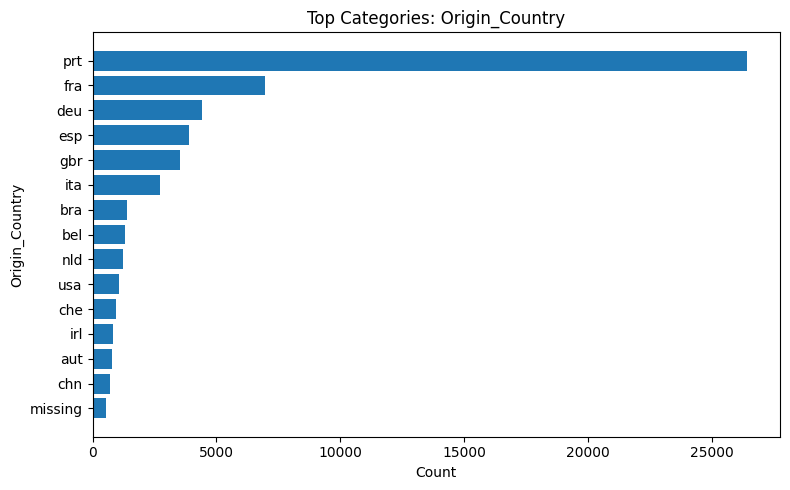

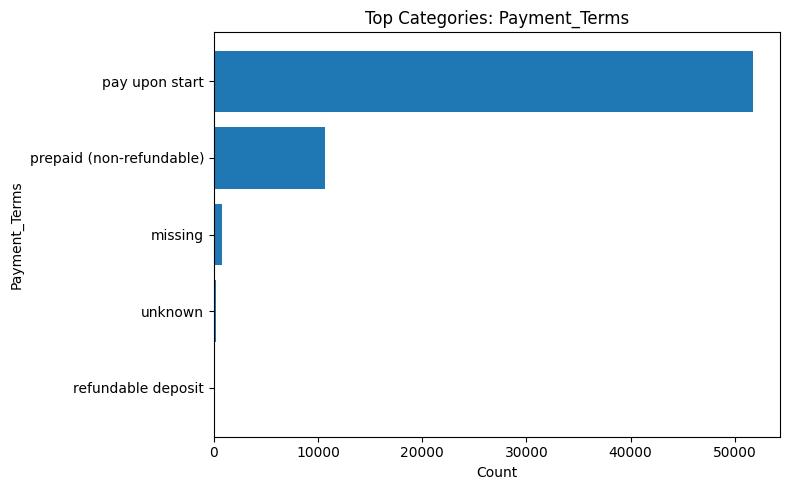

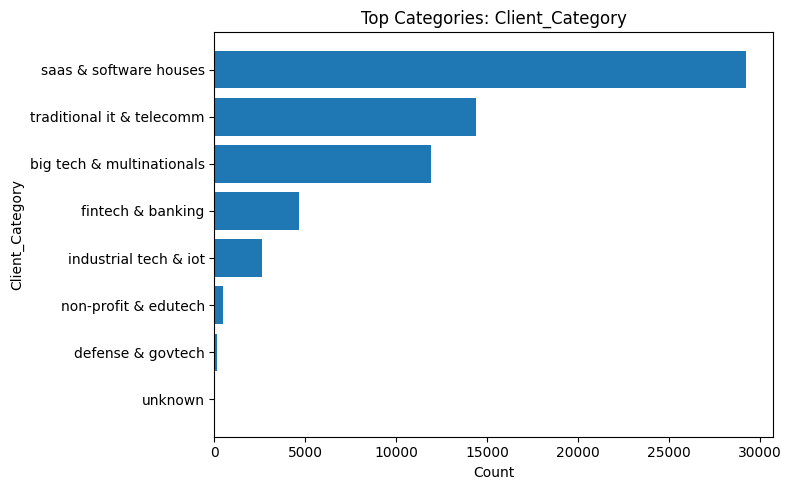

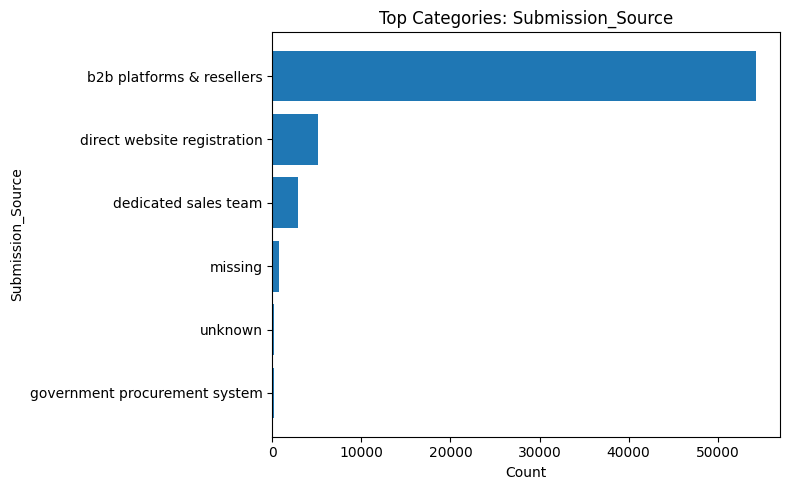

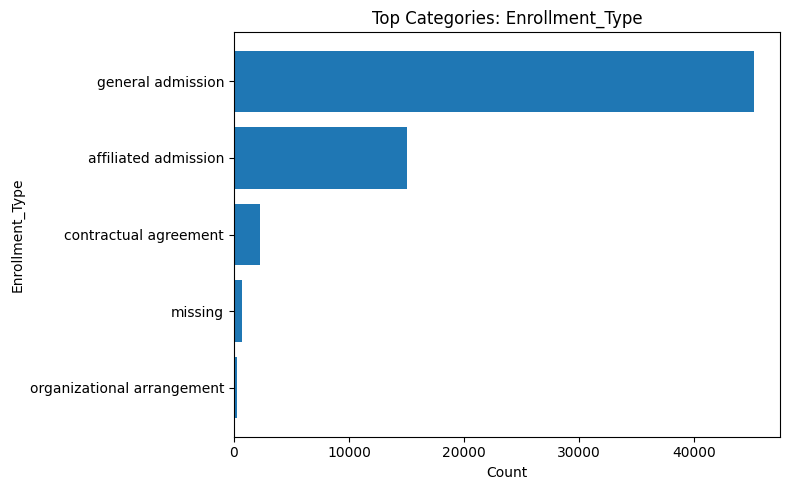

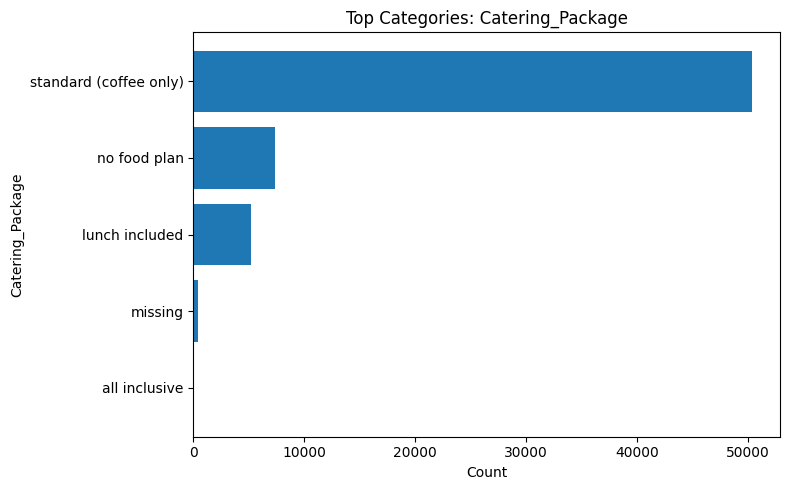

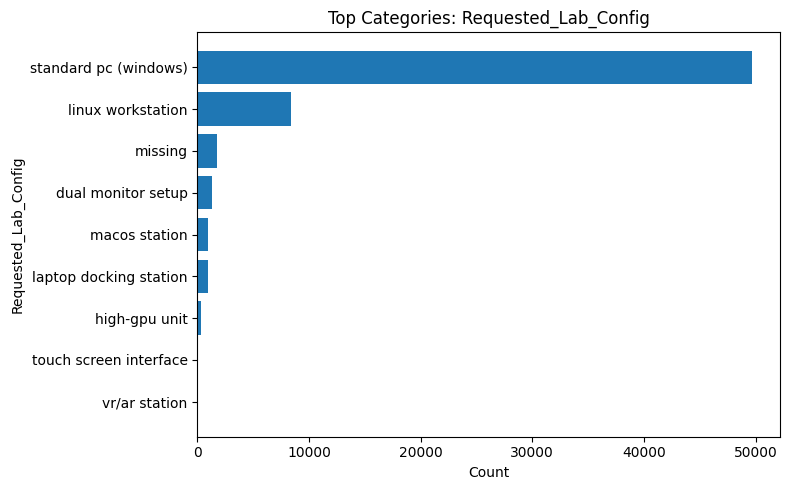

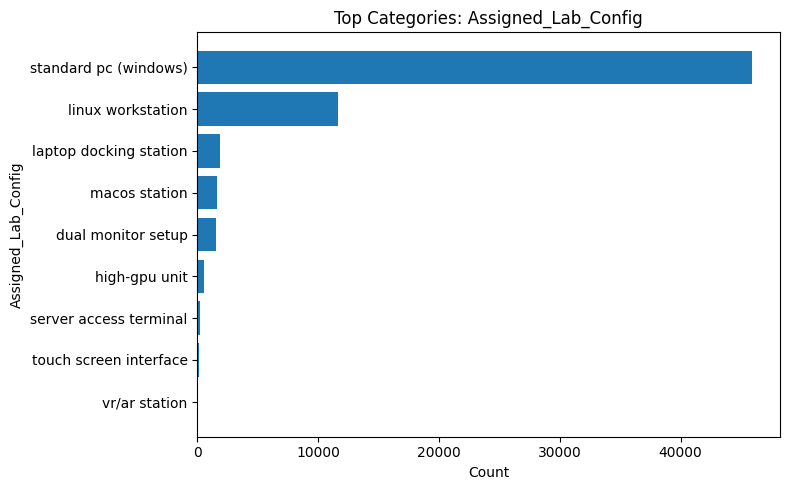

In [ ]:
possible_categorical_focus = [
    "Origin_Country", "Country_Origin",
    "Payment_Terms", "Terms_Payment",
    "Client_Category", "Category_Client",
    "Submission_Source", "Source_Submission",
    "Enrollment_Type", "Type_Enrollment",
    "Catering_Package", "Package_Catering",
    "Requested_Lab_Config", "Config_Lab_Requested",
    "Assigned_Lab_Config", "Config_Lab_Assigned"
]
important_cat_for_counts = existing(possible_categorical_focus, df_eda)

for col in important_cat_for_counts:
    vc = df_eda[col].fillna("missing").value_counts().head(15)
    plt.figure(figsize=(8, 5))
    plt.barh(vc.index.astype(str)[::-1], vc.values[::-1])
    plt.title(f"Top Categories: {col}")
    plt.xlabel("Count")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

**Main takeaway:**  
Several categorical variables contain multiple levels, including categories that appear only rarely. This may increase dimensionality after one-hot encoding and create sparse, unstable features. Therefore, rare-category grouping is justified before modeling, especially for tree-based and regularized models.

# Check 4 — Numerical distributions, ECDF plots, and outlier analysis

This section uses several complementary tools:

- Histograms to inspect distribution shape.
- Boxplots to identify spread and extreme values.
- ECDF plots to compare distributions between cancelled and non-cancelled courses.
- IQR-based summary to flag possible outliers.

**Visualization explanation for this section:**  
For each numerical feature, the histogram shows the feature distribution, the boxplot compares cancelled and non-cancelled courses, and the ECDF compares the entire cumulative distribution between the two target groups.  

**What we learn:** these plots help identify skewness, outliers, class separation, and whether the feature may be useful for later AUC-oriented ranking.

In [ ]:
numeric_non_id = [c for c in numeric_features if c not in id_cols]

desc = df_eda[numeric_non_id + [TARGET]].describe(
    percentiles=[.01, .05, .25, .50, .75, .95, .99]
).T

display(desc.round(3))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Professionals_Count,63464.0,1.835,0.509,0.0,1.0,1.0,2.0,2.0,2.0,3.0,3.0,4.0
Students_Count,63460.0,8.752,294.239,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,9999.0
Observers_Count,63464.0,0.005,0.090,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0
Practical_Hours,63464.0,6.609,215.503,-5.0,0.0,0.0,0.0,1.0,1.0,2.0,3.0,10000.0
Theory_Hours,63464.0,2.164,1.470,0.0,0.0,0.0,1.0,2.0,3.0,5.0,6.0,41.0
Registration_Days_Before,60798.0,102.894,109.179,0.0,0.0,1.0,19.0,65.0,150.0,326.0,447.0,629.0
Prev_Course_Dropouts,63464.0,0.096,0.449,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,21.0
Prev_Course_Attended,63464.0,0.123,1.535,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,61.0
Pre_Course_Supports_Tickets,63464.0,0.513,0.764,0.0,0.0,0.0,0.0,0.0,1.0,2.0,3.0,5.0
Physical_Course_Kits,62424.0,0.026,0.160,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0


In [ ]:
outlier_rows = []
for col in numeric_non_id:
    s = df_eda[col].dropna()
    if s.empty:
        continue
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_mask = (df_eda[col] < lower) | (df_eda[col] > upper)
    outlier_rows.append({
        "feature": col,
        "q1": q1,
        "median": s.median(),
        "q3": q3,
        "iqr": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": outlier_mask.sum(),
        "outlier_pct": outlier_mask.mean() * 100,
        "min": s.min(),
        "max": s.max()
    })

outlier_table = pd.DataFrame(outlier_rows).sort_values("outlier_pct", ascending=False)
display(outlier_table.round(3))

,feature,q1,median,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_pct,min,max
0,Professionals_Count,2.0,2.0,2.0,0.0,2.0,2.0,17063,26.886,0.0,4.0
11,Registration_Changes,0.0,0.0,0.0,0.0,0.0,0.0,7986,12.584,0.0,21.0
6,Prev_Course_Dropouts,0.0,0.0,0.0,0.0,0.0,0.0,5280,8.320,0.0,21.0
1,Students_Count,0.0,0.0,0.0,0.0,0.0,0.0,3882,6.117,0.0,9999.0
10,Waiting_List_Days,0.0,0.0,0.0,0.0,0.0,0.0,3375,5.318,0.0,391.0
13,Daily_Tuition_Cost,75.0,94.5,117.0,42.0,12.0,180.0,2874,4.529,0.0,5400.0
5,Registration_Days_Before,19.0,65.0,150.0,131.0,-177.5,346.5,2177,3.430,0.0,629.0
12,Returning_Client,0.0,0.0,0.0,0.0,0.0,0.0,1722,2.713,0.0,1.0
9,Physical_Course_Kits,0.0,0.0,0.0,0.0,0.0,0.0,1634,2.575,0.0,3.0
8,Pre_Course_Supports_Tickets,0.0,0.0,1.0,1.0,-1.5,2.5,1283,2.022,0.0,5.0


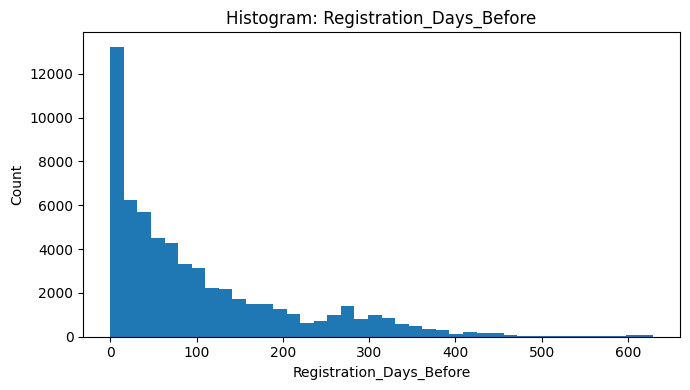

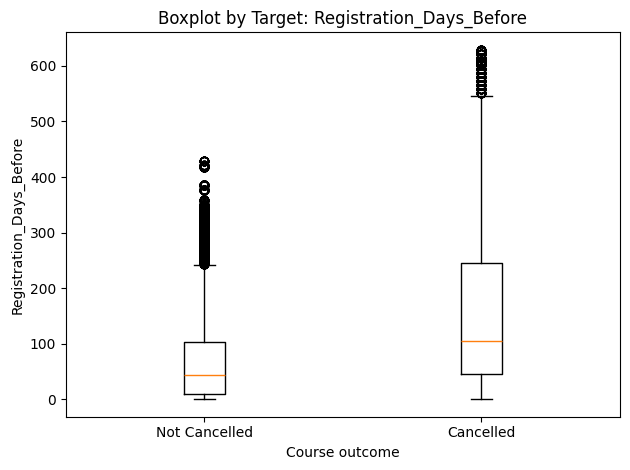

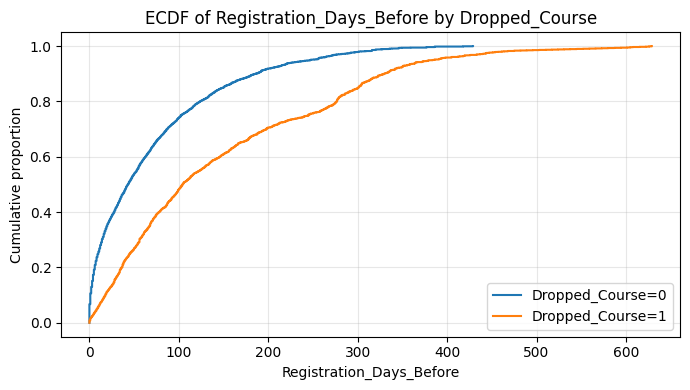

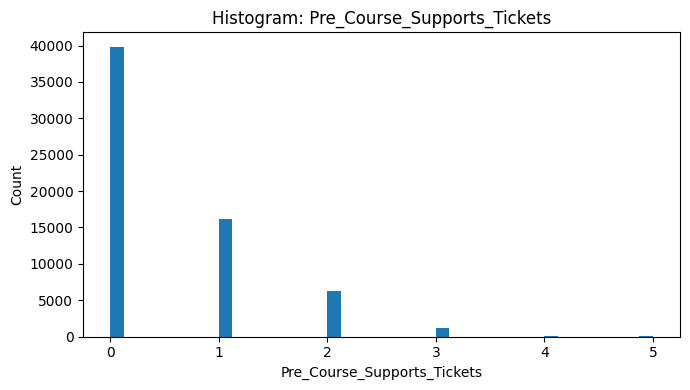

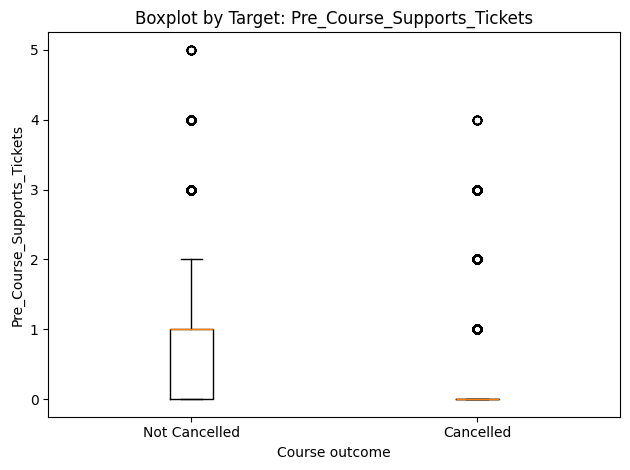

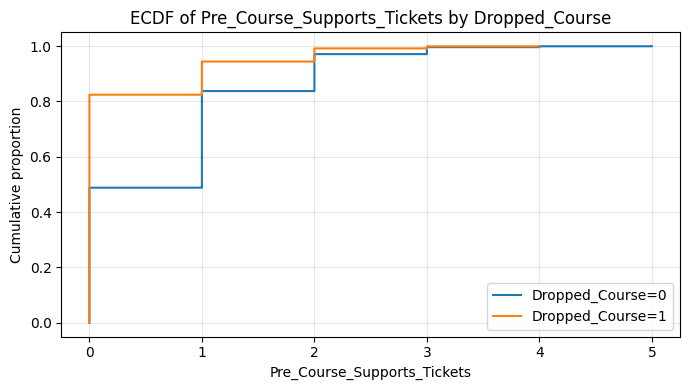

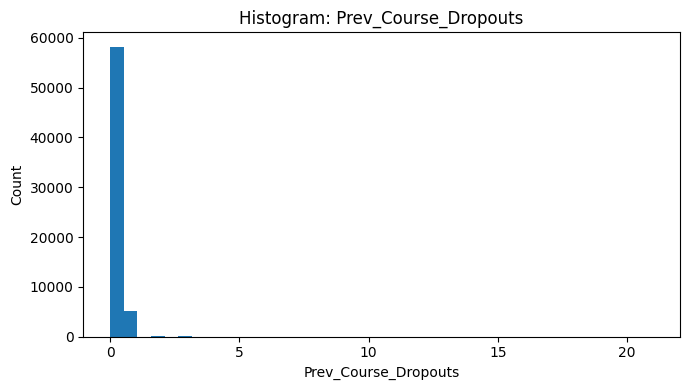

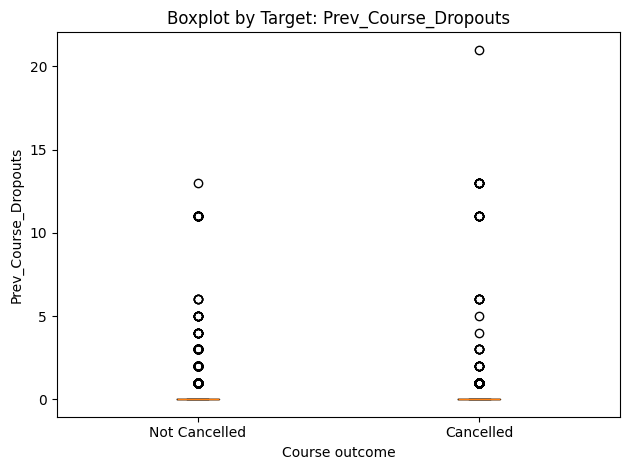

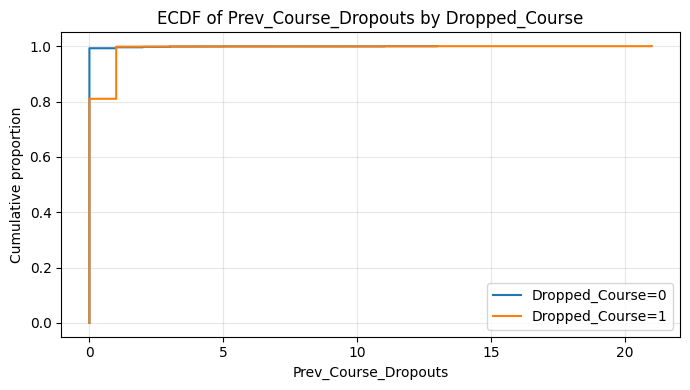

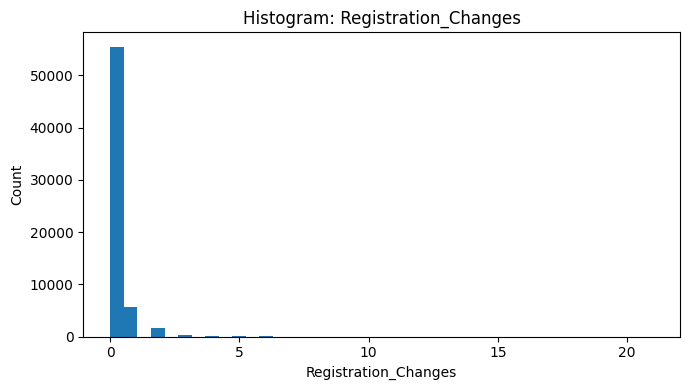

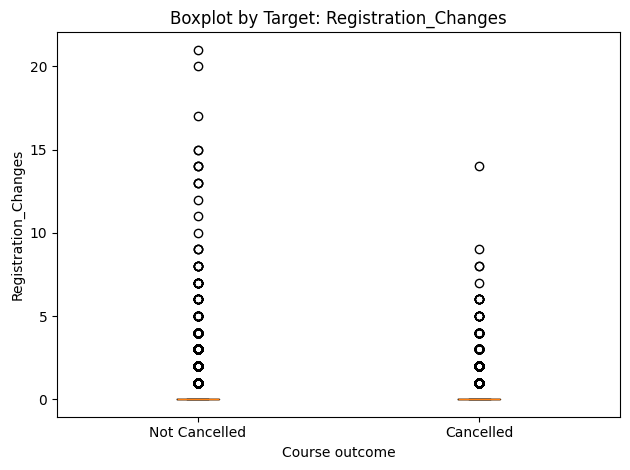

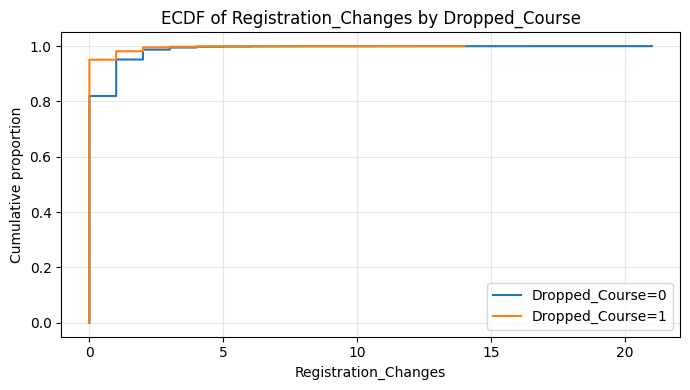

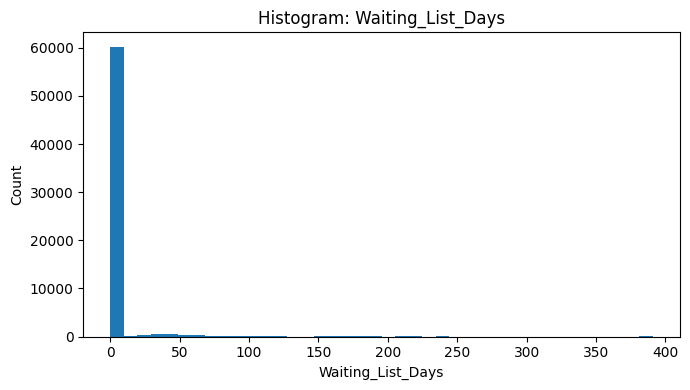

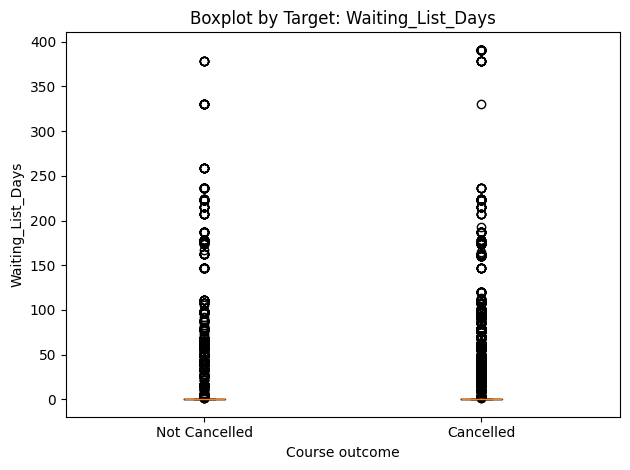

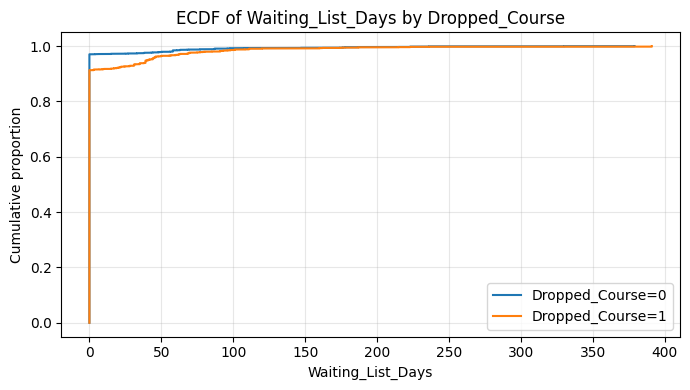

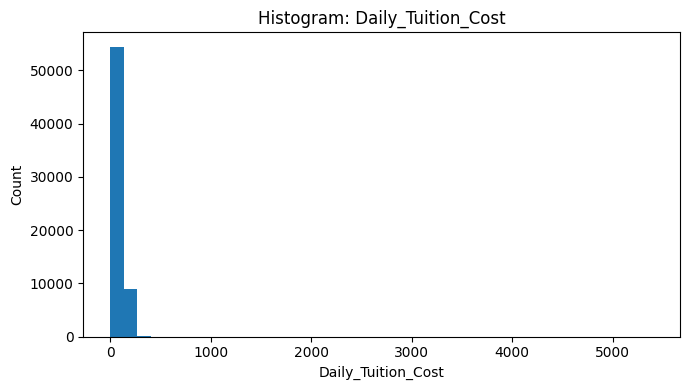

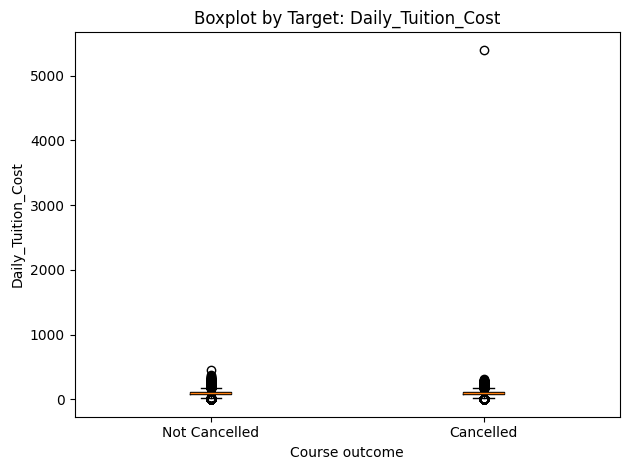

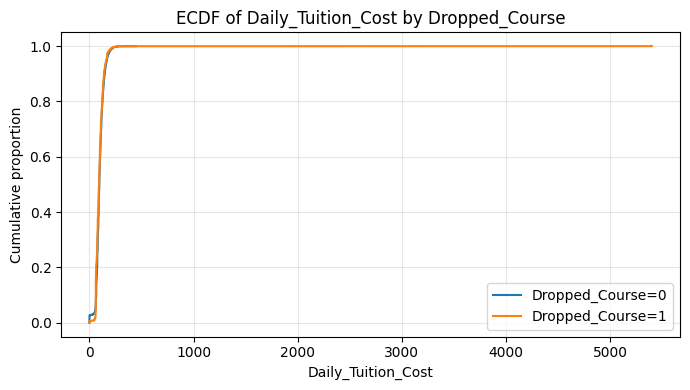

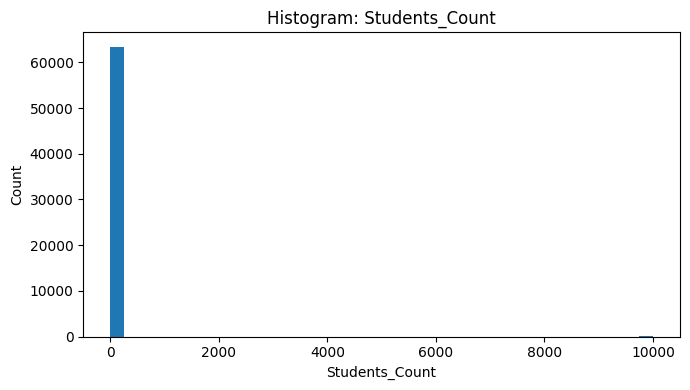

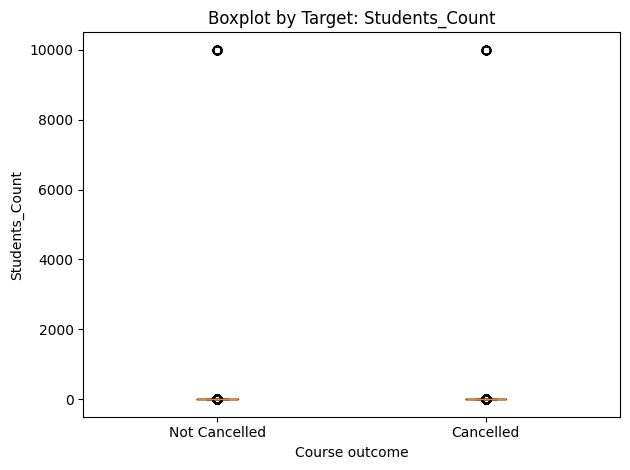

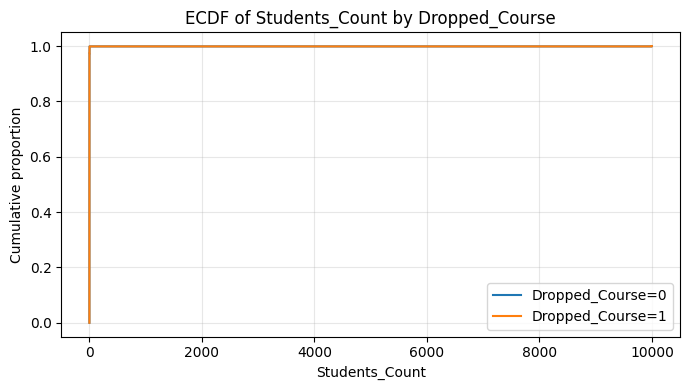

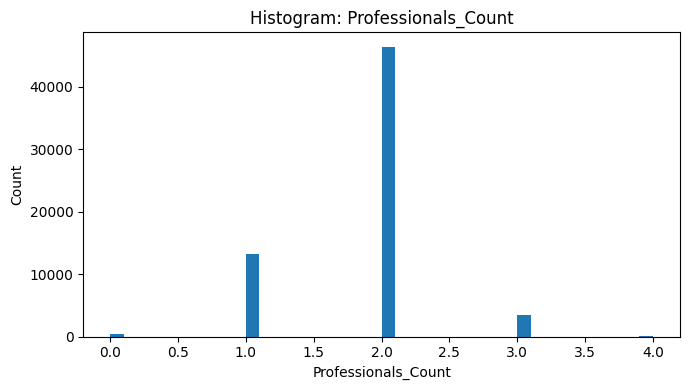

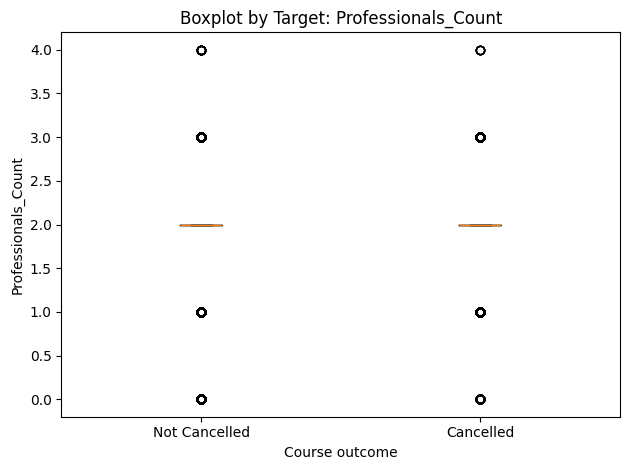

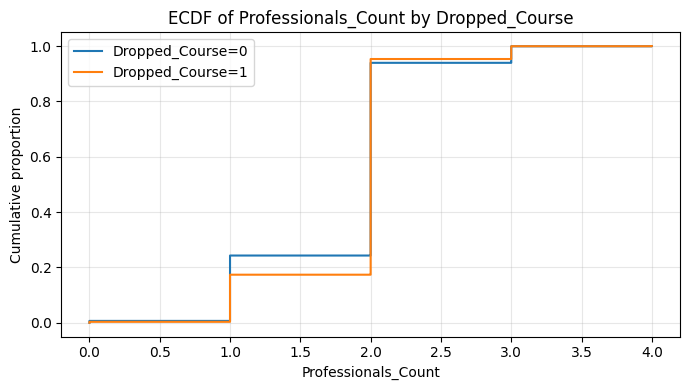

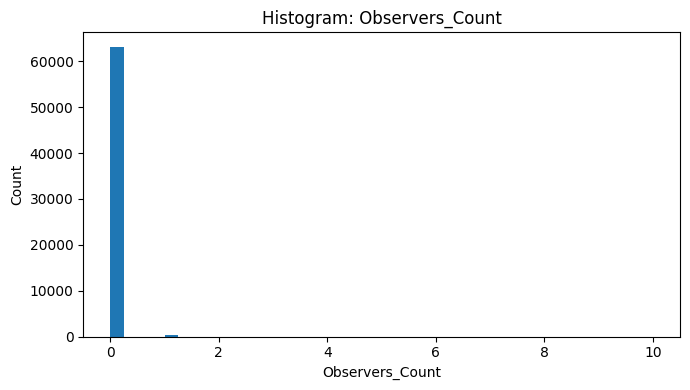

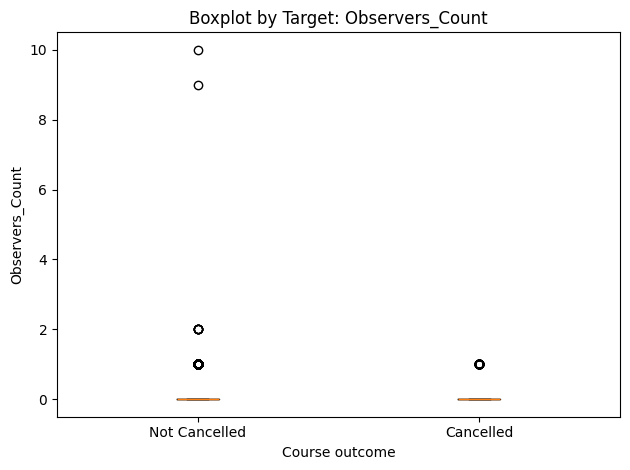

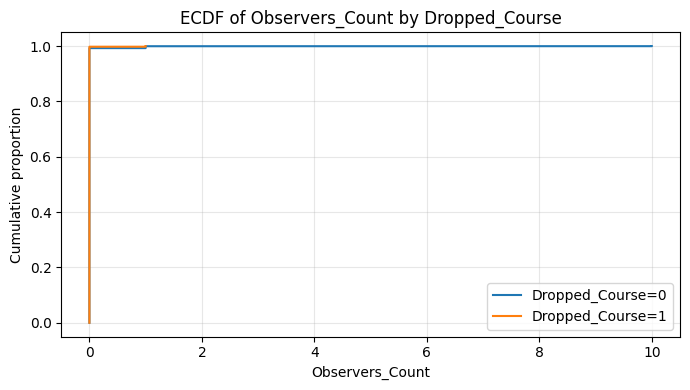

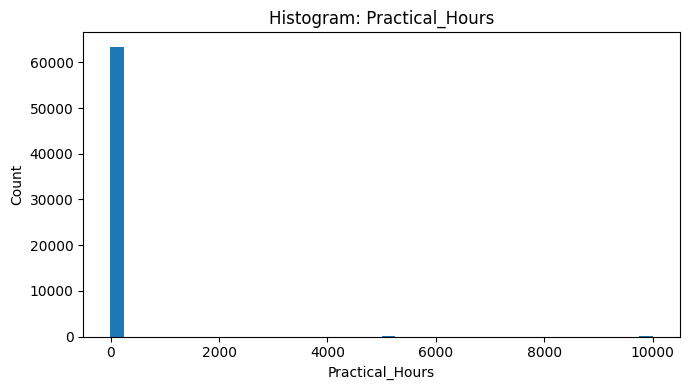

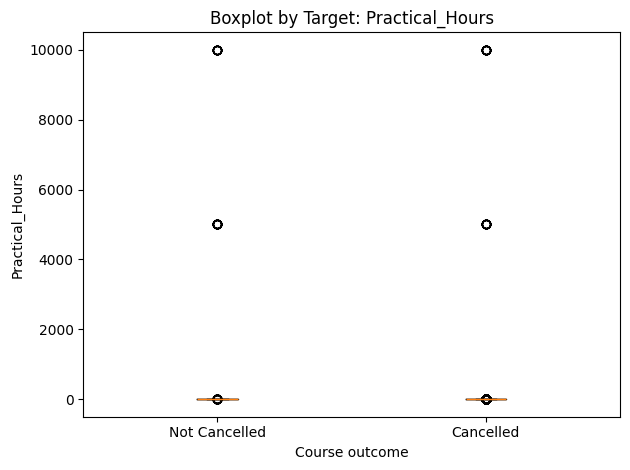

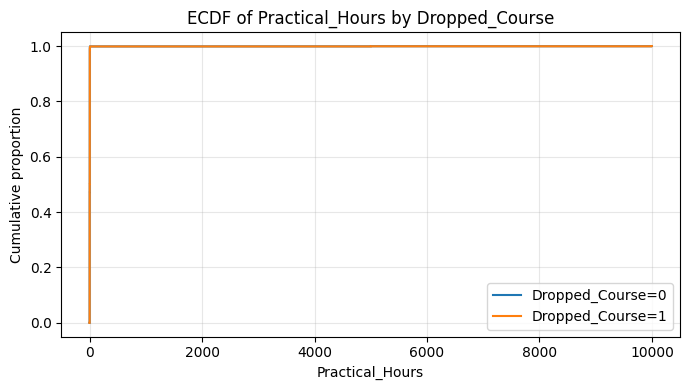

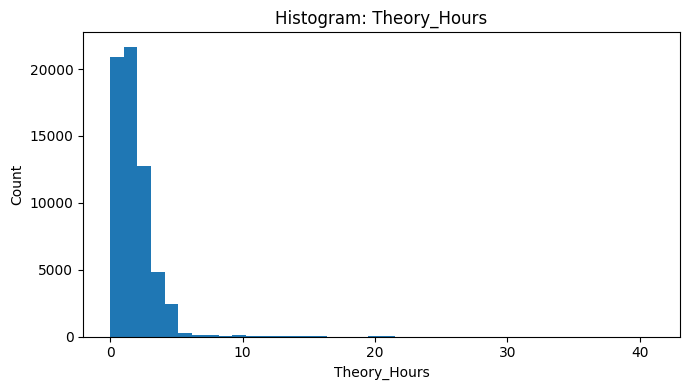

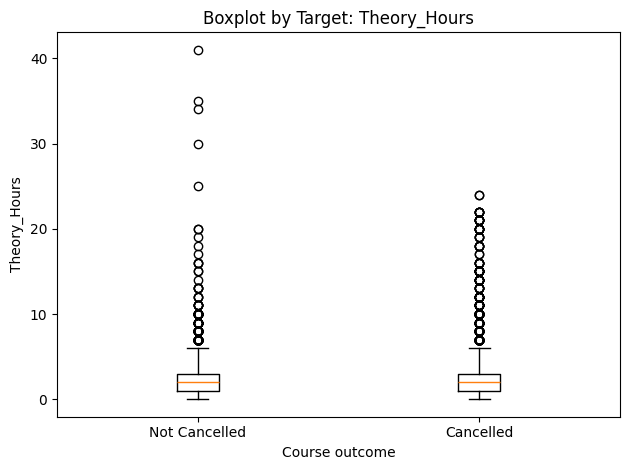

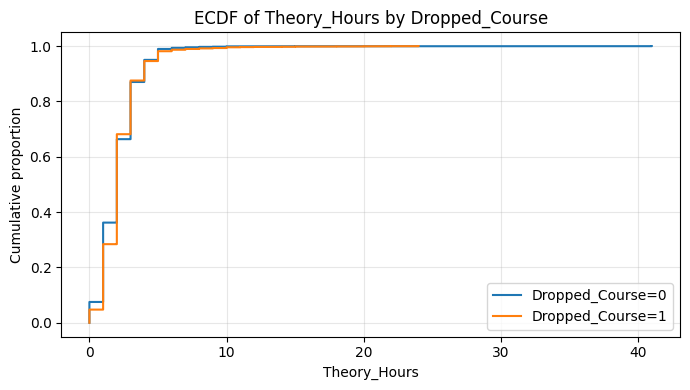

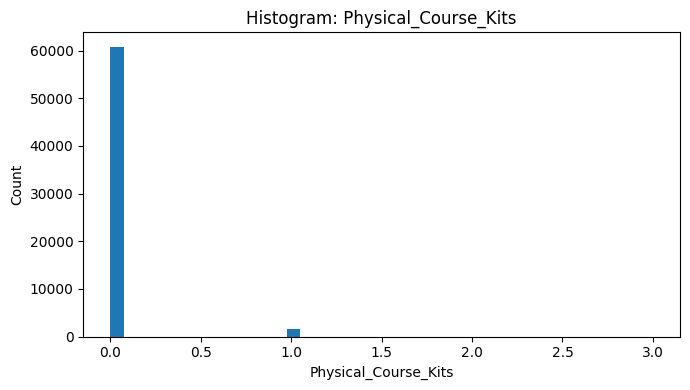

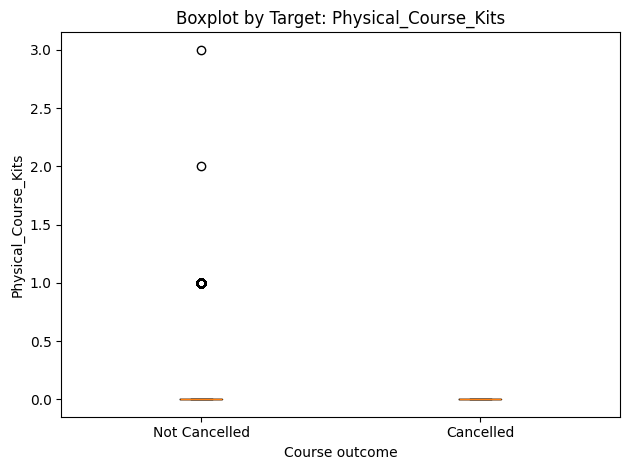

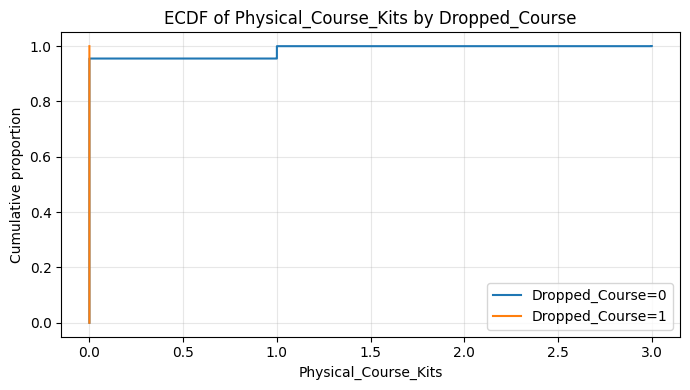

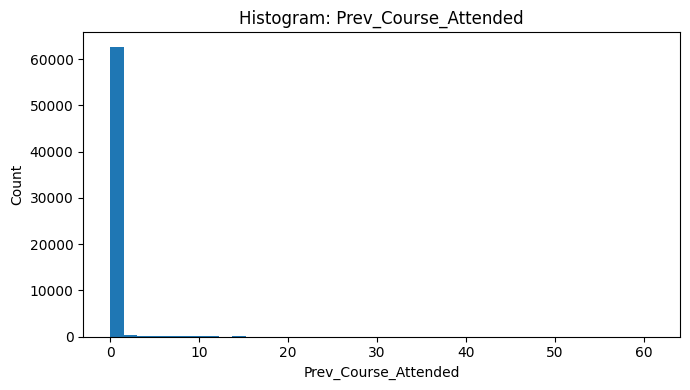

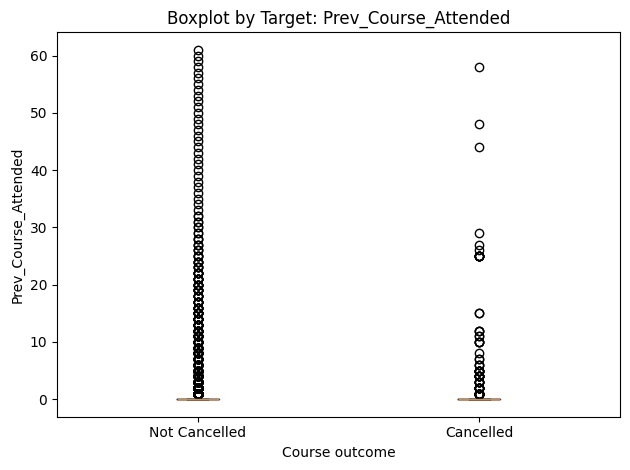

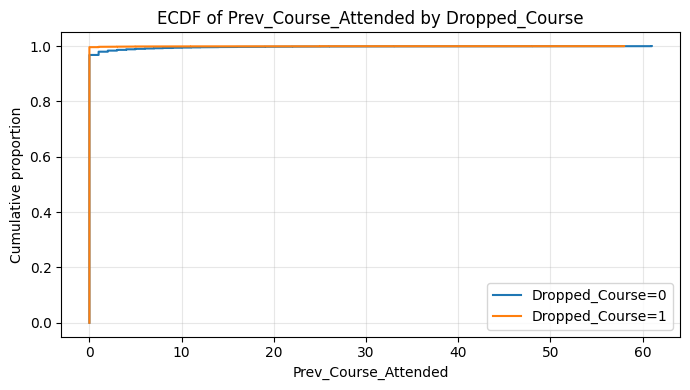

In [ ]:
possible_selected_numeric = [
    "Registration_Days_Before", "Before_Days_Registration",
    "Pre_Course_Supports_Tickets", "Tickets_Supports_Course_Pre",
    "Prev_Course_Dropouts", "Dropouts_Course_Prev",
    "Registration_Changes", "Changes_Registration",
    "Waiting_List_Days", "Days_List_Waiting",
    "Daily_Tuition_Cost", "Cost_Tuition_Daily",
    "Students_Count", "Count_Students",
    "Professionals_Count", "Count_Professionals",
    "Observers_Count", "Count_Observers",
    "Practical_Hours", "Hours_Practical",
    "Theory_Hours", "Hours_Theory",
    "Physical_Course_Kits", "Kits_Course_Physical",
    "Prev_Course_Attended", "Attended_Course_Prev"
]
selected_numeric = existing(possible_selected_numeric, df_eda)

for col in selected_numeric:
    values = df_eda[col].dropna()

    plt.figure(figsize=(7, 4))
    plt.hist(values, bins=40)
    plt.title(f"Histogram: {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

    data0 = df_eda.loc[df_eda[TARGET] == 0, col].dropna()
    data1 = df_eda.loc[df_eda[TARGET] == 1, col].dropna()

    plt.boxplot(
    [data0, data1],
    tick_labels=["Not Cancelled", "Cancelled"],
    showfliers=True
    )
    plt.title(f"Boxplot by Target: {col}")
    plt.xlabel("Course outcome")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

    plot_ecdf_by_target(df_eda, col)


**Main takeaway:**  
Several numerical variables are strongly skewed and contain isolated values far outside their regular ranges. We do not treat every statistically extreme value as an error. In Stage B, only clearly implausible values are corrected, while unusual but plausible observations are preserved because they may contain useful business information.

# Check 5 — Relationship between numerical features and the target

Pearson correlation measures linear relationships, while Spearman correlation is rank-based and can capture monotonic non-linear patterns.

**Visualization explanation for this section:**  
The correlation bar chart ranks numerical variables by their linear association with the target. The binned drop-rate plots show how cancellation risk changes across ranges of each numerical variable.  

**What we learn:** a feature is especially promising if its drop rate changes consistently across bins, even if the Pearson correlation is not very high.

,pearson_corr,spearman_corr
Registration_Days_Before,0.3512,0.3515
Pre_Course_Supports_Tickets,-0.3013,-0.3348
Prev_Course_Dropouts,0.1991,0.3244
Registration_Changes,-0.1477,-0.1933
Physical_Course_Kits,-0.1378,-0.1380
Waiting_List_Days,0.0676,0.1245
Returning_Client,-0.0592,-0.0592
Professionals_Count,0.0568,0.0606
Prev_Course_Attended,-0.0520,-0.0990
Theory_Hours,0.0450,0.0408


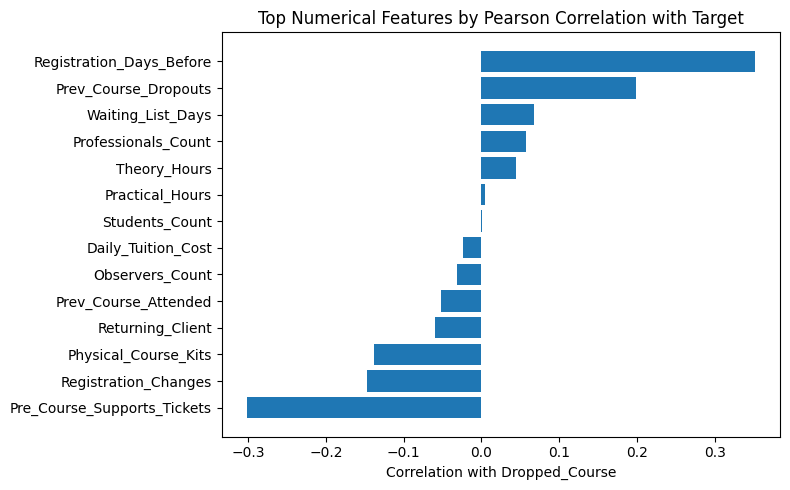

In [ ]:
corr_pearson = (
    df_eda[numeric_non_id + [TARGET]]
    .corr(method="pearson", numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

corr_spearman = (
    df_eda[numeric_non_id + [TARGET]]
    .corr(method="spearman", numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

corr_compare = pd.DataFrame({
    "pearson_corr": corr_pearson,
    "spearman_corr": corr_spearman
}).loc[corr_pearson.index]

display(corr_compare.round(4))

top_corr = corr_pearson.head(15).sort_values()
plt.figure(figsize=(8, 5))
plt.barh(top_corr.index, top_corr.values)
plt.title("Top Numerical Features by Pearson Correlation with Target")
plt.xlabel(f"Correlation with {TARGET}")
plt.tight_layout()
plt.show()

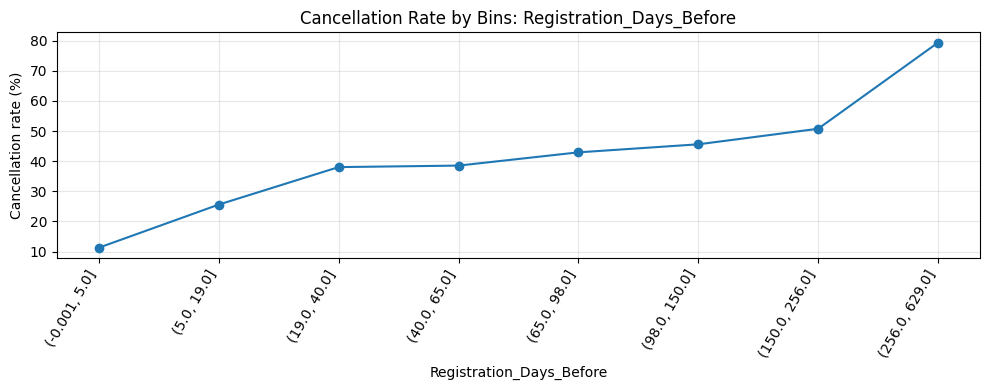

,count,mean,drop_pct
bin,,,
"(-0.001, 5.0]",7713,0.11,11.31
"(5.0, 19.0]",7496,0.26,25.60
"(19.0, 40.0]",7807,0.38,38.03
"(40.0, 65.0]",7402,0.39,38.53
"(65.0, 98.0]",7726,0.43,42.92
"(98.0, 150.0]",7559,0.46,45.59
"(150.0, 256.0]",7543,0.51,50.75
"(256.0, 629.0]",7552,0.79,79.32


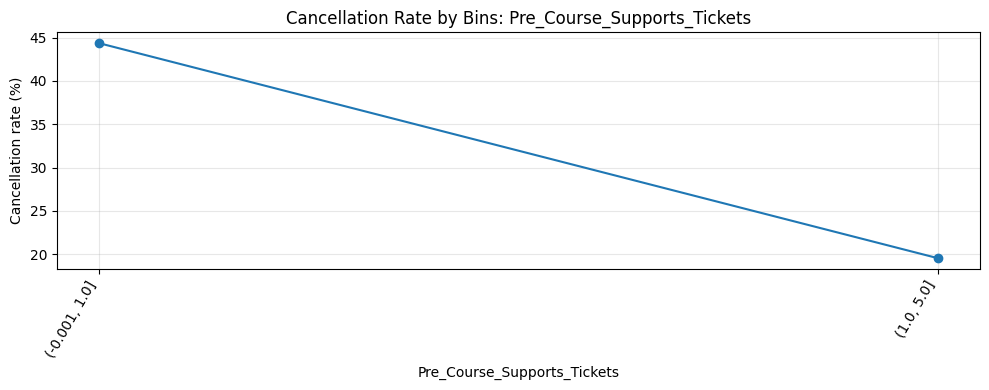

,count,mean,drop_pct
bin,,,
"(-0.001, 1.0]",55968,0.44,44.38
"(1.0, 5.0]",7496,0.20,19.52


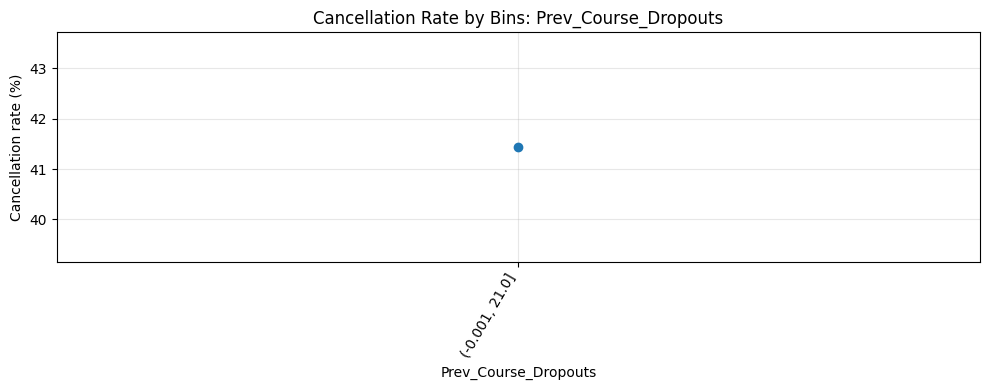

,count,mean,drop_pct
bin,,,
"(-0.001, 21.0]",63464,0.41,41.44


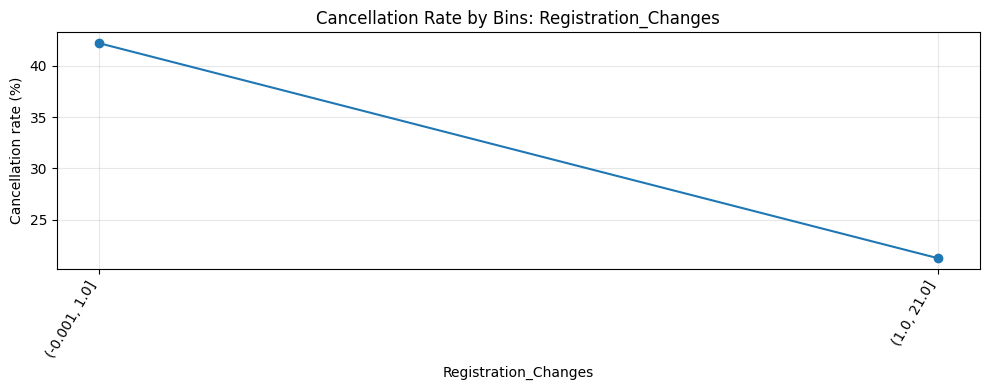

,count,mean,drop_pct
bin,,,
"(-0.001, 1.0]",61184,0.42,42.19
"(1.0, 21.0]",2280,0.21,21.27


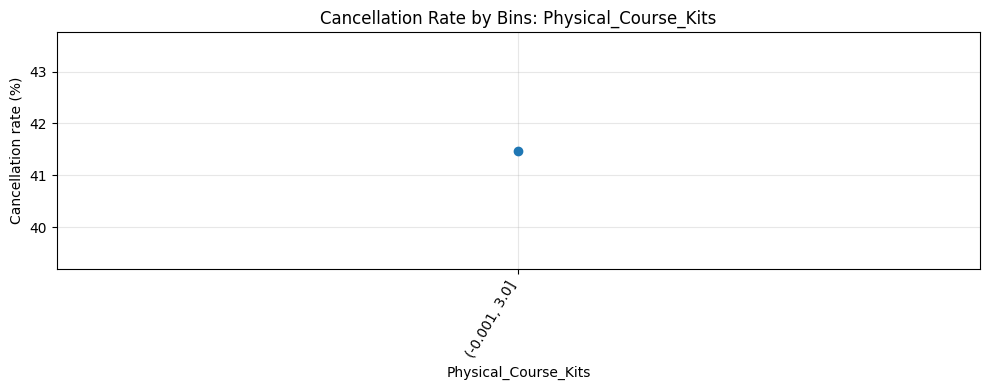

,count,mean,drop_pct
bin,,,
"(-0.001, 3.0]",62424,0.41,41.47


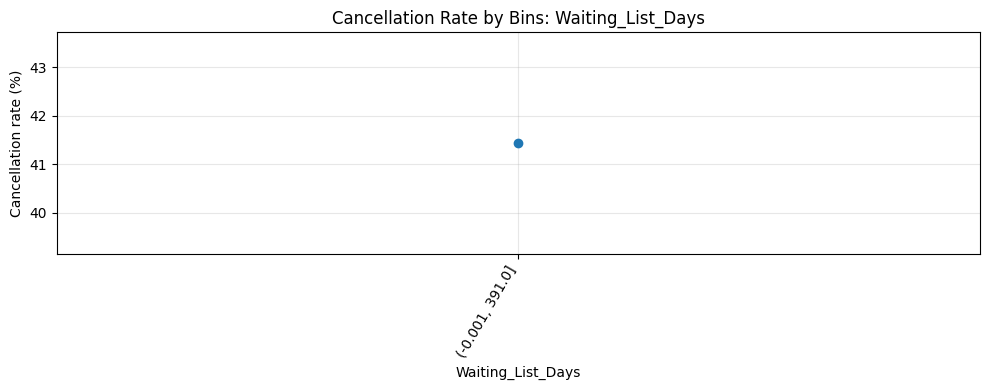

,count,mean,drop_pct
bin,,,
"(-0.001, 391.0]",63464,0.41,41.44


Returning_Client: skipped, too few unique values.


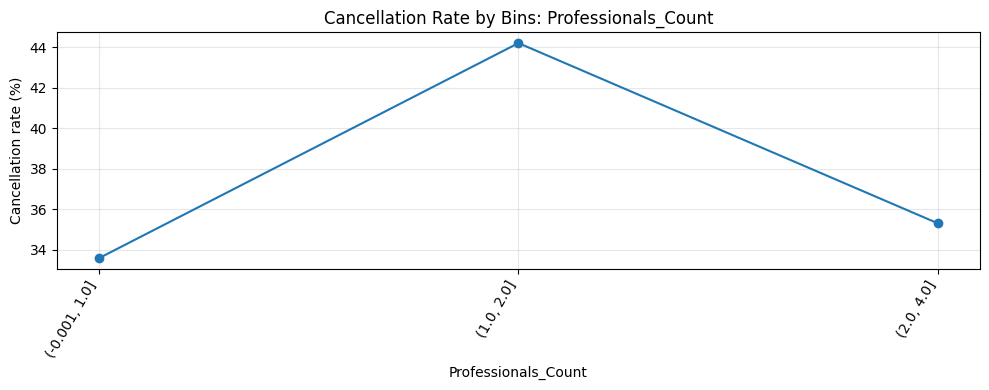

,count,mean,drop_pct
bin,,,
"(-0.001, 1.0]",13602,0.34,33.59
"(1.0, 2.0]",46401,0.44,44.20
"(2.0, 4.0]",3461,0.35,35.31


In [ ]:
def plot_binned_drop_rate(data, col, bins=10, target=TARGET):
    tmp = data[[col, target]].dropna().copy()
    if tmp[col].nunique() <= 2:
        print(f"{col}: skipped, too few unique values.")
        return None

    try:
        tmp["bin"] = pd.qcut(tmp[col], q=bins, duplicates="drop")
    except Exception:
        tmp["bin"] = pd.cut(tmp[col], bins=bins)

    tab = tmp.groupby("bin", observed=False)[target].agg(["count", "mean"])
    tab["drop_pct"] = tab["mean"] * 100

    plt.figure(figsize=(10, 4))
    plt.plot(tab.index.astype(str), tab["drop_pct"], marker="o")
    plt.title(f"Cancellation Rate by Bins: {col}")
    plt.xlabel(col)
    plt.ylabel("Cancellation rate (%)")
    plt.xticks(rotation=60, ha="right")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    display(tab.round(2))
    return tab

for col in corr_pearson.head(8).index:
    plot_binned_drop_rate(df_eda, col, bins=8)

**Main takeaway:**  
The numerical-target analysis shows that `Registration_Days_Before`, `Pre_Course_Supports_Tickets`, `Prev_Course_Dropouts`, `Registration_Changes` and `Physical_Course_Kits` are among the strongest numerical indicators of cancellation risk. Some relationships are not purely linear, so these variables should be preserved for modeling and complemented with engineered non-linear or binned features.

# Check 6 — Relationship between categorical features and the target

A very high cancellation rate in a tiny category can be misleading. Therefore, this section keeps only categories with enough observations and adds Wilson confidence intervals.

**Visualization explanation for this section:**  
The categorical drop-rate charts show which categories have the highest cancellation rates among categories with sufficient observations. The Wilson confidence intervals help avoid over-interpreting very small groups. The normalized stacked bars show the target composition inside frequent categories.  

**What we learn:** these visualizations identify high-risk and low-risk categories and support later grouping or encoding decisions.

Overall cancellation/drop rate: 41.44%

Origin_Country


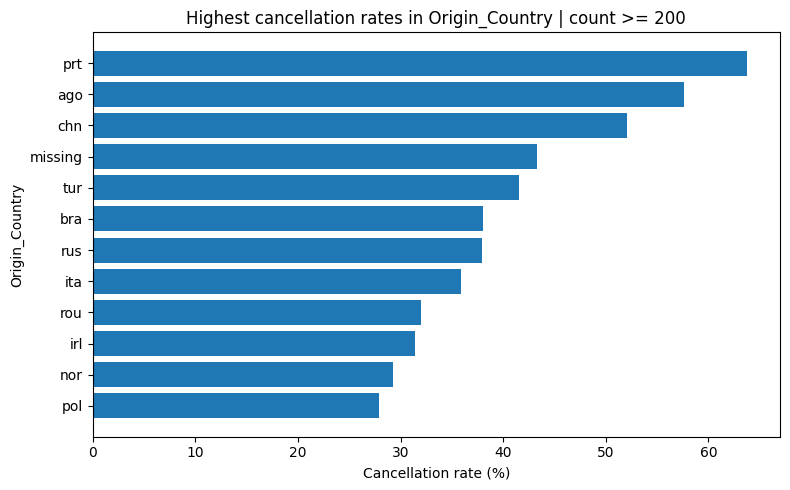

,count,drop_pct,ci_low_pct,ci_high_pct
Origin_Country,,,,
prt,26429,63.78,63.20,64.36
ago,309,57.61,52.03,62.99
chn,694,52.02,48.30,55.71
missing,557,43.27,39.21,47.41
tur,200,41.50,34.89,48.43
bra,1402,38.02,35.51,40.59
rus,348,37.93,32.99,43.13
ita,2726,35.88,34.10,37.70
rou,247,31.98,26.48,38.04



Payment_Terms


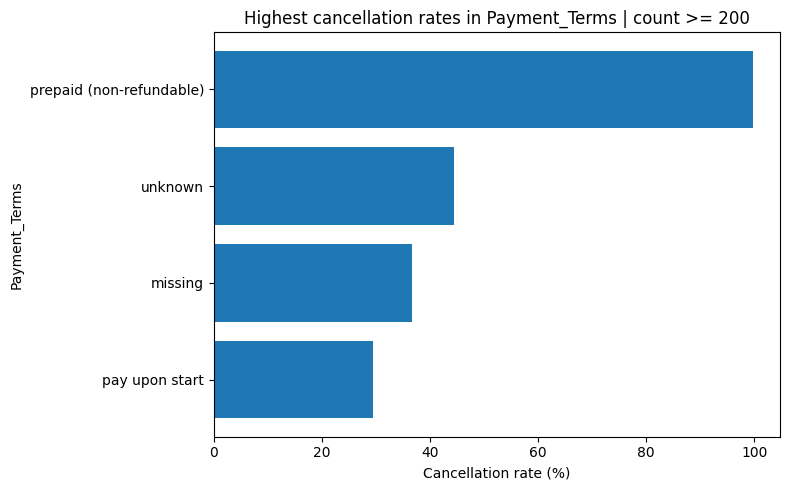

,count,drop_pct,ci_low_pct,ci_high_pct
Payment_Terms,,,,
prepaid (non-refundable),10698,99.78,99.67,99.85
unknown,214,44.39,37.89,51.09
missing,792,36.74,33.46,40.16
pay upon start,51751,29.44,29.05,29.83



Client_Category


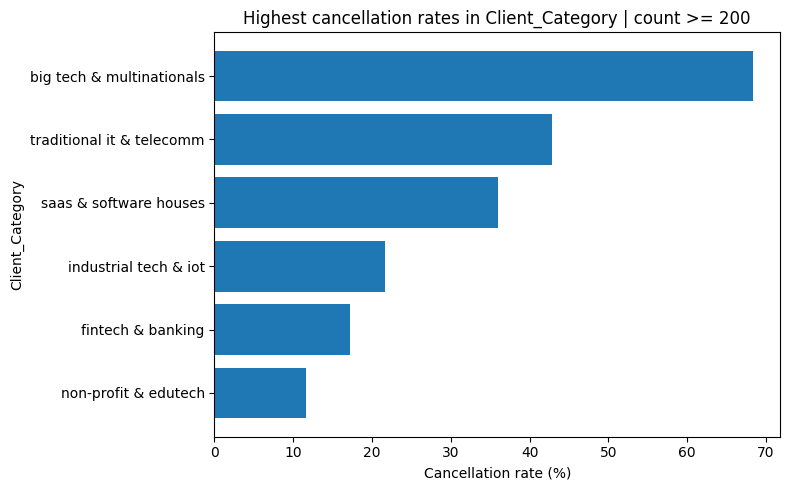

,count,drop_pct,ci_low_pct,ci_high_pct
Client_Category,,,,
big tech & multinationals,11909,68.37,67.53,69.20
traditional it & telecomm,14392,42.80,42.00,43.61
saas & software houses,29257,36.01,35.46,36.56
industrial tech & iot,2603,21.63,20.09,23.25
fintech & banking,4672,17.25,16.20,18.36
non-profit & edutech,465,11.61,9.01,14.84



Submission_Source


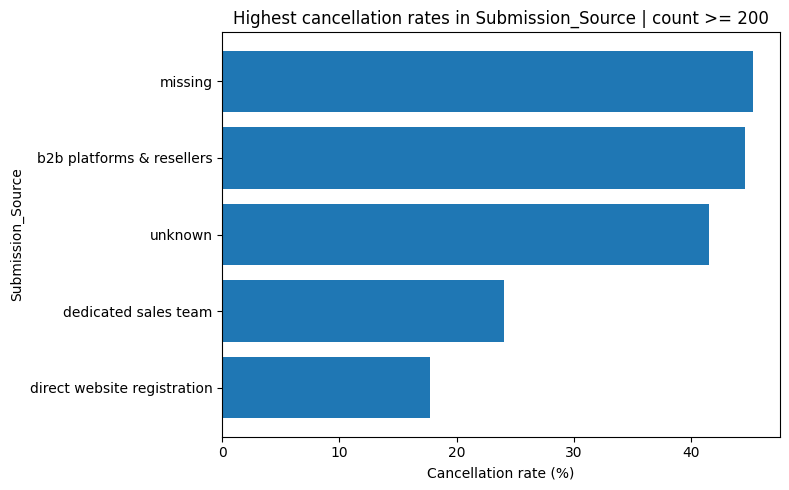

,count,drop_pct,ci_low_pct,ci_high_pct
Submission_Source,,,,
missing,790,45.32,41.88,48.80
b2b platforms & resellers,54286,44.61,44.19,45.03
unknown,224,41.52,35.26,48.06
dedicated sales team,2853,24.04,22.51,25.65
direct website registration,5164,17.74,16.72,18.80



Enrollment_Type


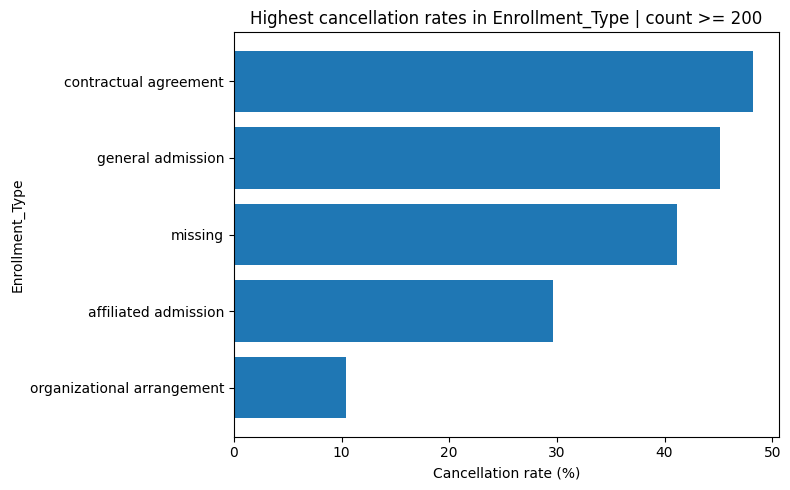

,count,drop_pct,ci_low_pct,ci_high_pct
Enrollment_Type,,,,
contractual agreement,2272,48.24,46.19,50.30
general admission,45199,45.20,44.74,45.65
missing,719,41.17,37.63,44.80
affiliated admission,15034,29.63,28.90,30.36
organizational arrangement,240,10.42,7.16,14.92



Catering_Package


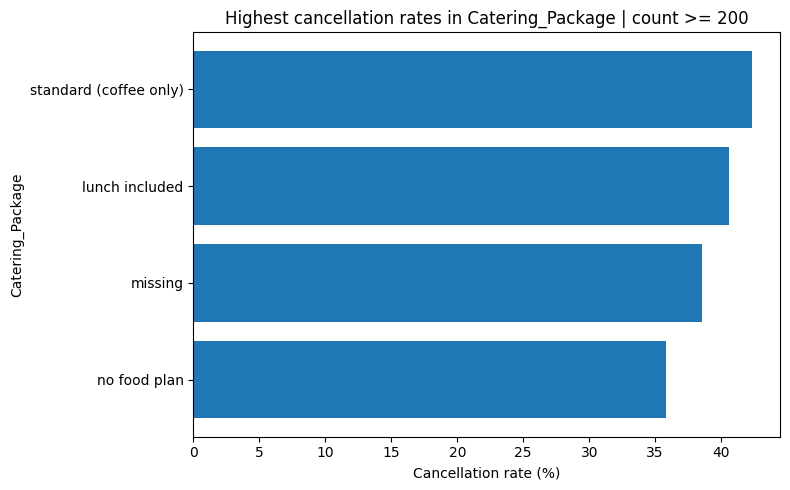

,count,drop_pct,ci_low_pct,ci_high_pct
Catering_Package,,,,
standard (coffee only),50409,42.34,41.91,42.78
lunch included,5233,40.59,39.27,41.93
missing,407,38.57,33.97,43.39
no food plan,7371,35.79,34.70,36.89



Requested_Lab_Config


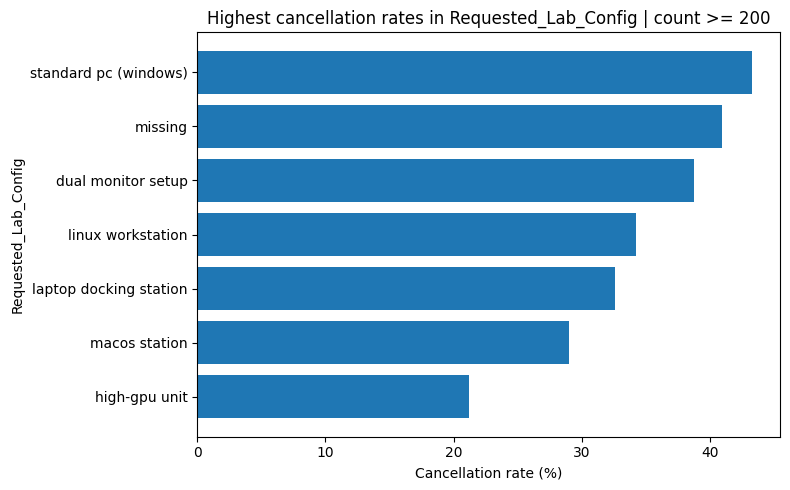

,count,drop_pct,ci_low_pct,ci_high_pct
Requested_Lab_Config,,,,
standard pc (windows),49708,43.29,42.86,43.73
missing,1736,40.96,38.67,43.29
dual monitor setup,1320,38.79,36.20,41.45
linux workstation,8390,34.20,33.19,35.22
laptop docking station,976,32.58,29.71,35.59
macos station,994,28.97,26.24,31.87
high-gpu unit,321,21.18,17.07,25.98



Assigned_Lab_Config


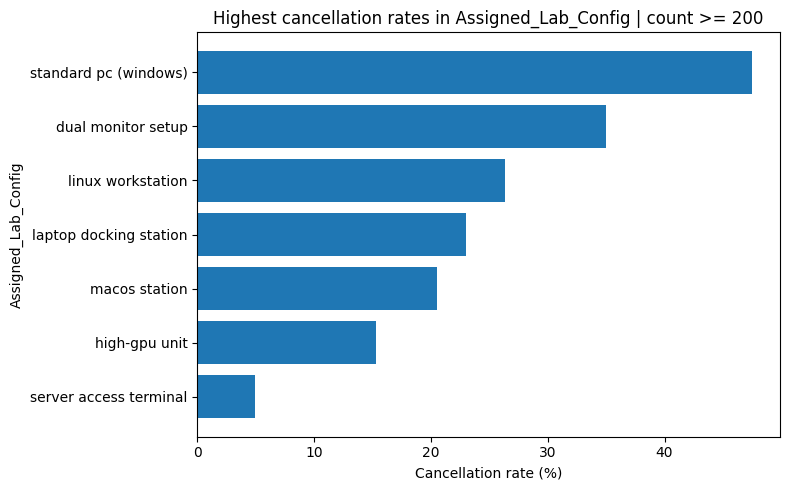

,count,drop_pct,ci_low_pct,ci_high_pct
Assigned_Lab_Config,,,,
standard pc (windows),45926,47.51,47.05,47.97
dual monitor setup,1556,34.96,32.63,37.37
linux workstation,11665,26.34,25.54,27.14
laptop docking station,1850,23.03,21.17,25.00
macos station,1591,20.49,18.58,22.54
high-gpu unit,515,15.34,12.48,18.71
server access terminal,242,4.96,2.86,8.47


In [ ]:
overall_drop_rate = df_eda[TARGET].mean() * 100
print(f"Overall cancellation/drop rate: {overall_drop_rate:.2f}%")

for col in important_cat_for_counts:
    print("\n" + "="*100)
    print(col)
    plot_category_drop_rates(df_eda, col, min_count=200, top_n=12)

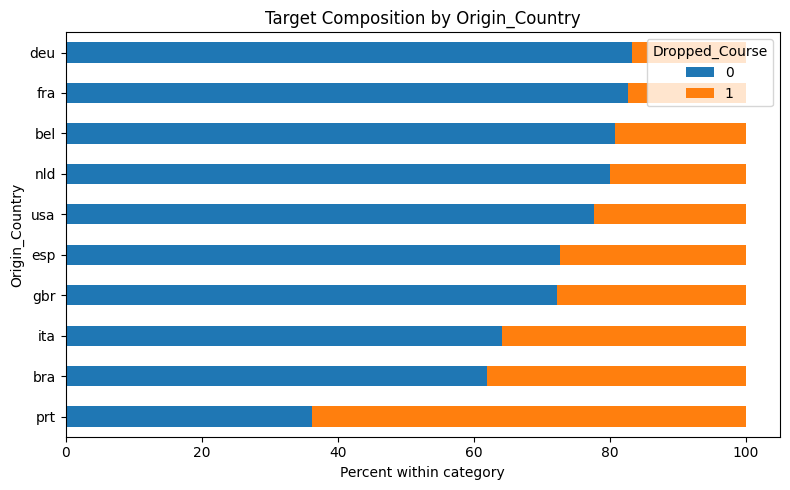

Dropped_Course,0,1
Origin_Country,,
prt,36.22,63.78
bra,61.98,38.02
ita,64.12,35.88
gbr,72.20,27.80
esp,72.69,27.31
usa,77.61,22.39
nld,80.03,19.97
bel,80.82,19.18
fra,82.72,17.28


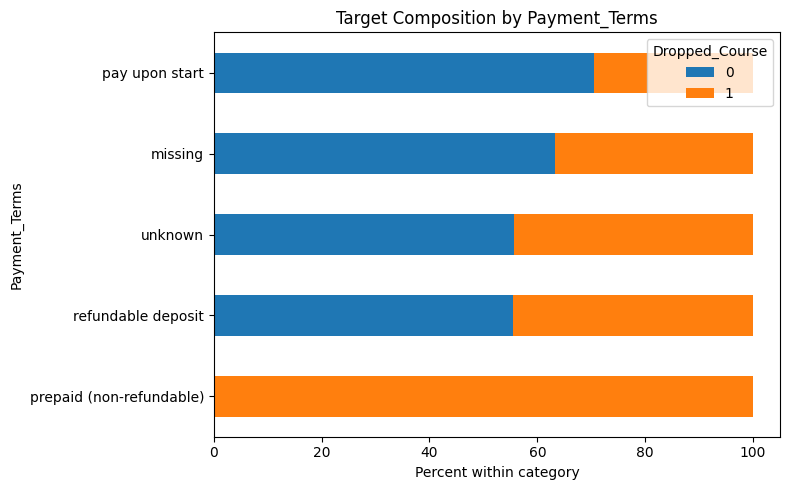

Dropped_Course,0,1
Payment_Terms,,
prepaid (non-refundable),0.22,99.78
refundable deposit,55.56,44.44
unknown,55.61,44.39
missing,63.26,36.74
pay upon start,70.56,29.44


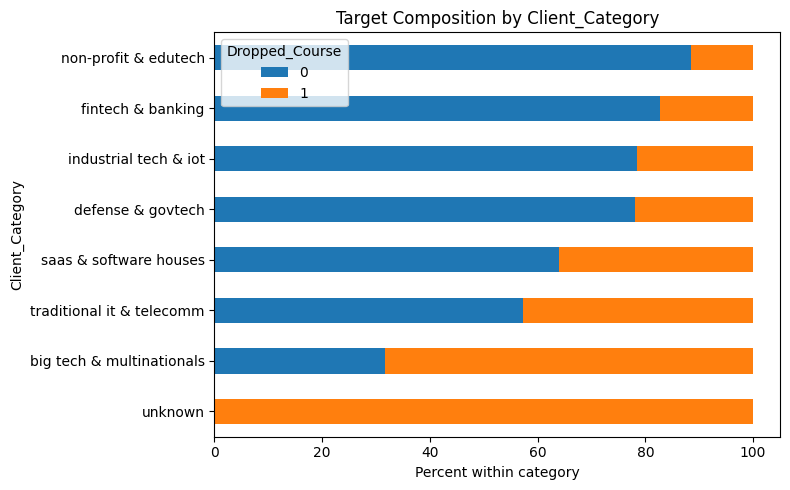

Dropped_Course,0,1
Client_Category,,
unknown,0.00,100.00
big tech & multinationals,31.63,68.37
traditional it & telecomm,57.20,42.80
saas & software houses,63.99,36.01
defense & govtech,78.05,21.95
industrial tech & iot,78.37,21.63
fintech & banking,82.75,17.25
non-profit & edutech,88.39,11.61


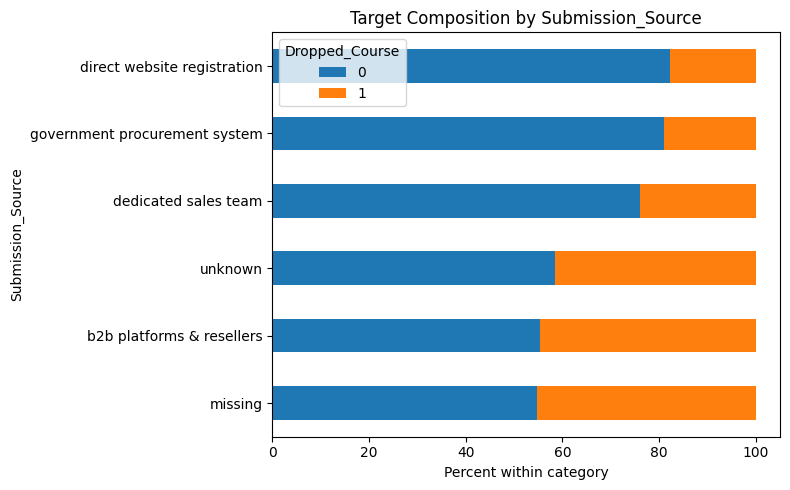

Dropped_Course,0,1
Submission_Source,,
missing,54.68,45.32
b2b platforms & resellers,55.39,44.61
unknown,58.48,41.52
dedicated sales team,75.96,24.04
government procurement system,80.95,19.05
direct website registration,82.26,17.74


In [ ]:
def plot_normalized_target_by_category(data, col, target=TARGET, top_n=10):
    tmp = data.copy()
    tmp[col] = tmp[col].fillna("missing")
    top_values = tmp[col].value_counts().head(top_n).index
    tmp = tmp[tmp[col].isin(top_values)]
    tab = pd.crosstab(tmp[col], tmp[target], normalize="index") * 100
    tab = tab.sort_values(by=1, ascending=False) if 1 in tab.columns else tab

    tab.plot(kind="barh", stacked=True, figsize=(8, 5))
    plt.title(f"Target Composition by {col}")
    plt.xlabel("Percent within category")
    plt.ylabel(col)
    plt.legend(title=target, loc="best")
    plt.tight_layout()
    plt.show()
    display(tab.round(2))

for col in important_cat_for_counts[:4]:
    plot_normalized_target_by_category(df_eda, col, top_n=10)

**Main takeaway:**  
The categorical-target analysis shows meaningful variation in cancellation rates across categories. Variables such as `Payment_Terms`, `Origin_Country`, `Client_Category`, `Submission_Source`, `Enrollment_Type` and lab-configuration variables appear informative, while variables such as `Lanyard_Color` and `Welcome_Gift_Type` appear weaker. Because several categorical variables have high cardinality, rare-category grouping is justified before one-hot encoding.

# Check 7 — Time-based and seasonality analysis

The course start date may reflect seasonal behavior, operational load, holidays, or end-of-year effects. We extract basic date features and examine cancellation rates over time.

**Visualization explanation for this section:**  
The monthly line chart shows whether cancellation rates drift over calendar time. The month, weekday, quarter, and year bar charts show whether cancellation risk is seasonal or tied to specific time periods.  

**What we learn:** if time patterns are visible, date-derived features may be useful in feature engineering.

In [ ]:
df_eda["start_year"] = df_eda["Course_Start_Date_dt"].dt.year
df_eda["start_month"] = df_eda["Course_Start_Date_dt"].dt.month
df_eda["start_dayofweek"] = df_eda["Course_Start_Date_dt"].dt.dayofweek
df_eda["start_quarter"] = df_eda["Course_Start_Date_dt"].dt.quarter
df_eda["start_year_month"] = df_eda["Course_Start_Date_dt"].dt.to_period("M").astype(str)

print("Date parse failures:", df_eda["Course_Start_Date_dt"].isna().sum())
print("Date range:", df_eda["Course_Start_Date_dt"].min(), "to", df_eda["Course_Start_Date_dt"].max())

Date parse failures: 0
Date range: 2015-07-01 00:00:00 to 2017-04-26 00:00:00


,count,mean,drop_pct
start_year_month,,,
2015-07,1398,0.67,67.17
2015-08,2480,0.50,49.68
2015-09,3529,0.44,43.72
2015-10,3386,0.39,39.01
2015-11,1235,0.24,24.37
2015-12,1654,0.40,40.39
2016-01,1364,0.32,32.11
2016-02,2371,0.39,39.22
2016-03,3046,0.36,36.38


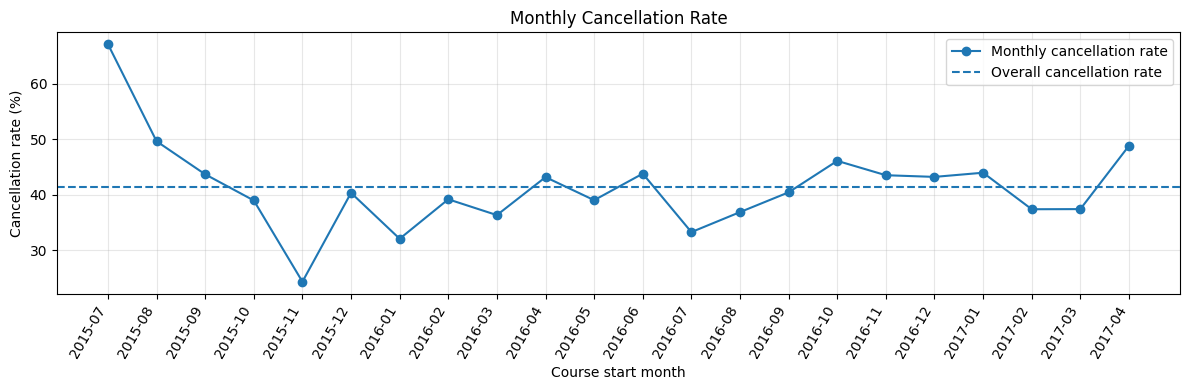

In [ ]:
monthly = df_eda.groupby("start_year_month")[TARGET].agg(["count", "mean"])
monthly["drop_pct"] = monthly["mean"] * 100
display(monthly.round(2))

plt.figure(figsize=(12, 4))
plt.plot(monthly.index, monthly["drop_pct"], marker="o", label="Monthly cancellation rate")
plt.axhline(df_eda[TARGET].mean() * 100, linestyle="--", label="Overall cancellation rate")
plt.title("Monthly Cancellation Rate")
plt.xlabel("Course start month")
plt.ylabel("Cancellation rate (%)")
plt.xticks(rotation=60, ha="right")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

,count,mean,drop_pct
start_month,,,
1,3736,0.40,39.67
2,4965,0.38,38.29
3,6458,0.37,36.95
4,6825,0.46,45.92
5,3676,0.39,39.06
6,3923,0.44,43.84
7,4529,0.44,43.76
8,5858,0.42,42.32
9,7400,0.42,42.03


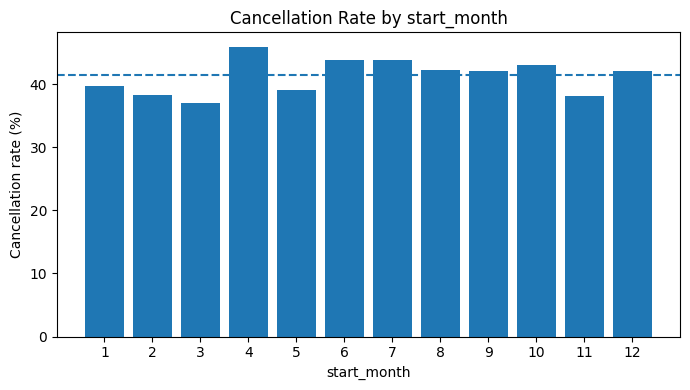

,count,mean,drop_pct
start_dayofweek,,,
0,9463,0.38,38.01
1,7101,0.37,37.45
2,9057,0.41,40.59
3,10453,0.49,49.40
4,11420,0.43,43.40
5,8639,0.43,43.15
6,7331,0.34,34.36


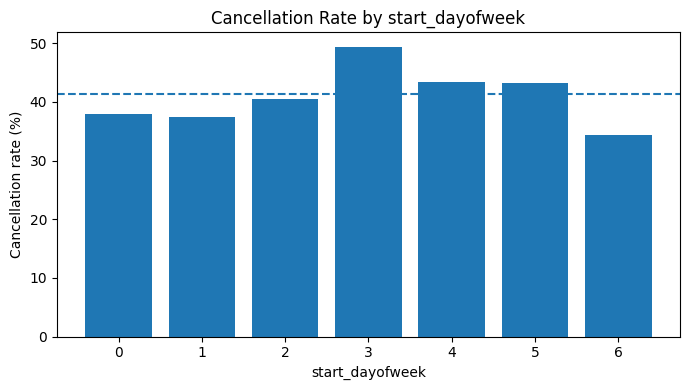

,count,mean,drop_pct
start_quarter,,,
1,15159,0.38,38.06
2,14424,0.44,43.61
3,17787,0.43,42.56
4,16094,0.41,41.44


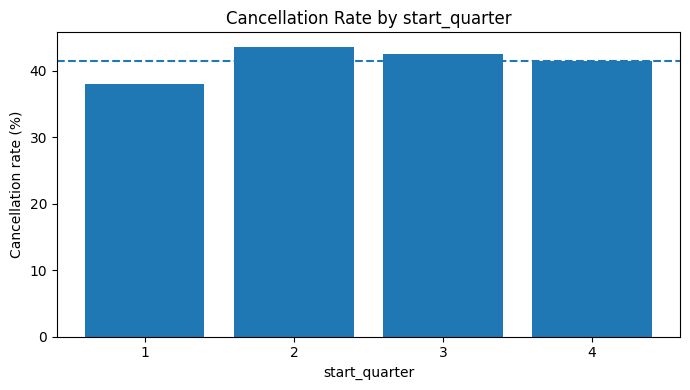

,count,mean,drop_pct
start_year,,,
2015,13682,0.44,43.88
2016,38140,0.40,40.40
2017,11642,0.42,41.99


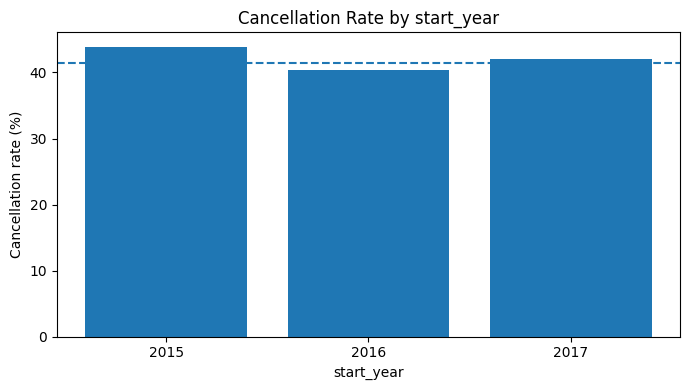

In [ ]:
for time_col in ["start_month", "start_dayofweek", "start_quarter", "start_year"]:
    tab = df_eda.groupby(time_col)[TARGET].agg(["count", "mean"])
    tab["drop_pct"] = tab["mean"] * 100
    display(tab.round(2))

    plt.figure(figsize=(7, 4))
    plt.bar(tab.index.astype(str), tab["drop_pct"])
    plt.axhline(df_eda[TARGET].mean() * 100, linestyle="--")
    plt.title(f"Cancellation Rate by {time_col}")
    plt.xlabel(time_col)
    plt.ylabel("Cancellation rate (%)")
    plt.tight_layout()
    plt.show()

**Main takeaway:**  
Date-derived variables may capture seasonality, weekday effects or operational timing patterns that are not visible from the raw course-start date alone. Therefore, extracting month, quarter, weekday and weekend indicators is justified for the modeling stage.

# Check 8 — Correlations, redundancy, and Cramer's V

This section checks whether numerical features are redundant and whether categorical variables are strongly associated with each other.

**Visualization explanation for this section:**  
The Pearson heatmap shows feature-to-feature numerical correlations and potential redundancy. The Cramér’s V heatmap shows associations between categorical variables and the target.  

**What we learn:** these plots help identify overlapping information and categorical variables that may be strongly related to cancellation.

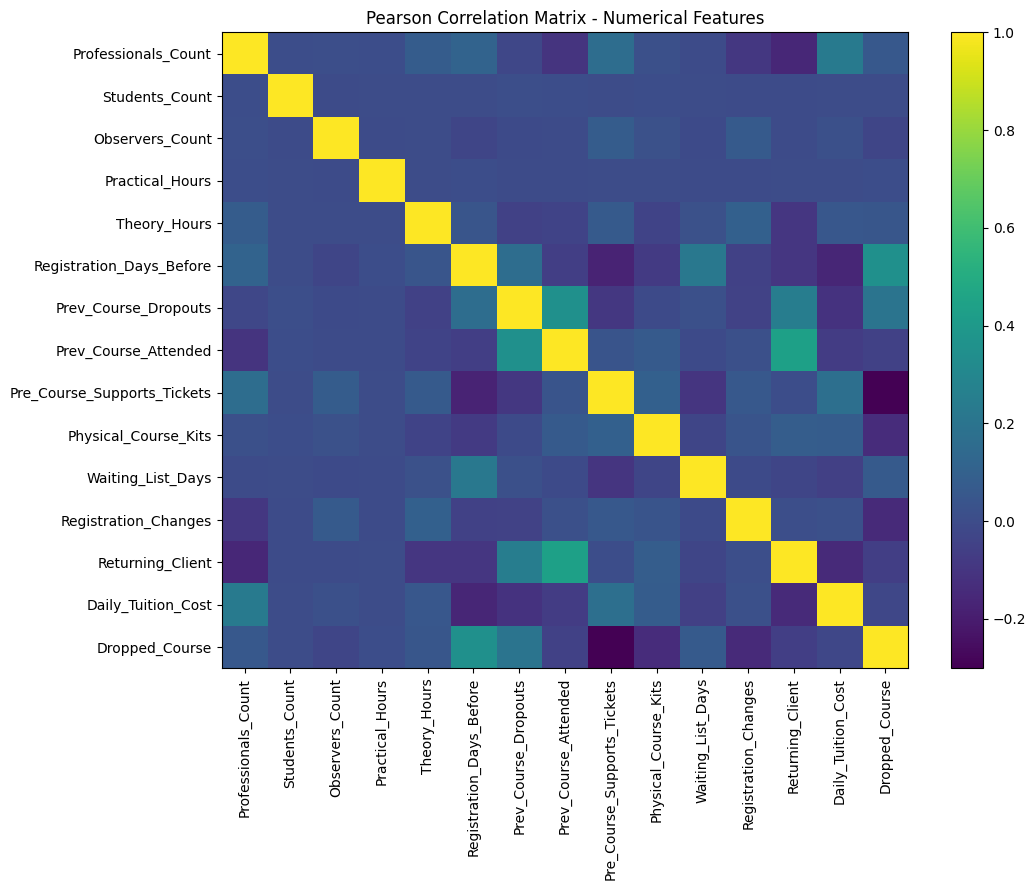

In [ ]:
num_for_corr = [c for c in numeric_non_id if df_eda[c].nunique(dropna=True) > 1]
pearson_corr = df_eda[num_for_corr + [TARGET]].corr(method="pearson", numeric_only=True)

plot_heatmap_from_df(pearson_corr, "Pearson Correlation Matrix - Numerical Features", figsize=(11, 9))

In [ ]:
corr_pairs = []
corr_abs = pearson_corr.abs()

for i, col1 in enumerate(corr_abs.columns):
    for col2 in corr_abs.columns[i+1:]:
        if col1 == TARGET or col2 == TARGET:
            continue
        val = corr_abs.loc[col1, col2]
        if val >= 0.70:
            corr_pairs.append({
                "feature_1": col1,
                "feature_2": col2,
                "abs_corr": val,
                "corr": pearson_corr.loc[col1, col2]
            })

high_corr_pairs = pd.DataFrame(corr_pairs).sort_values("abs_corr", ascending=False) if corr_pairs else pd.DataFrame(columns=["feature_1", "feature_2", "abs_corr", "corr"])
display(high_corr_pairs.round(4))

,feature_1,feature_2,abs_corr,corr


,Origin_Country,Payment_Terms,Client_Category,Submission_Source,Enrollment_Type,Catering_Package,Requested_Lab_Config,Assigned_Lab_Config,Dropped_Course
Origin_Country,1.000,0.261,0.230,0.099,0.118,0.159,0.108,0.108,0.415
Payment_Terms,0.261,1.000,0.276,0.067,0.078,0.083,0.105,0.134,0.534
Client_Category,0.230,0.276,1.000,0.576,0.237,0.219,0.162,0.131,0.299
Submission_Source,0.099,0.067,0.576,1.000,0.071,0.072,0.102,0.086,0.169
Enrollment_Type,0.118,0.078,0.237,0.071,1.000,0.148,0.106,0.079,0.141
Catering_Package,0.159,0.083,0.219,0.072,0.148,1.000,0.092,0.091,0.048
Requested_Lab_Config,0.108,0.105,0.162,0.102,0.106,0.092,1.000,0.681,0.081
Assigned_Lab_Config,0.108,0.134,0.131,0.086,0.079,0.091,0.681,1.000,0.206
Dropped_Course,0.415,0.534,0.299,0.169,0.141,0.048,0.081,0.206,1.000


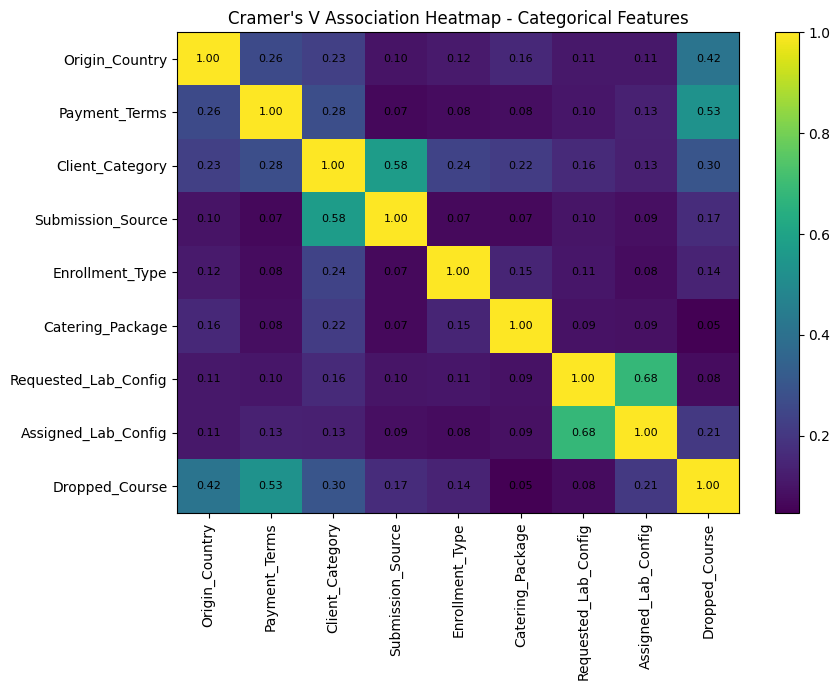

In [ ]:
if SCIPY_AVAILABLE and len(important_cat_for_counts) > 0:
    cramers_cols = important_cat_for_counts + [TARGET]
    cv_mat = pd.DataFrame(index=cramers_cols, columns=cramers_cols, dtype=float)

    for c1 in cramers_cols:
        for c2 in cramers_cols:
            cv_mat.loc[c1, c2] = cramers_v(df_eda[c1], df_eda[c2])

    display(cv_mat.round(3))
    plot_heatmap_from_df(cv_mat, "Cramer's V Association Heatmap - Categorical Features", figsize=(9, 7), annotate=True)
else:
    print("Cramer's V calculation was skipped.")

## Categorical association with the target

The heatmap above shows pairwise categorical associations. The table below focuses specifically on the association between each categorical feature and the target using Cramér’s V.

**What this table shows:** how strongly each categorical variable is associated with cancellation status.  
**What we learn:** categorical variables with higher Cramér’s V values are stronger candidates for encoding and feature engineering.

In [ ]:
if SCIPY_AVAILABLE and len(important_cat_for_counts) > 0:
    categorical_target_assoc = []
    for col in important_cat_for_counts:
        categorical_target_assoc.append({
            "feature": col,
            "cramers_v_with_target": cramers_v(df_eda[col], df_eda[TARGET]),
            "n_categories": df_eda[col].nunique(dropna=True),
            "missing_pct": df_eda[col].isna().mean() * 100
        })
    categorical_target_assoc = pd.DataFrame(categorical_target_assoc).sort_values("cramers_v_with_target", ascending=False)
    display(categorical_target_assoc.round(4))
else:
    print("Cramér's V table skipped because scipy is unavailable or no categorical features were selected.")

,feature,cramers_v_with_target,n_categories,missing_pct
1,Payment_Terms,0.5338,4,1.2480
0,Origin_Country,0.4152,154,0.8777
2,Client_Category,0.2989,8,0.0000
7,Assigned_Lab_Config,0.2061,9,0.0000
3,Submission_Source,0.1689,5,1.2448
4,Enrollment_Type,0.1412,4,1.1329
6,Requested_Lab_Config,0.0809,8,2.7354
5,Catering_Package,0.0475,4,0.6413


**Main takeaway:**  
The categorical-association analysis supports the conclusion that not all categorical variables carry the same predictive value. Business-relevant categorical fields should be preserved, but dimensionality should be controlled through rare-category grouping so that rare one-off values do not create many unstable one-hot columns.

# Check 9 — Interaction analysis between important features

A single feature may not tell the whole story. Sometimes a combination of two variables reveals a much stronger pattern than either variable alone.

**Visualization explanation for this section:**  
The interaction heatmaps show cancellation rates for combinations of two features, such as registration timing combined with payment terms or returning-client status.  

**What we learn:** if a specific combination has a particularly high cancellation rate, it may justify creating interaction features in Stage B.

,count,mean,drop_pct
registration_days_bin,,,
0,2610,0.08,8.24
1-7,6457,0.14,13.78
8-14,3737,0.25,25.13
15-30,6335,0.34,33.94
31-60,9953,0.39,38.79
61-90,7379,0.42,41.85
91-120,5493,0.47,47.06
121-180,6798,0.47,47.19
181-365,10383,0.65,65.38


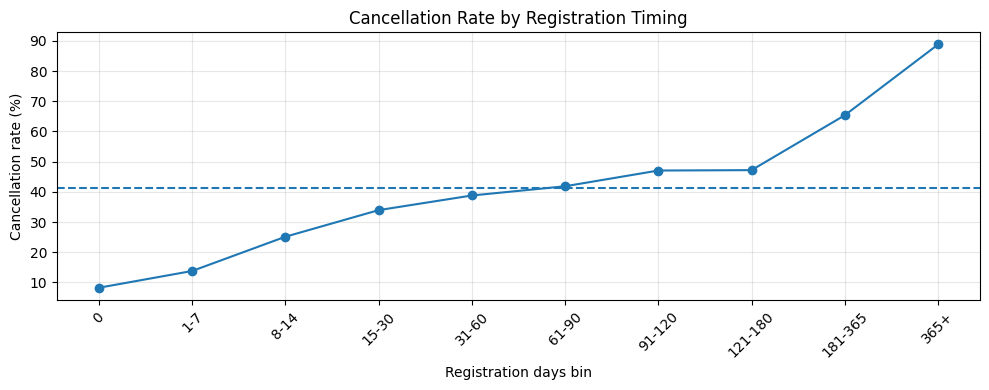

In [ ]:
registration_days_col = first_existing(["Registration_Days_Before", "Before_Days_Registration"], df_eda)

if registration_days_col is not None:
    df_eda["registration_days_bin"] = pd.cut(
        df_eda[registration_days_col],
        bins=[-1, 0, 7, 14, 30, 60, 90, 120, 180, 365, np.inf],
        labels=["0", "1-7", "8-14", "15-30", "31-60", "61-90", "91-120", "121-180", "181-365", "365+"],
        include_lowest=True
    )

    reg_bin = df_eda.groupby("registration_days_bin", observed=False)[TARGET].agg(["count", "mean"])
    reg_bin["drop_pct"] = reg_bin["mean"] * 100
    display(reg_bin.round(2))

    plt.figure(figsize=(10, 4))
    plt.plot(reg_bin.index.astype(str), reg_bin["drop_pct"], marker="o")
    plt.axhline(df_eda[TARGET].mean() * 100, linestyle="--")
    plt.title("Cancellation Rate by Registration Timing")
    plt.xlabel("Registration days bin")
    plt.ylabel("Cancellation rate (%)")
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No registration-days column found.")

Payment_Terms,missing,pay upon start,prepaid (non-refundable),refundable deposit,unknown
registration_days_bin,,,,,
0,NaN,8.39,NaN,NaN,NaN
1-7,8.00,13.27,NaN,NaN,NaN
121-180,NaN,35.08,99.68,NaN,NaN
15-30,NaN,29.87,99.46,NaN,NaN
181-365,64.62,42.12,99.90,NaN,NaN
31-60,31.58,32.95,99.88,NaN,NaN
365+,NaN,18.55,100.00,NaN,NaN
61-90,NaN,31.13,99.65,NaN,NaN
8-14,NaN,24.37,NaN,NaN,NaN


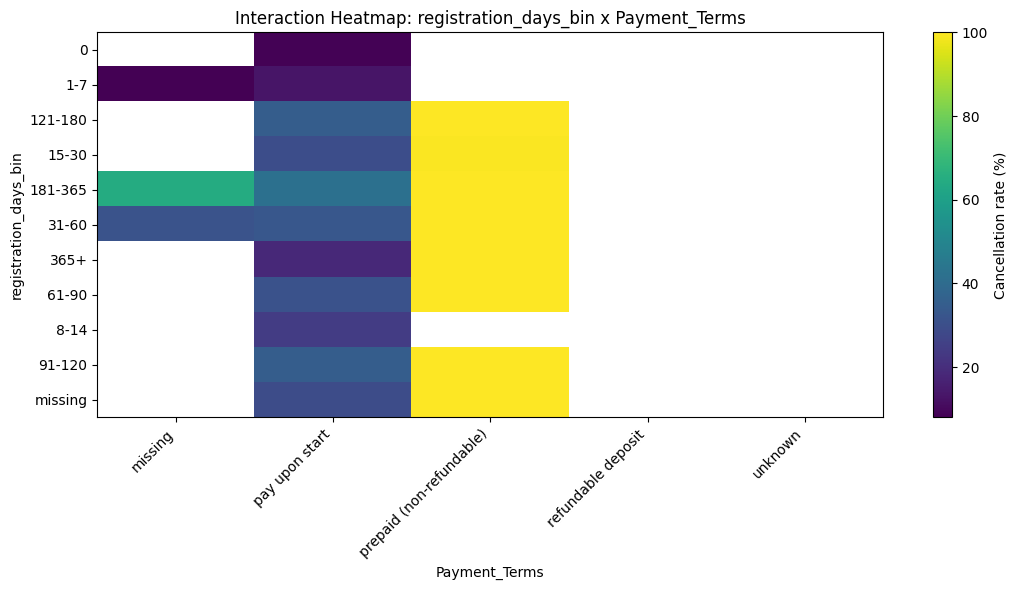

Returning_Client,0,1
registration_days_bin,,
0,8.22,8.30
1-7,14.08,10.81
121-180,47.20,NaN
15-30,33.79,39.51
181-365,64.72,99.49
31-60,38.88,NaN
365+,88.81,NaN
61-90,41.92,NaN
8-14,25.59,13.70


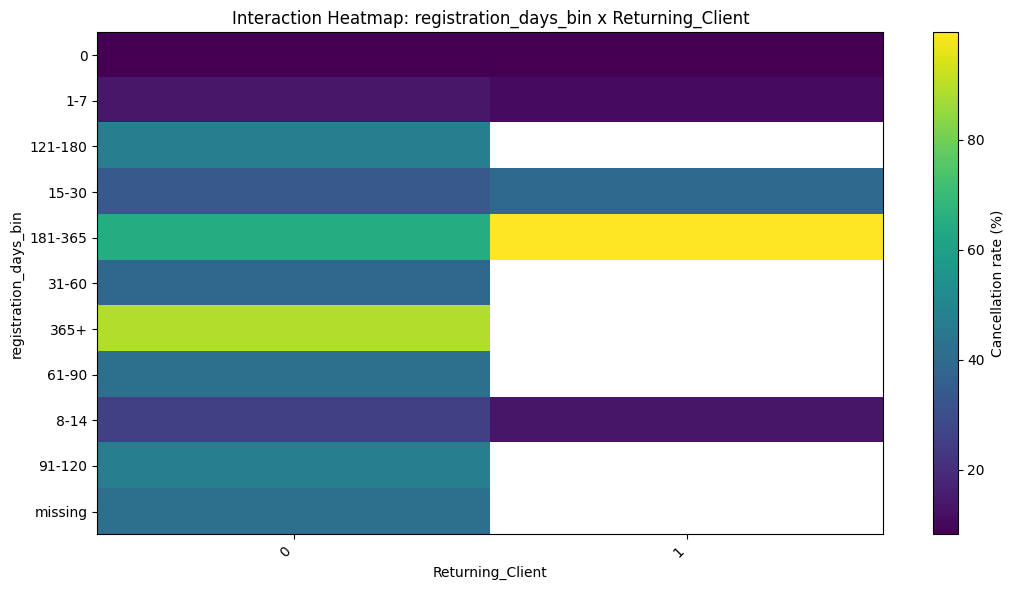

Origin_Country,bel,bra,deu,esp,fra,gbr,ita,prt
registration_days_bin,,,,,,,,
0,NaN,NaN,4.88,1.57,2.48,NaN,NaN,12.00
1-7,5.41,13.48,5.59,9.83,4.60,7.69,8.57,20.28
121-180,26.11,48.09,20.94,47.24,22.96,34.63,46.21,70.02
15-30,15.15,29.38,16.12,29.13,18.04,23.50,27.12,52.11
181-365,22.56,78.15,17.65,57.25,21.71,35.81,31.23,89.59
31-60,22.76,34.44,17.77,28.27,17.84,29.39,38.20,60.92
365+,NaN,NaN,0.65,NaN,NaN,NaN,NaN,99.18
61-90,17.99,40.48,20.55,31.03,19.16,30.67,41.78,67.76
8-14,14.13,30.11,15.34,20.32,14.81,31.42,28.16,31.93


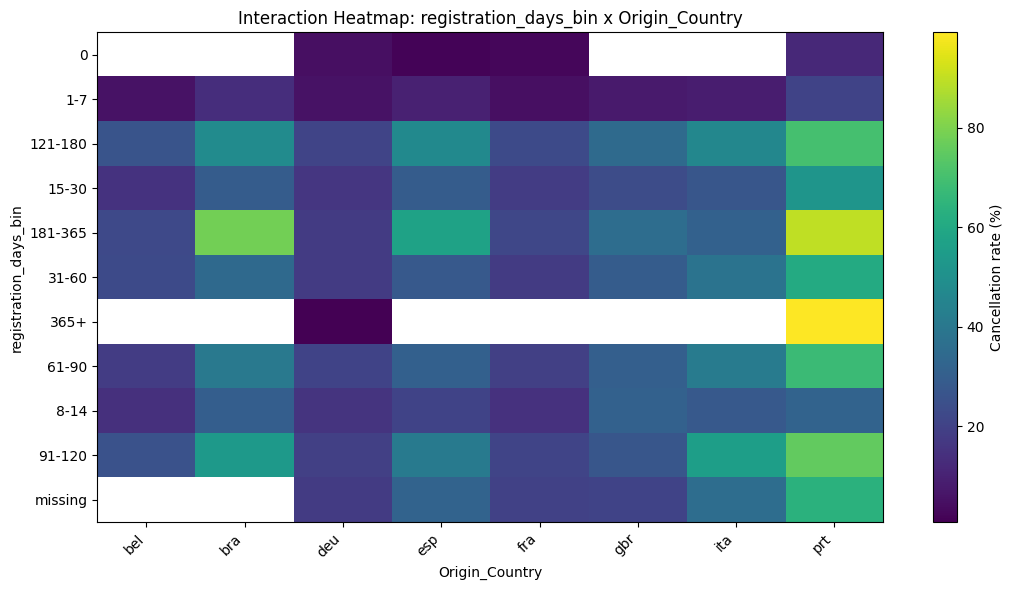

In [ ]:
def plot_interaction_heatmap(data, row_feature, col_feature, target=TARGET, min_count=50, top_cols=8):
    tmp = data[[row_feature, col_feature, target]].copy()
    tmp[row_feature] = tmp[row_feature].astype("object").fillna("missing")
    tmp[col_feature] = tmp[col_feature].astype("object").fillna("missing")

    top_values = tmp[col_feature].value_counts().head(top_cols).index
    tmp = tmp[tmp[col_feature].isin(top_values)]

    counts = pd.pivot_table(tmp, index=row_feature, columns=col_feature, values=target, aggfunc="count", observed=False)
    rates = pd.pivot_table(tmp, index=row_feature, columns=col_feature, values=target, aggfunc="mean", observed=False) * 100
    rates_masked = rates.where(counts >= min_count)

    display(rates_masked.round(2))

    plt.figure(figsize=(11, 6))
    plt.imshow(rates_masked, aspect="auto")
    plt.colorbar(label="Cancellation rate (%)")
    plt.xticks(range(len(rates_masked.columns)), rates_masked.columns.astype(str), rotation=45, ha="right")
    plt.yticks(range(len(rates_masked.index)), rates_masked.index.astype(str))
    plt.title(f"Interaction Heatmap: {row_feature} x {col_feature}")
    plt.xlabel(col_feature)
    plt.ylabel(row_feature)
    plt.tight_layout()
    plt.show()

    return rates_masked, counts

payment_col = first_existing(["Payment_Terms", "Terms_Payment"], df_eda)
returning_col = first_existing(["Returning_Client", "Client_Returning"], df_eda)
country_col = first_existing(["Origin_Country", "Country_Origin"], df_eda)

if "registration_days_bin" in df_eda.columns and payment_col is not None:
    plot_interaction_heatmap(df_eda, "registration_days_bin", payment_col, min_count=100, top_cols=8)

if "registration_days_bin" in df_eda.columns and returning_col is not None:
    plot_interaction_heatmap(df_eda, "registration_days_bin", returning_col, min_count=100, top_cols=2)

if "registration_days_bin" in df_eda.columns and country_col is not None:
    plot_interaction_heatmap(df_eda, "registration_days_bin", country_col, min_count=80, top_cols=8)

**Main takeaway:**  
The interaction analysis suggests that cancellation risk may depend on combinations of variables, not only on isolated one-dimensional effects. This supports the use of tree-based models such as Random Forest and XGBoost, because they can capture interactions between registration timing, client segment, payment terms and operational features.

# Check 10 — Initial feature screening: Mutual Information, univariate AUC, and Lift charts

These tools are not a final model, but they help identify promising features:

- **Mutual Information** captures general dependency, not only linear relationships.
- **Univariate AUC** checks how well a single numerical feature ranks cancellation risk.
- **Lift charts** show whether high-risk groups are truly more concentrated with cancellations than the overall baseline.

**Visualization explanation for this section:**  
The Mutual Information chart ranks features by non-linear dependency with the target. The univariate AUC chart ranks numerical features by their ability to separate cancelled from non-cancelled observations. The lift charts show whether high-risk deciles are truly riskier than the overall population.  

**What we learn:** these are particularly useful because the final project is evaluated using AUC, which rewards good ranking of high-risk observations.

,feature,mutual_information
25,Payment_Terms,0.1709
6,Registration_Days_Before,0.1103
26,Daily_Tuition_Cost,0.0956
23,Agent_ID,0.0904
7,Origin_Country,0.0903
32,registration_days_bin,0.0679
12,Prev_Course_Dropouts,0.0662
14,Pre_Course_Supports_Tickets,0.0614
20,Client_Category,0.0460
16,Waiting_List_Days,0.0267


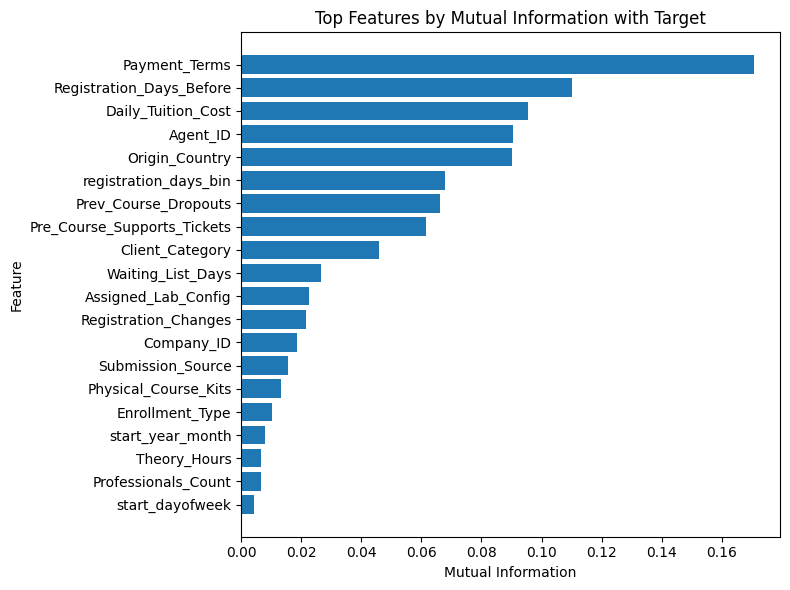

In [ ]:
X_mi = df_eda.drop(columns=[TARGET]).copy()

for col in date_cols + ["Course_Start_Date_dt"]:
    if col in X_mi.columns:
        X_mi = X_mi.drop(columns=[col])

cat_for_mi = X_mi.select_dtypes(include=["object", "category"]).columns.tolist()
num_for_mi = X_mi.select_dtypes(include=np.number).columns.tolist()

if num_for_mi:
    X_mi[num_for_mi] = SimpleImputer(strategy="median").fit_transform(X_mi[num_for_mi])

if cat_for_mi:
    X_mi[cat_for_mi] = SimpleImputer(strategy="constant", fill_value="unknown").fit_transform(X_mi[cat_for_mi])
    X_mi[cat_for_mi] = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit_transform(X_mi[cat_for_mi])

discrete_mask = [
    col in cat_for_mi or col in ["start_year", "start_month", "start_dayofweek", "start_quarter"]
    for col in X_mi.columns
]

mi_mask = df_eda.loc[X_mi.index, TARGET].notna()

X_mi_clean = X_mi.loc[mi_mask].copy()
y_mi_clean = df_eda.loc[X_mi_clean.index, TARGET].astype(int)

mi_values = mutual_info_classif(
    X_mi_clean,
    y_mi_clean,
    discrete_features=discrete_mask,
    random_state=42
)

mi_table = pd.DataFrame({
    "feature": X_mi.columns,
    "mutual_information": mi_values
}).sort_values("mutual_information", ascending=False)

display(mi_table.head(25).round(4))

top_mi = mi_table.head(20).sort_values("mutual_information")
plt.figure(figsize=(8, 6))
plt.barh(top_mi["feature"], top_mi["mutual_information"])
plt.title("Top Features by Mutual Information with Target")
plt.xlabel("Mutual Information")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


,feature,auc_raw,auc_effective_direction_free
5,Registration_Days_Before,0.7060,0.7060
8,Pre_Course_Supports_Tickets,0.3318,0.6682
6,Prev_Course_Dropouts,0.5910,0.5910
11,Registration_Changes,0.4348,0.5652
13,Daily_Tuition_Cost,0.4684,0.5316
10,Waiting_List_Days,0.5284,0.5284
0,Professionals_Count,0.5275,0.5275
4,Theory_Hours,0.5231,0.5231
9,Physical_Course_Kits,0.4776,0.5224
7,Prev_Course_Attended,0.4859,0.5141


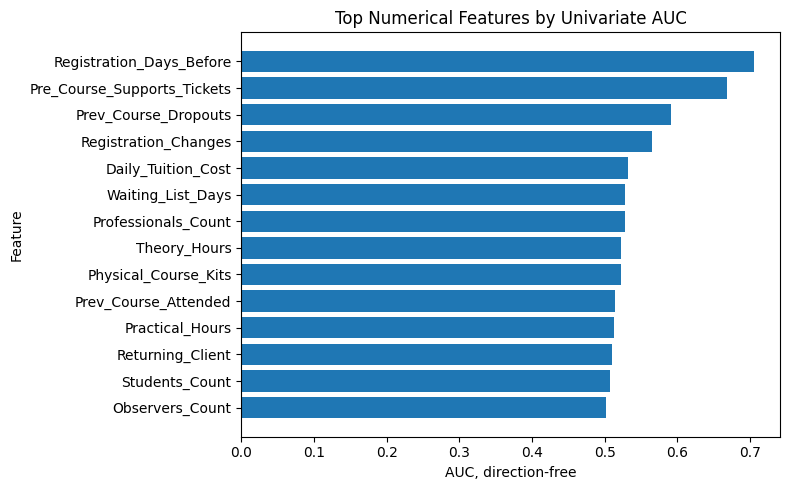

In [ ]:
# Univariate AUC for numeric features — safe version without missing target values

from sklearn.metrics import roc_auc_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

auc_rows = []

# Keep only rows with a non-missing target
target_mask = df_eda[TARGET].notna()

for col in numeric_non_id:
    if col == TARGET:
        continue

    if col not in df_eda.columns:
        continue

    temp = df_eda.loc[target_mask, [col, TARGET]].copy()
    temp[col] = pd.to_numeric(temp[col], errors="coerce")
    temp = temp.dropna(subset=[col, TARGET])

    if temp.shape[0] <= 1:
        continue

    y = temp[TARGET].astype(int).values
    x = temp[col].fillna(temp[col].median()).values

    if len(np.unique(y)) < 2:
        continue

    try:
        auc = roc_auc_score(y, x)
        auc_effective = max(auc, 1 - auc)

        auc_rows.append({
            "feature": col,
            "auc_raw": auc,
            "auc_effective_direction_free": auc_effective
        })
    except Exception as e:
        print(f"Skipped {col}: {e}")

auc_table = pd.DataFrame(auc_rows)

if auc_table.empty:
    print("No valid numeric features were available for univariate AUC calculation.")
else:
    auc_table = auc_table.sort_values("auc_effective_direction_free", ascending=False)
    display(auc_table.round(4))

    top_auc = auc_table.head(15).sort_values("auc_effective_direction_free")

    plt.figure(figsize=(8, 5))
    plt.barh(top_auc["feature"], top_auc["auc_effective_direction_free"])
    plt.title("Top Numerical Features by Univariate AUC")
    plt.xlabel("AUC, direction-free")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


Registration_Days_Before


,count,mean,drop_pct,lift_vs_overall
score_bin,,,,
D1,6080,0.823,82.286,1.986
D2,6080,0.545,54.539,1.316
D3,6080,0.478,47.763,1.153
D4,6079,0.464,46.356,1.119
D5,6080,0.421,42.072,1.015
D6,6080,0.391,39.095,0.943
D7,6079,0.385,38.543,0.930
D8,6080,0.326,32.599,0.787
D9,6080,0.205,20.526,0.495


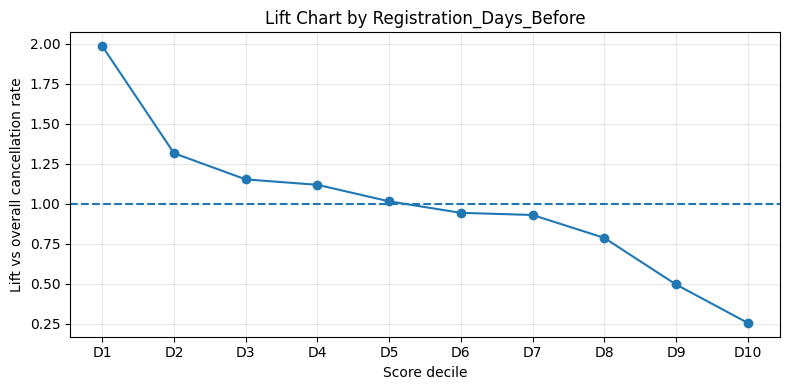


Pre_Course_Supports_Tickets
Pre_Course_Supports_Tickets: too few unique values for 10 bins.

Prev_Course_Dropouts


,count,mean,drop_pct,lift_vs_overall
score_bin,,,,
D1,6347,0.844,84.449,2.038
D2,6346,0.237,23.684,0.572
D3,6346,0.229,22.881,0.552
D4,6347,0.379,37.860,0.914
D5,6346,0.408,40.750,0.983
D6,6346,0.349,34.904,0.842
D7,6347,0.417,41.689,1.006
D8,6346,0.438,43.839,1.058
D9,6346,0.418,41.837,1.010


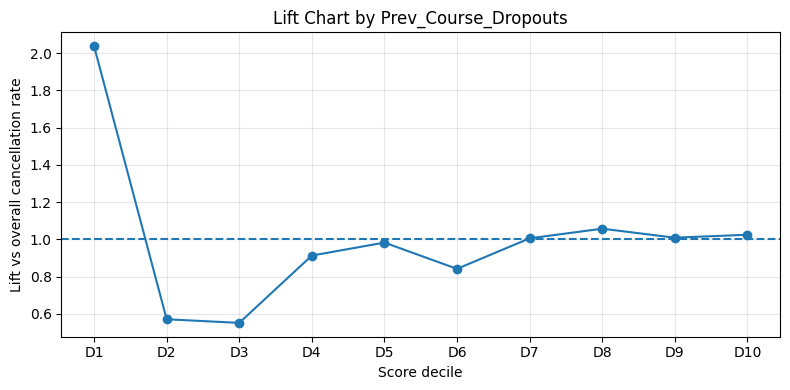


Registration_Changes


,count,mean,drop_pct,lift_vs_overall
score_bin,,,,
D1,6347,0.548,54.829,1.323
D2,6346,0.392,39.190,0.946
D3,6346,0.415,41.475,1.001
D4,6347,0.450,44.950,1.085
D5,6346,0.406,40.561,0.979
D6,6346,0.444,44.374,1.071
D7,6347,0.488,48.842,1.179
D8,6346,0.445,44.469,1.073
D9,6346,0.388,38.796,0.936


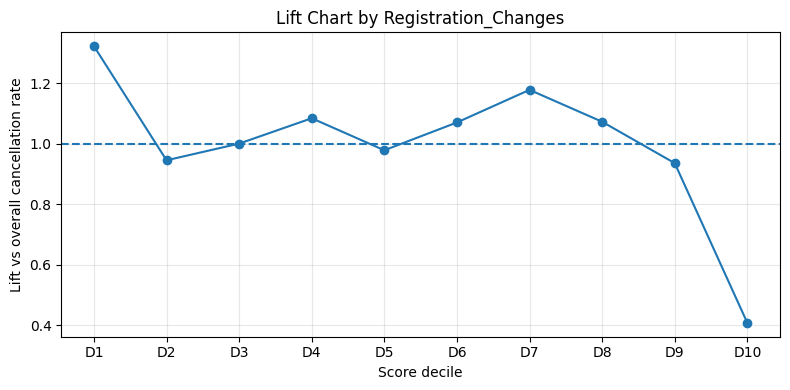

In [ ]:
def plot_lift_by_score(data, score_col, target=TARGET, n_bins=10, ascending=False):
    tmp = data[[score_col, target]].dropna().copy()
    if tmp[score_col].nunique() < n_bins:
        print(f"{score_col}: too few unique values for {n_bins} bins.")
        return None

    tmp["score_bin"] = pd.qcut(
        tmp[score_col].rank(method="first", ascending=ascending),
        q=n_bins,
        labels=[f"D{i}" for i in range(1, n_bins+1)]
    )

    tab = tmp.groupby("score_bin", observed=False)[target].agg(["count", "mean"])
    tab["drop_pct"] = tab["mean"] * 100
    tab["lift_vs_overall"] = tab["mean"] / data[target].mean()

    display(tab.round(3))

    plt.figure(figsize=(8, 4))
    plt.plot(tab.index.astype(str), tab["lift_vs_overall"], marker="o")
    plt.axhline(1, linestyle="--")
    plt.title(f"Lift Chart by {score_col}")
    plt.xlabel("Score decile")
    plt.ylabel("Lift vs overall cancellation rate")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return tab

lift_candidates = [
    ("Registration_Days_Before", False),
    ("Before_Days_Registration", False),
    ("Pre_Course_Supports_Tickets", True),
    ("Tickets_Supports_Course_Pre", True),
    ("Prev_Course_Dropouts", False),
    ("Dropouts_Course_Prev", False),
    ("Registration_Changes", True),
    ("Changes_Registration", True),
]

for score_col, asc in lift_candidates:
    if score_col in df_eda.columns:
        print("\n" + "="*100)
        print(score_col)
        plot_lift_by_score(df_eda, score_col, ascending=asc)

**Main takeaway:**  
The initial feature-screening results identify variables with useful ranking power for AUC-based prediction. Features should not be removed only because they have weak linear correlation with the target. Instead, the tuned models should evaluate them inside a leakage-safe preprocessing pipeline.

## Implications for AUC-oriented modeling

The project is evaluated using AUC rather than a single fixed-threshold accuracy measure. Therefore, the most useful EDA findings are those that help the model **rank** cancelled registrations above non-cancelled registrations.

Practical implications:

1. Features with strong univariate AUC or lift are useful candidates because they already provide ranking power.
2. Features with non-linear relationships should not be discarded only because Pearson correlation is low.
3. Categorical variables with high target association should be encoded carefully, while avoiding leakage.
4. In the modeling stage, evaluation should use `roc_auc_score` and predictions should generally be probabilities, e.g. `predict_proba(X)[:, 1]`, rather than hard 0/1 labels.

## Interim summary — main EDA insights and implications for modeling

The exploratory analysis shows that the dataset contains a meaningful cancellation rate of approximately 41%, so the target variable is not extremely imbalanced. For this reason, ROC-AUC is an appropriate central evaluation metric: the business goal is not only to classify observations at a fixed threshold, but to rank course orders according to their cancellation risk.

The missing-value analysis shows that missingness is not uniform across the dataset. `Company_ID` has very high missingness, while `Agent_ID`, `Registration_Days_Before`, `Requested_Lab_Config` and several business-related variables also contain missing values. Because missingness may reflect real operational or business patterns, missingness indicators should be preserved rather than treating all missing values as purely technical noise.

Several numerical variables show a meaningful relationship with the target. Registration timing, previous cancellation behavior, support activity, registration changes and the number of physical kits all appear relevant for predicting cancellation risk.

The categorical analysis shows that several variables have high cardinality, including country, client category, submission source, payment terms and catering package. Therefore, the modeling stage should avoid naive one-hot encoding of all raw categories. Instead, rare categories should be grouped before encoding in order to reduce sparsity and improve generalization.

Based on the EDA, the main feature-engineering decisions for the modeling stage are:

1. create registration-timing features;
2. create previous-client behavior features;
3. create operational-friction indicators;
4. create participant and course-size features;
5. create lab-configuration mismatch features;
6. preserve informative missingness indicators;
7. group rare categorical values to reduce dimensionality.

# Missing-value imputation strategy

This section documents and applies the missing-value imputation strategy based on the EDA findings. The strategy distinguishes between numerical variables, categorical variables, count-like variables and administrative ID variables.

In addition, for variables where missingness may contain business information, missingness-indicator features are created before imputation. This allows the model to learn from the fact that a value was missing, rather than only from the imputed value itself.

The modeling stage later performs imputation again inside sklearn pipelines, fitted only on the training data. This keeps the final modeling process leakage-safe while still documenting the imputation logic required in Stage A.

## Imputation decision table

Before performing imputation, we explicitly define the reasoning behind each decision. This is important because the project instructions require the missing-value completion process to be well justified.

**What this table shows:** the proposed imputation method for each feature group and the logic behind it.  
**What we learn:** missing values should not all be treated the same. IDs, categorical variables, continuous numerical variables, and count variables require different logic.

In [ ]:
imputation_decisions = []

for col in df_eda.columns:
    if col == TARGET or df_eda[col].isna().sum() == 0:
        continue

    missing_pct = df_eda[col].isna().mean() * 100

    if col in ["Company_ID", "ID_Company", "Agent_ID", "ID_Agent"]:
        method = "missing indicator + sentinel value -1"
        justification = "This is an identifier, so mean/median imputation has no numerical meaning. Missingness may also indicate a different business process."
    elif pd.api.types.is_numeric_dtype(df_eda[col]):
        if col in ["Students_Count", "Count_Students", "Physical_Course_Kits", "Kits_Course_Physical"]:
            method = "mode imputation"
            justification = "This is a count-like variable with a dominant common value; mode preserves the most typical category/count."
        else:
            method = "median imputation + optional missing indicator"
            justification = "The feature is numerical and may be skewed or contain outliers, so median is more robust than mean."
    else:
        method = "fill with 'unknown' category"
        justification = "For categorical variables, missingness can be treated as its own category rather than forcing an arbitrary existing category."

    imputation_decisions.append({
        "feature": col,
        "missing_pct": missing_pct,
        "recommended_method": method,
        "justification": justification
    })

imputation_decisions = pd.DataFrame(imputation_decisions).sort_values("missing_pct", ascending=False)
display(imputation_decisions.round(3))

,feature,missing_pct,recommended_method,justification
9,Company_ID,95.084,missing indicator + sentinel value -1,"This is an identifier, so mean/median imputati..."
8,Agent_ID,17.605,missing indicator + sentinel value -1,"This is an identifier, so mean/median imputati..."
12,registration_days_bin,4.201,fill with 'unknown' category,"For categorical variables, missingness can be ..."
1,Registration_Days_Before,4.201,median imputation + optional missing indicator,The feature is numerical and may be skewed or ...
4,Requested_Lab_Config,2.735,fill with 'unknown' category,"For categorical variables, missingness can be ..."
5,Physical_Course_Kits,1.639,mode imputation,This is a count-like variable with a dominant ...
10,Payment_Terms,1.248,fill with 'unknown' category,"For categorical variables, missingness can be ..."
7,Submission_Source,1.245,fill with 'unknown' category,"For categorical variables, missingness can be ..."
6,Enrollment_Type,1.133,fill with 'unknown' category,"For categorical variables, missingness can be ..."
2,Origin_Country,0.878,fill with 'unknown' category,"For categorical variables, missingness can be ..."


In [ ]:
df_imputed = df_eda.copy()

# 1. Missingness indicators for variables where missingness may carry information.
possible_missing_indicator_cols = [
    "Company_ID", "ID_Company",
    "Agent_ID", "ID_Agent",
    "Daily_Tuition_Cost", "Cost_Tuition_Daily",
    "Students_Count", "Count_Students",
    "Registration_Days_Before", "Before_Days_Registration"
]

for col in existing(possible_missing_indicator_cols, df_imputed):
    df_imputed[f"{col}_is_missing"] = df_imputed[col].isna().astype(int)

# 2. Missing IDs: do not impute with an average; use a sentinel value.
for col in existing(["Company_ID", "ID_Company", "Agent_ID", "ID_Agent"], df_imputed):
    df_imputed[col] = df_imputed[col].fillna(-1)

# 3. Categorical variables: fill with "unknown".
categorical_to_fill_unknown = [
    "Origin_Country", "Country_Origin",
    "Catering_Package", "Package_Catering",
    "Welcome_Gift_Type", "Type_Gift_Welcome",
    "Requested_Lab_Config", "Config_Lab_Requested",
    "Assigned_Lab_Config", "Config_Lab_Assigned",
    "Enrollment_Type", "Type_Enrollment",
    "Lanyard_Color", "Color_Lanyard",
    "Client_Category", "Category_Client",
    "Submission_Source", "Source_Submission",
    "Payment_Terms", "Terms_Payment"
]

for col in existing(categorical_to_fill_unknown, df_imputed):
    df_imputed[col] = df_imputed[col].fillna("unknown")

# 4. Numerical variables: median for continuous/skewed variables, mode for count-like variables with a dominant value.
median_fill_cols = [
    "Registration_Days_Before", "Before_Days_Registration",
    "Daily_Tuition_Cost", "Cost_Tuition_Daily",
    "Professionals_Count", "Count_Professionals",
    "Observers_Count", "Count_Observers",
    "Practical_Hours", "Hours_Practical",
    "Theory_Hours", "Hours_Theory",
    "Pre_Course_Supports_Tickets", "Tickets_Supports_Course_Pre",
    "Waiting_List_Days", "Days_List_Waiting",
    "Registration_Changes", "Changes_Registration"
]

for col in existing(median_fill_cols, df_imputed):
    df_imputed[col] = df_imputed[col].fillna(df_imputed[col].median())

mode_fill_cols = [
    "Students_Count", "Count_Students",
    "Physical_Course_Kits", "Kits_Course_Physical",
    "Prev_Course_Dropouts", "Dropouts_Course_Prev",
    "Prev_Course_Attended", "Attended_Course_Prev",
    "Returning_Client", "Client_Returning"
]

for col in existing(mode_fill_cols, df_imputed):
    if df_imputed[col].isna().sum() > 0:
        df_imputed[col] = df_imputed[col].fillna(df_imputed[col].mode(dropna=True).iloc[0])

print("Remaining missing values:", df_imputed.isna().sum().sum())
display(df_imputed.isna().sum()[df_imputed.isna().sum() > 0])

Remaining missing values: 2666


,0
registration_days_bin,2666


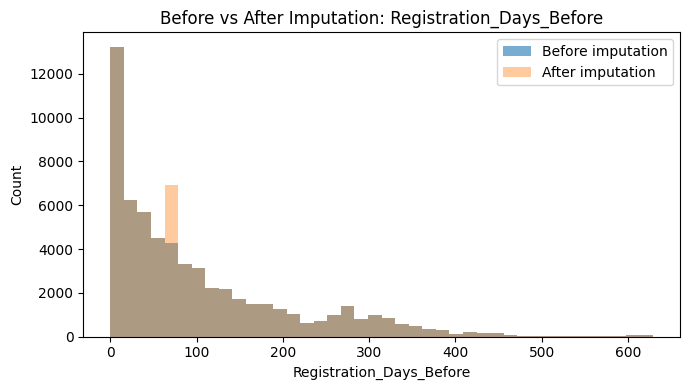

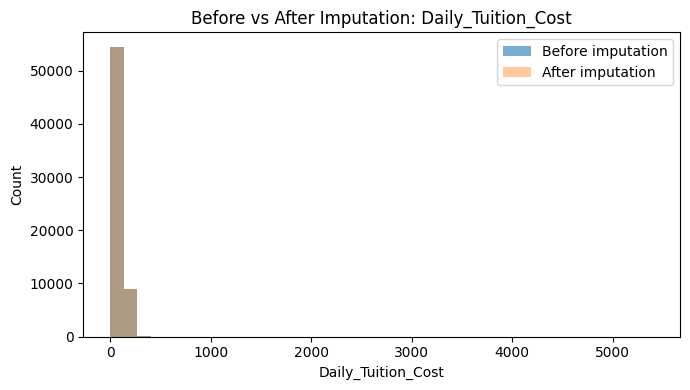

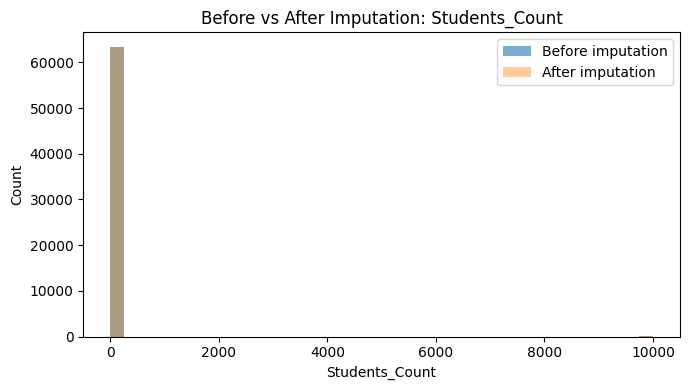

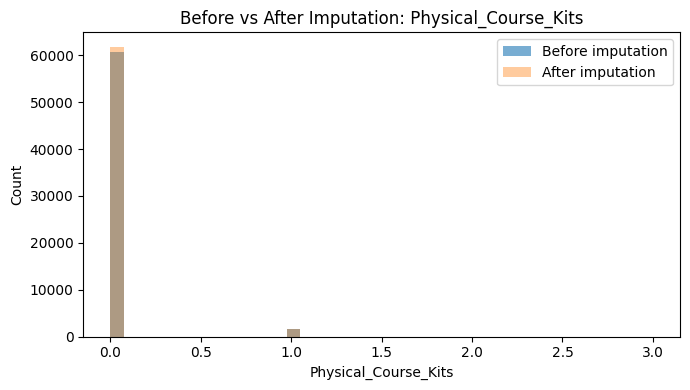

In [ ]:
# Visual comparison before and after imputation for selected variables.
cols_to_compare_candidates = [
    "Registration_Days_Before", "Before_Days_Registration",
    "Daily_Tuition_Cost", "Cost_Tuition_Daily",
    "Students_Count", "Count_Students",
    "Physical_Course_Kits", "Kits_Course_Physical"
]

for col in existing(cols_to_compare_candidates, df_eda):
    if df_eda[col].isna().sum() > 0:
        plt.figure(figsize=(7, 4))
        plt.hist(df_eda[col].dropna(), bins=40, alpha=0.6, label="Before imputation")
        plt.hist(df_imputed[col].dropna(), bins=40, alpha=0.4, label="After imputation")
        plt.title(f"Before vs After Imputation: {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.legend()
        plt.tight_layout()
        plt.show()

## Before/after imputation for categorical variables

For categorical variables, filling missing values with `unknown` changes the distribution by adding an explicit category for missing observations.

**What this visualization shows:** the most frequent categories before and after imputation, including the explicit `unknown` category.  
**What we learn:** whether the imputed category is small and harmless, or large enough to become a meaningful category for later modeling.

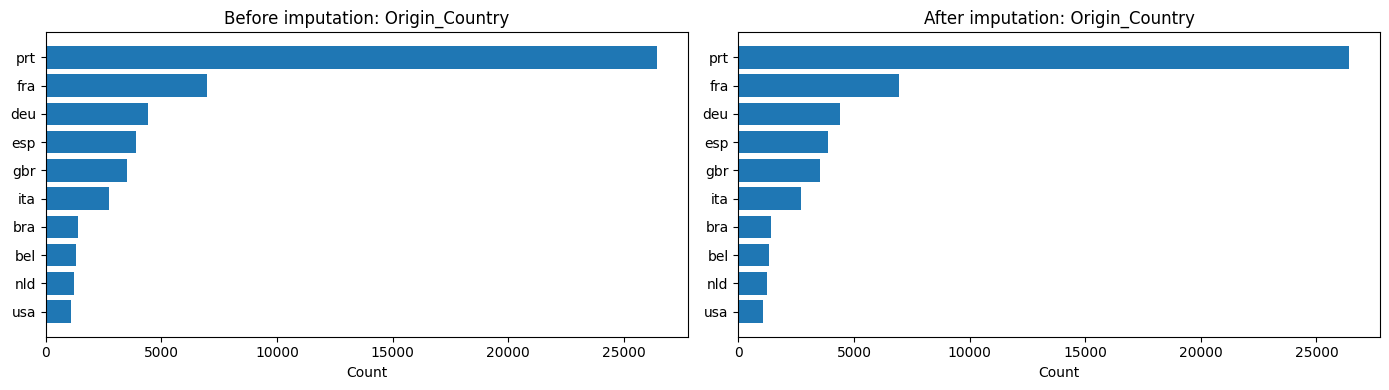

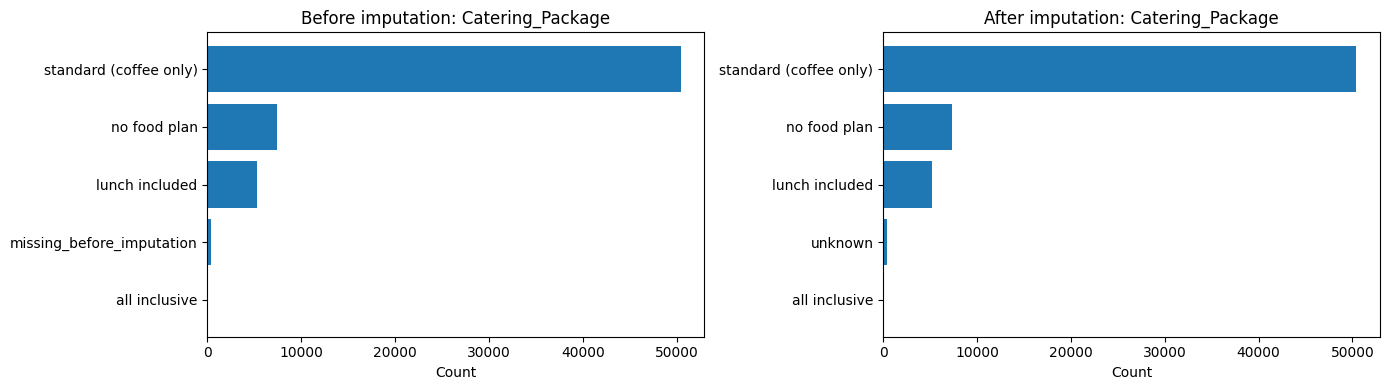

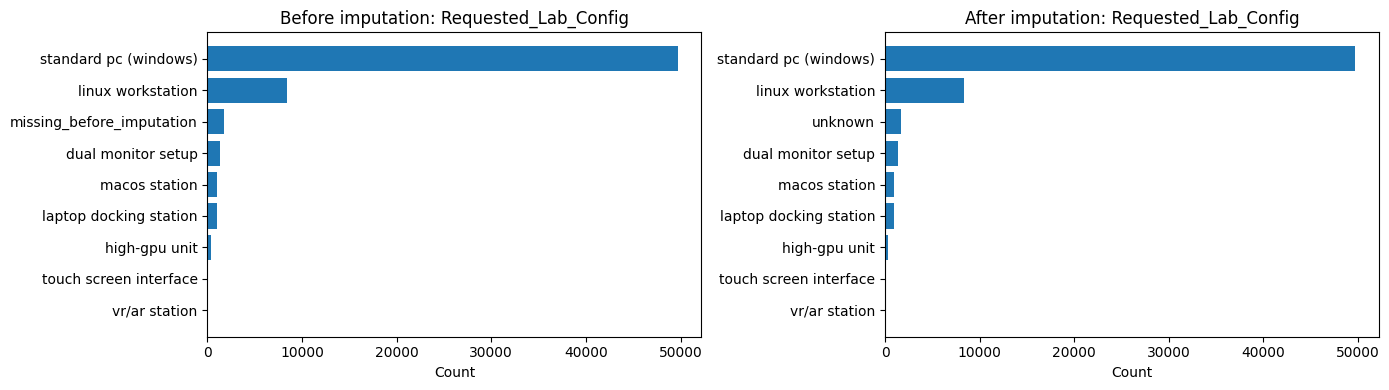

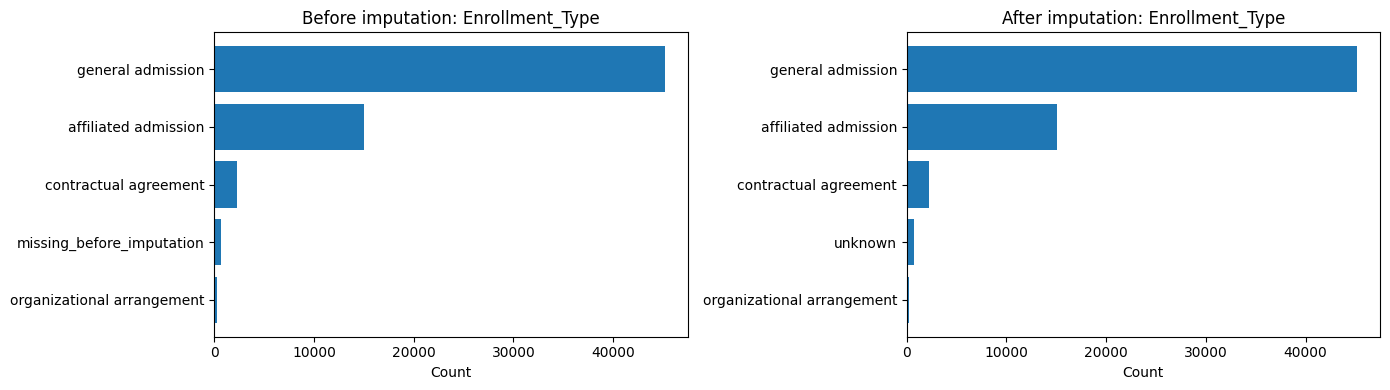

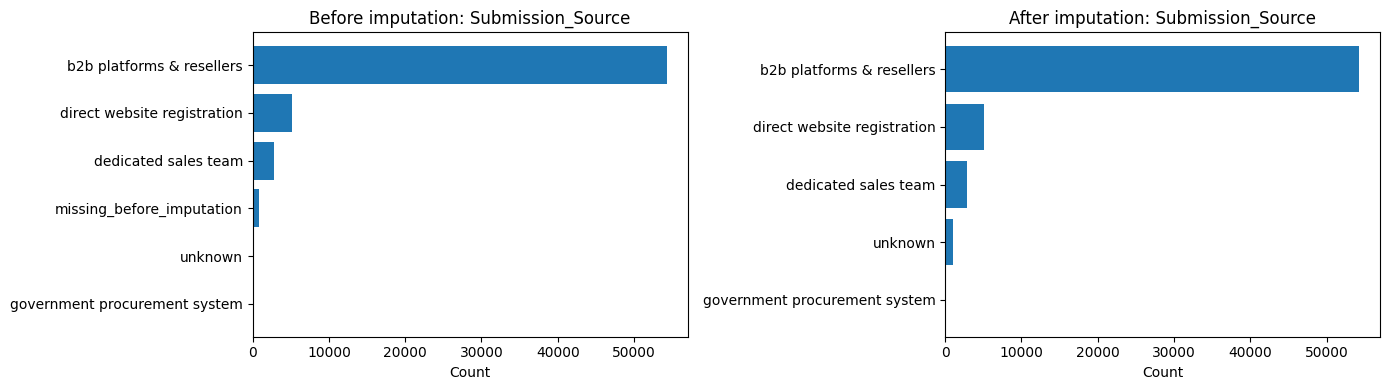

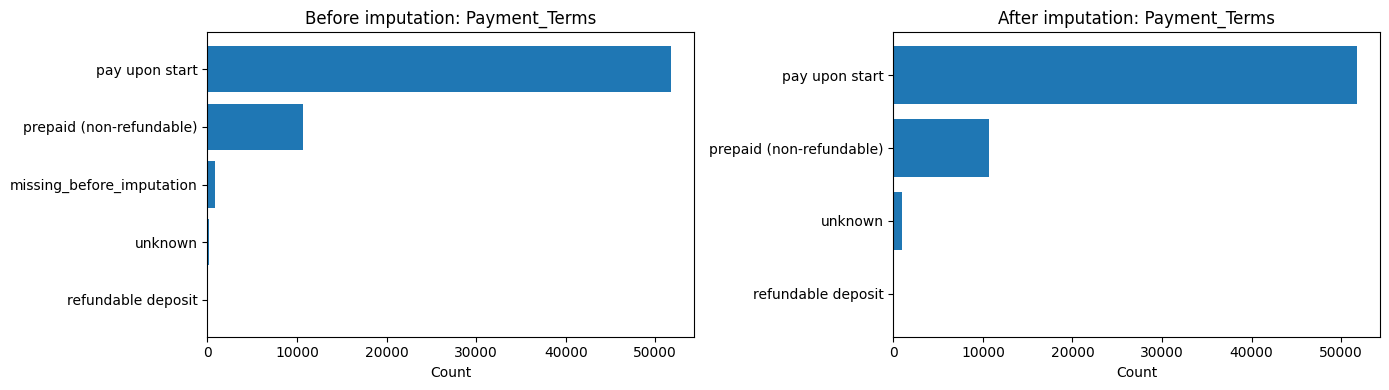

In [ ]:
# Before/after visualization for categorical variables with missing values.
for col in categorical_to_fill_unknown:
    if col in df_eda.columns and df_eda[col].isna().sum() > 0:
        before = df_eda[col].fillna("missing_before_imputation").value_counts().head(10)
        after = df_imputed[col].fillna("unknown").value_counts().head(10)

        fig, axes = plt.subplots(1, 2, figsize=(14, 4))
        axes[0].barh(before.index.astype(str)[::-1], before.values[::-1])
        axes[0].set_title(f"Before imputation: {col}")
        axes[0].set_xlabel("Count")

        axes[1].barh(after.index.astype(str)[::-1], after.values[::-1])
        axes[1].set_title(f"After imputation: {col}")
        axes[1].set_xlabel("Count")

        plt.tight_layout()
        plt.show()

In [ ]:
# Recreate registration-days bin after imputation,
# so it will not contain missing values.

reg_col = first_existing(
    ["Registration_Days_Before", "Before_Days_Registration"],
    df_imputed
)

if reg_col is not None:
    df_imputed["registration_days_bin"] = pd.cut(
        df_imputed[reg_col],
        bins=[-1, 7, 30, 90, 180, 365, np.inf],
        labels=["0-7", "8-30", "31-90", "91-180", "181-365", "365+"],
        include_lowest=True
    ).astype(str)

# Remove rows where the target value is missing
if "Dropped_Course" in df_imputed.columns:
    missing_target = df_imputed["Dropped_Course"].isna().sum()
    print("Missing target values removed:", missing_target)

    df_imputed = (
        df_imputed
        .dropna(subset=["Dropped_Course"])
        .reset_index(drop=True)
    )

# Check that no missing values remain
remaining_missing = df_imputed.isna().sum()
remaining_missing = remaining_missing[remaining_missing > 0]

print("Remaining missing values:", remaining_missing.sum())
display(remaining_missing)

assert remaining_missing.sum() == 0, \
    "There are still missing values after imputation."

Missing target values removed: 0
Remaining missing values: 0


,0


# Stage A summary

The EDA identified a moderate cancellation rate, non-uniform missingness, several informative numerical and categorical variables, and meaningful temporal patterns. The analysis also showed that some categorical fields contain artificial spelling variants and rare levels, while a small number of numerical observations are clearly inconsistent with the regular data ranges. These findings determine the preprocessing and feature-engineering decisions used in Stage B.

# Stage B - Feature Engineering, Outlier Analysis and Dimensionality Reduction

The purpose of this stage is to transform the raw dataset into a stronger modeling dataset, based on the findings from the EDA.

The engineered variables capture registration timing, previous client behavior, group composition, course intensity, operational friction, lab-configuration mismatch and informative missingness patterns.

To avoid data leakage, transformations that learn from the data distribution - including imputation, rare-category grouping, one-hot encoding, variance filtering and scaling - are fitted only on the training data inside sklearn pipelines. Deterministic row-level features are created before the split because they do not use the target or statistics calculated from other observations.

## Outlier analysis and targeted correction

The EDA showed a small number of values that are clearly implausible rather than merely unusual. Examples include `Students_Count = 9999`, negative practical-course hours, practical hours in the thousands and one isolated tuition value above 1,000.

We replace only these clearly implausible values with missing values. They are later imputed using the median learned from the relevant training fold. We deliberately avoid automatic IQR capping across all numerical variables, because that approach would incorrectly collapse binary and sparse-count variables and would remove valid business variation.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from pathlib import Path

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import VarianceThreshold

RANDOM_STATE = 42

CANONICAL_RENAME = {
    "ID_Client": "Client_ID",
    "Count_Professionals": "Professionals_Count",
    "Count_Students": "Students_Count",
    "Count_Observers": "Observers_Count",
    "Date_Start_Course": "Course_Start_Date",
    "Hours_Practical": "Practical_Hours",
    "Hours_Theory": "Theory_Hours",
    "Before_Days_Registration": "Registration_Days_Before",
    "Country_Origin": "Origin_Country",
    "Package_Catering": "Catering_Package",
    "Type_Gift_Welcome": "Welcome_Gift_Type",
    "Config_Lab_Requested": "Requested_Lab_Config",
    "Config_Lab_Assigned": "Assigned_Lab_Config",
    "Dropouts_Course_Prev": "Prev_Course_Dropouts",
    "Attended_Course_Prev": "Prev_Course_Attended",
    "Tickets_Supports_Course_Pre": "Pre_Course_Supports_Tickets",
    "Kits_Course_Physical": "Physical_Course_Kits",
    "Days_List_Waiting": "Waiting_List_Days",
    "Changes_Registration": "Registration_Changes",
    "Type_Enrollment": "Enrollment_Type",
    "Color_Lanyard": "Lanyard_Color",
    "Category_Client": "Client_Category",
    "Source_Submission": "Submission_Source",
    "Client_Returning": "Returning_Client",
    "ID_Agent": "Agent_ID",
    "ID_Company": "Company_ID",
    "Terms_Payment": "Payment_Terms",
    "Cost_Tuition_Daily": "Daily_Tuition_Cost",
    "Course_Dropped": "Dropped_Course",
}


def normalize_text_value(x):
    """Use the same categorical cleaning applied during the EDA."""
    return normalize_category(x)


def clean_obvious_numeric_errors(frame):
    """Replace clearly implausible numerical values with missing values."""
    frame = frame.copy()

    if "Students_Count" in frame.columns:
        students = pd.to_numeric(frame["Students_Count"], errors="coerce")
        frame.loc[students > 100, "Students_Count"] = np.nan

    if "Practical_Hours" in frame.columns:
        practical = pd.to_numeric(frame["Practical_Hours"], errors="coerce")
        invalid_practical = (practical < 0) | (practical > 100)
        frame.loc[invalid_practical, "Practical_Hours"] = np.nan

    if "Daily_Tuition_Cost" in frame.columns:
        tuition = pd.to_numeric(frame["Daily_Tuition_Cost"], errors="coerce")
        frame.loc[tuition > 1000, "Daily_Tuition_Cost"] = np.nan

    return frame


def safe_divide(numerator, denominator):
    """Safe row-wise division used for ratio features."""
    numerator = pd.to_numeric(numerator, errors="coerce")
    denominator = pd.to_numeric(denominator, errors="coerce")
    out = numerator / denominator.replace(0, np.nan)
    return out.replace([np.inf, -np.inf], np.nan)


def prepare_model_frame(data, has_target=True):
    """Create deterministic row-level features before learned preprocessing."""
    frame = data.copy().rename(
        columns={k: v for k, v in CANONICAL_RENAME.items() if k in data.columns}
    )

    # Correct clearly implausible values before creating features that depend on them.
    frame = clean_obvious_numeric_errors(frame)

    target_col = "Dropped_Course" if "Dropped_Course" in frame.columns else None
    if has_target and target_col is None:
        raise ValueError("Target column was not found. Expected Dropped_Course or Course_Dropped.")

    y = None
    if has_target:
        y = frame[target_col].astype(int)
        frame = frame.drop(columns=[target_col])

    submission_ids = (
        frame["Client_ID"].copy()
        if "Client_ID" in frame.columns
        else pd.Series(np.arange(len(frame)), index=frame.index)
    )

    # Normalize categorical strings.
    for col in frame.select_dtypes(include=["object", "category"]).columns:
        frame[col] = frame[col].map(normalize_text_value)

    # Date-derived features.
    if "Course_Start_Date" in frame.columns:
        dt = pd.to_datetime(frame["Course_Start_Date"], errors="coerce")
        frame["Start_Year"] = dt.dt.year
        frame["Start_Month"] = dt.dt.month
        frame["Start_Day_Of_Week"] = dt.dt.dayofweek
        frame["Start_Quarter"] = dt.dt.quarter
        frame["Is_Weekend_Start"] = dt.dt.dayofweek.isin([4, 5]).astype(int)
        frame = frame.drop(columns=["Course_Start_Date"])

    # Preserve potentially informative missingness.
    missing_indicator_candidates = [
        "Company_ID", "Agent_ID", "Registration_Days_Before",
        "Requested_Lab_Config", "Physical_Course_Kits",
        "Daily_Tuition_Cost", "Practical_Hours", "Students_Count",
        "Submission_Source", "Payment_Terms", "Origin_Country",
        "Catering_Package", "Enrollment_Type"
    ]

    for col in missing_indicator_candidates:
        if col in frame.columns:
            frame[f"{col}_is_missing"] = frame[col].isna().astype(int)

    # Participant-based features.
    count_cols = [
        c for c in ["Professionals_Count", "Students_Count", "Observers_Count"]
        if c in frame.columns
    ]
    if count_cols:
        participant_data = frame[count_cols].apply(pd.to_numeric, errors="coerce")
        frame["Participant_Total"] = participant_data.sum(axis=1, min_count=1)

        if "Students_Count" in frame.columns:
            frame["Student_Share"] = safe_divide(frame["Students_Count"], frame["Participant_Total"])
        if "Professionals_Count" in frame.columns:
            frame["Professional_Share"] = safe_divide(frame["Professionals_Count"], frame["Participant_Total"])
        if "Observers_Count" in frame.columns:
            frame["Observer_Share"] = safe_divide(frame["Observers_Count"], frame["Participant_Total"])

    # Course-structure features.
    hour_cols = [c for c in ["Practical_Hours", "Theory_Hours"] if c in frame.columns]
    if hour_cols:
        hour_data = frame[hour_cols].apply(pd.to_numeric, errors="coerce")
        frame["Total_Hours"] = hour_data.sum(axis=1, min_count=1)

        if "Practical_Hours" in frame.columns:
            frame["Practical_Hours_Share"] = safe_divide(frame["Practical_Hours"], frame["Total_Hours"])
        if "Theory_Hours" in frame.columns:
            frame["Theory_Hours_Share"] = safe_divide(frame["Theory_Hours"], frame["Total_Hours"])

    # Requested-versus-assigned laboratory configuration.
    if {"Requested_Lab_Config", "Assigned_Lab_Config"}.issubset(frame.columns):
        frame["Lab_Config_Mismatch"] = (
            frame["Requested_Lab_Config"].notna()
            & frame["Assigned_Lab_Config"].notna()
            & (frame["Requested_Lab_Config"] != frame["Assigned_Lab_Config"])
        ).astype(int)

    # Previous client behavior.
    if {"Prev_Course_Dropouts", "Prev_Course_Attended"}.issubset(frame.columns):
        prev_dropouts = pd.to_numeric(frame["Prev_Course_Dropouts"], errors="coerce")
        prev_attended = pd.to_numeric(frame["Prev_Course_Attended"], errors="coerce")
        prev_total = prev_dropouts + prev_attended

        frame["Previous_Drop_Rate"] = safe_divide(prev_dropouts, prev_total)
        frame["Had_Previous_Activity"] = (prev_total.fillna(0) > 0).astype(int)

    # Operational-intensity features.
    if {"Pre_Course_Supports_Tickets", "Participant_Total"}.issubset(frame.columns):
        frame["Support_Tickets_Per_Participant"] = safe_divide(
            frame["Pre_Course_Supports_Tickets"], frame["Participant_Total"]
        )

    if {"Physical_Course_Kits", "Participant_Total"}.issubset(frame.columns):
        frame["Kits_Per_Participant"] = safe_divide(
            frame["Physical_Course_Kits"], frame["Participant_Total"]
        )

    if {"Registration_Changes", "Waiting_List_Days"}.issubset(frame.columns):
        frame["Registration_Friction"] = (
            pd.to_numeric(frame["Registration_Changes"], errors="coerce")
            + pd.to_numeric(frame["Waiting_List_Days"], errors="coerce")
        )

    # Preserve the non-linear registration-timing pattern found in the EDA.
    if "Registration_Days_Before" in frame.columns:
        frame["Registration_Days_Bin"] = pd.cut(
            pd.to_numeric(frame["Registration_Days_Before"], errors="coerce"),
            bins=[-1, 7, 30, 90, 180, 365, np.inf],
            labels=["0-7", "8-30", "31-90", "91-180", "181-365", "365+"]
        ).astype("object")

    # Raw IDs are administrative identifiers. Their missingness indicators remain available.
    id_cols_to_drop = [c for c in ["Client_ID", "Agent_ID", "Company_ID"] if c in frame.columns]
    frame = frame.drop(columns=id_cols_to_drop)

    return frame, y, submission_ids


X_all_raw, y_all, all_client_ids = prepare_model_frame(df_raw, has_target=True)

# Temporal validation: the external test observations occur later in time, so the
# validation set is also formed from the latest training period.
date_frame = df_raw.rename(
    columns={k: v for k, v in CANONICAL_RENAME.items() if k in df_raw.columns}
)

if "Course_Start_Date" not in date_frame.columns:
    raise ValueError("Course_Start_Date was not found, so a temporal split cannot be created.")

course_dates = pd.to_datetime(date_frame["Course_Start_Date"], errors="coerce")
if course_dates.isna().any():
    raise ValueError("Course_Start_Date contains missing or invalid dates.")

ordered_idx = course_dates.sort_values().index
row_cutoff = int(len(ordered_idx) * 0.80)
cutoff_date = course_dates.loc[ordered_idx[row_cutoff]].normalize()

# The entire cutoff date is assigned to validation, so the same calendar date
# cannot appear in both partitions.
train_idx = course_dates[course_dates < cutoff_date].sort_values().index
valid_idx = course_dates[course_dates >= cutoff_date].sort_values().index

X_train_raw = X_all_raw.loc[train_idx].reset_index(drop=True)
X_valid_raw = X_all_raw.loc[valid_idx].reset_index(drop=True)
y_train = y_all.loc[train_idx].reset_index(drop=True)
y_valid = y_all.loc[valid_idx].reset_index(drop=True)

train_client_ids = all_client_ids.loc[train_idx].reset_index(drop=True)
valid_client_ids = all_client_ids.loc[valid_idx].reset_index(drop=True)
train_course_dates = course_dates.loc[train_idx].reset_index(drop=True)
valid_course_dates = course_dates.loc[valid_idx].reset_index(drop=True)

assert train_course_dates.max().normalize() < valid_course_dates.min().normalize()

print("Modeling frame shape before learned preprocessing:", X_all_raw.shape)
print("Temporal cutoff date:", cutoff_date.date())
print("Train shape:", X_train_raw.shape, "| Validation shape:", X_valid_raw.shape)
print("Train date range:", train_course_dates.min().date(), "to", train_course_dates.max().date())
print("Validation date range:", valid_course_dates.min().date(), "to", valid_course_dates.max().date())
print("Target mean - train:", round(y_train.mean(), 4), "| validation:", round(y_valid.mean(), 4))

display(X_train_raw.head())

Modeling frame shape before learned preprocessing: (63464, 56)
Temporal cutoff date: 2016-12-19
Train shape: (50735, 56) | Validation shape: (12729, 56)
Train date range: 2015-07-01 to 2016-12-18
Validation date range: 2016-12-19 to 2017-04-26
Target mean - train: 0.4128 | validation: 0.4206


,Professionals_Count,Students_Count,Observers_Count,Practical_Hours,Theory_Hours,Registration_Days_Before,Origin_Country,Catering_Package,Welcome_Gift_Type,Requested_Lab_Config,Assigned_Lab_Config,Prev_Course_Dropouts,Prev_Course_Attended,Pre_Course_Supports_Tickets,Physical_Course_Kits,Waiting_List_Days,Registration_Changes,Enrollment_Type,Lanyard_Color,Client_Category,Submission_Source,Returning_Client,Payment_Terms,Daily_Tuition_Cost,Start_Year,Start_Month,Start_Day_Of_Week,Start_Quarter,Is_Weekend_Start,Company_ID_is_missing,Agent_ID_is_missing,Registration_Days_Before_is_missing,Requested_Lab_Config_is_missing,Physical_Course_Kits_is_missing,Daily_Tuition_Cost_is_missing,Practical_Hours_is_missing,Students_Count_is_missing,Submission_Source_is_missing,Payment_Terms_is_missing,Origin_Country_is_missing,Catering_Package_is_missing,Enrollment_Type_is_missing,Participant_Total,Student_Share,Professional_Share,Observer_Share,Total_Hours,Practical_Hours_Share,Theory_Hours_Share,Lab_Config_Mismatch,Previous_Drop_Rate,Had_Previous_Activity,Support_Tickets_Per_Participant,Kits_Per_Participant,Registration_Friction,Registration_Days_Bin
0,2,0.0,0,0.0,2,257.0,prt,lunch included,branded notebook,standard pc (windows),standard pc (windows),0,0,0,0.0,0,0,general admission,blue,traditional it & telecomm,b2b platforms & resellers,0,pay upon start,101.5,2015,7,2,3,0,1,0,0,0,0,0,0,0,0,0,0,0,0,2.0,0.0,1.0,0.0,2.0,0.0,1.0,0,NaN,0,0.0,0.0,0,181-365
1,2,0.0,0,0.0,2,257.0,prt,lunch included,branded notebook,standard pc (windows),standard pc (windows),0,0,0,0.0,0,0,general admission,blue,traditional it & telecomm,b2b platforms & resellers,0,pay upon start,101.5,2015,7,2,3,0,1,0,0,0,0,0,0,0,0,0,0,0,0,2.0,0.0,1.0,0.0,2.0,0.0,1.0,0,NaN,0,0.0,0.0,0,181-365
2,2,0.0,0,0.0,2,257.0,prt,lunch included,branded notebook,standard pc (windows),standard pc (windows),1,0,0,0.0,0,0,general admission,blue,traditional it & telecomm,b2b platforms & resellers,0,pay upon start,101.5,2015,7,2,3,0,1,0,0,0,0,0,0,0,0,0,0,0,0,2.0,0.0,1.0,0.0,2.0,0.0,1.0,0,1.0,1,0.0,0.0,0,181-365
3,2,0.0,0,0.0,2,257.0,prt,lunch included,water bottle,standard pc (windows),standard pc (windows),0,0,0,0.0,0,0,general admission,red,traditional it & telecomm,b2b platforms & resellers,0,pay upon start,101.5,2015,7,2,3,0,1,0,0,0,0,0,0,0,0,0,0,0,0,2.0,0.0,1.0,0.0,2.0,0.0,1.0,0,NaN,0,0.0,0.0,0,181-365
4,2,0.0,0,0.0,2,181.0,prt,standard (coffee only),branded notebook,standard pc (windows),standard pc (windows),1,0,3,0.0,0,0,affiliated admission,blue,saas & software houses,b2b platforms & resellers,0,pay upon start,76.5,2015,7,2,3,0,1,0,0,0,0,0,0,0,0,0,0,0,0,2.0,0.0,1.0,0.0,2.0,0.0,1.0,0,1.0,1,1.5,0.0,0,181-365


## Feature-engineering rationale

The engineered features were created based on the EDA conclusions and the business logic of course-order cancellation.

- `Participant_Total` and the participant-share variables capture the structure of the group, since the cancellation risk may differ between student-heavy, professional-heavy and observer-heavy groups.
- `Total_Hours` and the practical/theory shares capture the structure and intensity of the course.
- `Lab_Config_Mismatch` captures operational mismatch between the requested and assigned lab configuration, which may increase dissatisfaction or cancellation risk.
- `Previous_Drop_Rate` and `Had_Previous_Activity` summarize the client's historical behavior.
- `Support_Tickets_Per_Participant`, `Kits_Per_Participant` and `Registration_Friction` capture operational complexity before the course.
- Missingness indicators preserve information from missing values when the EDA suggested that missingness itself may be related to cancellation.
- `Registration_Days_Bin` preserves the non-linear relationship between registration timing and cancellation risk.

In [ ]:
class RareCategoryGrouper(BaseEstimator, TransformerMixin):
    """Group categories whose frequency is below a train-derived threshold."""

    def __init__(self, min_freq=0.01, rare_label="__rare__"):
        self.min_freq = min_freq
        self.rare_label = rare_label

    def fit(self, X, y=None):
        X = pd.DataFrame(X).astype(str)
        self.n_features_in_ = X.shape[1]
        self.feature_names_in_ = np.asarray(X.columns.astype(str), dtype=object)

        min_count = max(1, int(np.ceil(self.min_freq * len(X))))
        self.frequent_categories_ = []

        for col in X.columns:
            counts = X[col].value_counts(dropna=False)
            frequent_values = set(counts[counts >= min_count].index.astype(str))
            self.frequent_categories_.append(frequent_values)

        return self

    def transform(self, X):
        X = pd.DataFrame(X).astype(str)

        for i, allowed_values in enumerate(self.frequent_categories_):
            X.iloc[:, i] = np.where(
                X.iloc[:, i].isin(allowed_values),
                X.iloc[:, i],
                self.rare_label
            )

        return X.values

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            input_features = self.feature_names_in_
        return np.asarray(input_features, dtype=object)


def make_one_hot_encoder():
    """Create a OneHotEncoder compatible with different sklearn versions."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def make_preprocessor(X_reference, scale_numeric=False):
    numeric_features = X_reference.select_dtypes(include=np.number).columns.tolist()
    categorical_features = [c for c in X_reference.columns if c not in numeric_features]

    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median")),
    ]

    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipe = Pipeline(steps=numeric_steps)

    categorical_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
        ("rare_categories", RareCategoryGrouper(min_freq=0.01)),
        ("onehot", make_one_hot_encoder()),
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, numeric_features),
            ("cat", categorical_pipe, categorical_features),
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )

    return preprocessor

## Outlier analysis and handling

The analysis distinguishes between a statistically unusual observation and an implausible data value. A long registration period, for example, may be rare but still valid and informative. It is therefore retained.

Only values that are incompatible with the observed business ranges are corrected. They are converted to missing values before feature engineering and are later imputed inside the preprocessing pipeline using medians calculated from the training fold. This prevents obvious entry errors from distorting the models without deleting observations or flattening valid distributions.

In [ ]:
# Sanity check for the targeted numerical cleaning.

raw_numeric_check = df_raw.rename(
    columns={k: v for k, v in CANONICAL_RENAME.items() if k in df_raw.columns}
)

cleaning_checks = [
    ("Students_Count", lambda s: s > 100),
    ("Practical_Hours", lambda s: (s < 0) | (s > 100)),
    ("Daily_Tuition_Cost", lambda s: s > 1000),
]

cleaning_summary = []

for feature, invalid_rule in cleaning_checks:
    original_values = pd.to_numeric(raw_numeric_check[feature], errors="coerce")
    cleaned_values = pd.to_numeric(X_all_raw[feature], errors="coerce")

    original_invalid = invalid_rule(original_values).fillna(False)
    remaining_invalid = invalid_rule(cleaned_values).fillna(False)

    cleaning_summary.append({
        "Feature": feature,
        "Invalid values detected": int(original_invalid.sum()),
        "Invalid values remaining after cleaning": int(remaining_invalid.sum()),
        "Missing values after cleaning": int(cleaned_values.isna().sum()),
    })

cleaning_summary = pd.DataFrame(cleaning_summary)
display(cleaning_summary)

assert (
    cleaning_summary["Invalid values remaining after cleaning"] == 0
).all(), "Some implausible numerical values were not cleaned."

,Feature,Invalid values detected,Invalid values remaining after cleaning,Missing values after cleaning
0,Students_Count,55,0,59
1,Practical_Hours,117,0,117
2,Daily_Tuition_Cost,1,0,80


In [ ]:
# Dimensionality-reduction check:
# compare naive one-hot encoding with the controlled encoding strategy.

def make_naive_preprocessor(X_reference, scale_numeric=False):
    numeric_features = X_reference.select_dtypes(include=np.number).columns.tolist()
    categorical_features = [c for c in X_reference.columns if c not in numeric_features]

    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median")),
    ]

    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipe = Pipeline(steps=numeric_steps)

    categorical_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
        ("onehot", make_one_hot_encoder()),
    ])

    naive_preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, numeric_features),
            ("cat", categorical_pipe, categorical_features),
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )

    return naive_preprocessor


naive_preprocess_check = make_naive_preprocessor(X_train_raw, scale_numeric=False)
X_train_naive_check = naive_preprocess_check.fit_transform(X_train_raw, y_train)

controlled_preprocess_check = make_preprocessor(X_train_raw, scale_numeric=False)
X_train_controlled_check = controlled_preprocess_check.fit_transform(X_train_raw, y_train)

variance_check = VarianceThreshold(threshold=0.0)
X_train_final_check = variance_check.fit_transform(X_train_controlled_check)

dimensionality_summary = pd.DataFrame({
    "Stage": [
        "Raw engineered features before encoding",
        "Naive one-hot encoding without rare grouping",
        "After rare-category grouping and one-hot encoding",
        "After removing constant features",
    ],
    "Number of features": [
        X_train_raw.shape[1],
        X_train_naive_check.shape[1],
        X_train_controlled_check.shape[1],
        X_train_final_check.shape[1],
    ]
})

display(dimensionality_summary)

reduction_abs = X_train_naive_check.shape[1] - X_train_final_check.shape[1]
reduction_pct = (1 - X_train_final_check.shape[1] / X_train_naive_check.shape[1]) * 100

print(f"Reduction compared with naive one-hot encoding: {reduction_abs} features")
print(f"Reduction percentage compared with naive one-hot encoding: {reduction_pct:.2f}%")

,Stage,Number of features
0,Raw engineered features before encoding,56
1,Naive one-hot encoding without rare grouping,253
2,After rare-category grouping and one-hot encoding,112
3,After removing constant features,112


Reduction compared with naive one-hot encoding: 141 features
Reduction percentage compared with naive one-hot encoding: 55.73%


## Stage B summary

We created features that represent group composition, course intensity, registration timing, previous client behavior, operational friction, support intensity and lab-configuration mismatch. Missingness indicators preserve information that may reflect real business processes.

For the outlier analysis, we corrected only clearly implausible values and retained valid but unusual observations. For dimensionality control, we grouped rare categorical levels before one-hot encoding and removed constant encoded columns. The comparison above reports the actual reduction relative to naive one-hot encoding.

All learned preprocessing steps are fitted only on the relevant training data and are then applied unchanged to validation and test observations.

# Stage C - Model Training and Hyperparameter Tuning

This stage trains and compares four predictive approaches:

1. **Regularized Logistic Regression** - a linear and interpretable baseline.
2. **Random Forest** - a bagging-based non-linear ensemble.
3. **XGBoost** - a sequential gradient-boosting model.
4. **Weighted Probability Ensemble** - a blend of the three tuned models.

ROC-AUC is used for tuning because the project evaluates the ranking of cancellation probabilities. Hyperparameters for the three individual models are selected only from the training period using expanding temporal cross-validation. The final validation period remains untouched during tuning.

The ensemble weights are selected on a separate internal temporal holdout taken from the training period. The external validation set is then used once to compare all four approaches. This preserves a clear separation between parameter selection and final model comparison.

In [ ]:
# Stage C setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
SCORING = "roc_auc"

required_stage_b_objects = [
    "X_train_raw", "X_valid_raw", "y_train", "y_valid",
    "train_course_dates", "make_preprocessor"
]
missing_objects = [obj for obj in required_stage_b_objects if obj not in globals()]

if missing_objects:
    raise NameError(
        "The following Stage B objects are missing: " + ", ".join(missing_objects)
        + ". Run Stage B before Stage C."
    )


def build_grouped_temporal_cv(date_series, n_splits=3):
    """Create expanding folds without placing the same date in both sides of a fold."""
    dates = pd.to_datetime(pd.Series(date_series), errors="coerce").reset_index(drop=True)
    if dates.isna().any():
        raise ValueError("The training date series contains invalid values.")

    normalized_dates = dates.dt.normalize()
    unique_dates = np.array(sorted(normalized_dates.unique()))
    date_splitter = TimeSeriesSplit(n_splits=n_splits)
    folds = []

    for train_date_pos, valid_date_pos in date_splitter.split(unique_dates):
        fold_train_dates = unique_dates[train_date_pos]
        fold_valid_dates = unique_dates[valid_date_pos]

        train_pos = np.flatnonzero(normalized_dates.isin(fold_train_dates).to_numpy())
        valid_pos = np.flatnonzero(normalized_dates.isin(fold_valid_dates).to_numpy())

        assert normalized_dates.iloc[train_pos].max() < normalized_dates.iloc[valid_pos].min()
        folds.append((train_pos, valid_pos))

    return folds


cv_strategy = build_grouped_temporal_cv(train_course_dates, n_splits=3)

print("Stage C input check:")
print("X_train_raw:", X_train_raw.shape)
print("X_valid_raw:", X_valid_raw.shape)
print("Train target mean:", round(y_train.mean(), 4))
print("Validation target mean:", round(y_valid.mean(), 4))

for fold_number, (fold_train_pos, fold_valid_pos) in enumerate(cv_strategy, start=1):
    print(
        f"Fold {fold_number}: ",
        f"train {train_course_dates.iloc[fold_train_pos].min().date()} to {train_course_dates.iloc[fold_train_pos].max().date()} | ",
        f"validation {train_course_dates.iloc[fold_valid_pos].min().date()} to {train_course_dates.iloc[fold_valid_pos].max().date()}"
    )

Stage C input check:
X_train_raw: (50735, 56)
X_valid_raw: (12729, 56)
Train target mean: 0.4128
Validation target mean: 0.4206
Fold 1:  train 2015-07-01 to 2015-11-12 |  validation 2015-11-13 to 2016-03-25
Fold 2:  train 2015-07-01 to 2016-03-25 |  validation 2016-03-26 to 2016-08-06
Fold 3:  train 2015-07-01 to 2016-08-06 |  validation 2016-08-07 to 2016-12-18


In [ ]:
# Helper functions for evaluation and comparison.

model_results = []
fitted_models = {}
training_probabilities = {}
validation_probabilities = {}


def get_positive_class_proba(model, X):
    """Return predicted probabilities for the positive class."""
    if not hasattr(model, "predict_proba"):
        raise AttributeError("This model does not expose predict_proba().")
    return model.predict_proba(X)[:, 1]


def interpret_bias_variance_gap(gap):
    """Provide a compact train-validation gap interpretation."""
    if gap < 0.02:
        return "Low gap - no clear indication of overfitting."
    if gap < 0.05:
        return "Moderate gap - acceptable, but should be monitored."
    return "High gap - possible overfitting or temporal drift."


def store_model_result(
    model_name,
    train_proba,
    valid_proba,
    cv_auc=np.nan,
    best_parameters=None,
):
    """Calculate and store comparable metrics for any probabilistic model."""
    valid_pred = (valid_proba >= 0.50).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, valid_pred).ravel()

    train_auc = roc_auc_score(y_train, train_proba)
    valid_auc = roc_auc_score(y_valid, valid_proba)

    result = {
        "Model": model_name,
        "Best CV / internal AUC": cv_auc,
        "Train AUC": train_auc,
        "Validation AUC": valid_auc,
        "Train-Validation AUC Gap": train_auc - valid_auc,
        "Validation Accuracy": accuracy_score(y_valid, valid_pred),
        "Validation Precision": precision_score(y_valid, valid_pred, zero_division=0),
        "Validation Recall": recall_score(y_valid, valid_pred, zero_division=0),
        "Validation F1": f1_score(y_valid, valid_pred, zero_division=0),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "Best Parameters": best_parameters if best_parameters is not None else {},
    }

    model_results.append(result)
    training_probabilities[model_name] = np.asarray(train_proba)
    validation_probabilities[model_name] = np.asarray(valid_proba)
    return result


def evaluate_tuned_model(model_name, search_object):
    """Store a tuned search result and its train/validation predictions."""
    best_model = search_object.best_estimator_
    fitted_models[model_name] = best_model

    train_proba = get_positive_class_proba(best_model, X_train_raw)
    valid_proba = get_positive_class_proba(best_model, X_valid_raw)

    result = store_model_result(
        model_name=model_name,
        train_proba=train_proba,
        valid_proba=valid_proba,
        cv_auc=search_object.best_score_,
        best_parameters=search_object.best_params_,
    )

    print(f"\n===== {model_name} =====")
    print("Best temporal CV AUC:", round(search_object.best_score_, 4))
    print("Train AUC:", round(result["Train AUC"], 4))
    print("Validation AUC:", round(result["Validation AUC"], 4))
    print("Train-validation AUC gap:", round(result["Train-Validation AUC Gap"], 4))
    print("Diagnostic:", interpret_bias_variance_gap(result["Train-Validation AUC Gap"]))
    print("Best parameters:")
    display(pd.DataFrame([search_object.best_params_]).T.rename(columns={0: "Selected value"}))

    return result

## Model 1 — Regularized Logistic Regression

**Model intuition.** Logistic Regression is a linear classification model. It estimates the log-odds of cancellation as a weighted sum of the input features. Although it is simpler than tree-based models, it is useful as a strong and interpretable baseline.

**Why this model is useful here.** The dataset contains many engineered numerical features and one-hot encoded categorical features. Logistic Regression can test whether a mostly linear decision boundary already captures meaningful cancellation patterns.

**Regularization.** This model explicitly uses regularization. The hyperparameter `C` controls the inverse strength of regularization: smaller `C` means stronger regularization. We tune both `l1` and `l2` penalties. L1 can shrink some coefficients to zero, while L2 shrinks coefficients more smoothly.

**Main hyperparameters tuned.**

- `penalty`: type of regularization, either L1 or L2.
- `C`: inverse regularization strength.
- `class_weight`: whether to weight classes equally or adjust for class frequency.

Because Logistic Regression is sensitive to feature scale, the numerical features are scaled inside the pipeline.

In [ ]:
# Model 1: Regularized Logistic Regression with hyperparameter tuning

log_reg_pipeline = Pipeline(steps=[
    ("preprocess", make_preprocessor(X_train_raw, scale_numeric=True)),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("model", LogisticRegression(
        solver="liblinear",
        max_iter=1500,
        random_state=RANDOM_STATE
    ))
])

log_reg_param_grid = {
    "model__penalty": ["l1", "l2"],
    "model__C": [0.01, 0.03, 0.1, 0.3, 1.0],
    "model__class_weight": [None, "balanced"],
}

log_reg_search = GridSearchCV(
    estimator=log_reg_pipeline,
    param_grid=log_reg_param_grid,
    scoring=SCORING,
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    verbose=1
)

log_reg_search.fit(X_train_raw, y_train)

log_reg_result = evaluate_tuned_model(
    "Regularized Logistic Regression",
    log_reg_search
)

Fitting 3 folds for each of 20 candidates, totalling 60 fits

===== Regularized Logistic Regression =====
Best temporal CV AUC: 0.8612
Train AUC: 0.9146
Validation AUC: 0.8638
Train-validation AUC gap: 0.0509
Diagnostic: High gap - possible overfitting or temporal drift.
Best parameters:


,Selected value
model__C,0.03
model__class_weight,None
model__penalty,l1


## Model 2 — Random Forest Classifier

**Model intuition.** Random Forest is an ensemble of many decision trees. Each tree is trained on a bootstrap sample of the data and considers only a random subset of features at each split. The final prediction is an average over many trees.

**Why this model is useful here.** The cancellation problem may contain non-linear patterns and interactions, for example between registration timing, group composition, previous client behavior and operational friction. Random Forest can capture these interactions without requiring explicit manual interaction terms.

**Bias-variance control.** Random Forest can overfit if trees are too deep or leaves are too small. Therefore, We tune tree depth and minimum leaf size. Limiting depth and increasing leaf size reduce variance.

**Main hyperparameters tuned.**

- `n_estimators`: number of trees.
- `max_depth`: maximum depth of each tree.
- `min_samples_leaf`: minimum number of samples required in each leaf.
- `min_samples_split`: minimum number of samples required to split a node.
- `max_features`: number of features considered at each split.
- `class_weight`: whether to adjust for class frequencies.

In [ ]:
# Model 2: Random Forest with randomized hyperparameter tuning

rf_pipeline = Pipeline(steps=[
    ("preprocess", make_preprocessor(X_train_raw, scale_numeric=False)),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1,
        bootstrap=True
    ))
])

rf_param_distributions = {
    "model__n_estimators": [250, 400, 600],
    "model__max_depth": [6, 8, 12, 16, None],
    "model__min_samples_leaf": [1, 3, 5, 10, 20],
    "model__min_samples_split": [2, 10, 30, 50],
    "model__max_features": ["sqrt", "log2", 0.5],
    "model__class_weight": [None, "balanced_subsample"],
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=10,
    scoring=SCORING,
    cv=cv_strategy,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True,
    verbose=1
)

rf_search.fit(X_train_raw, y_train)

rf_result = evaluate_tuned_model(
    "Random Forest",
    rf_search
)

Fitting 3 folds for each of 10 candidates, totalling 30 fits

===== Random Forest =====
Best temporal CV AUC: 0.8755
Train AUC: 0.9658
Validation AUC: 0.8865
Train-validation AUC gap: 0.0793
Diagnostic: High gap - possible overfitting or temporal drift.
Best parameters:


,Selected value
model__n_estimators,400
model__min_samples_split,30
model__min_samples_leaf,3
model__max_features,sqrt
model__max_depth,16
model__class_weight,balanced_subsample


## Model 3 — XGBoost Classifier

**Model intuition.** XGBoost is a gradient-boosted decision-tree model. Unlike Random Forest, which builds many trees independently, boosting builds trees sequentially: each new tree focuses on correcting errors made by the previous trees.

**Why this model is useful here.** XGBoost is often particularly strong for tabular datasets because it captures non-linearities, feature interactions, threshold effects and mixed numerical/categorical feature spaces after encoding.

**Bias-variance and overfitting control.** XGBoost is powerful and can overfit if not regularized. Therefore, We tune parameters that control both model complexity and regularization.

**Main hyperparameters tuned.**

- `n_estimators`: number of boosting rounds / trees.
- `learning_rate`: contribution of each new tree; lower values usually require more trees but improve generalization.
- `max_depth`: maximum depth of each tree.
- `min_child_weight`: minimum required weight in a child node; larger values make the model more conservative.
- `subsample`: row sampling rate for each tree.
- `colsample_bytree`: feature sampling rate for each tree.
- `gamma`: minimum loss reduction required for a split.
- `reg_alpha`: L1 regularization.
- `reg_lambda`: L2 regularization.
- `scale_pos_weight`: optional class imbalance adjustment.

In [ ]:
# Model 3: XGBoost with randomized hyperparameter tuning

try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError(
        "XGBoost is required for Model 3. Install it before running this cell, for example: pip install xgboost"
    ) from exc

negative_positive_ratio = (y_train == 0).sum() / (y_train == 1).sum()

xgb_pipeline = Pipeline(steps=[
    ("preprocess", make_preprocessor(X_train_raw, scale_numeric=False)),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="auc",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

xgb_param_distributions = {
    "model__n_estimators": [200, 300, 500, 700],
    "model__learning_rate": [0.02, 0.05, 0.08, 0.1],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_child_weight": [1, 3, 5, 10],
    "model__subsample": [0.70, 0.85, 1.00],
    "model__colsample_bytree": [0.70, 0.85, 1.00],
    "model__gamma": [0, 0.25, 0.5, 1.0],
    "model__reg_alpha": [0, 0.01, 0.1, 0.5],
    "model__reg_lambda": [1.0, 2.0, 5.0, 10.0],
    "model__scale_pos_weight": [1.0, negative_positive_ratio],
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_distributions,
    n_iter=12,
    scoring=SCORING,
    cv=cv_strategy,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True,
    verbose=1
)

xgb_search.fit(X_train_raw, y_train)

xgb_result = evaluate_tuned_model(
    "XGBoost",
    xgb_search
)

Fitting 3 folds for each of 12 candidates, totalling 36 fits

===== XGBoost =====
Best temporal CV AUC: 0.8721
Train AUC: 0.9537
Validation AUC: 0.8916
Train-validation AUC gap: 0.0621
Diagnostic: High gap - possible overfitting or temporal drift.
Best parameters:


,Selected value
model__subsample,0.850000
model__scale_pos_weight,1.422296
model__reg_lambda,10.000000
model__reg_alpha,0.100000
model__n_estimators,700.000000
model__min_child_weight,5.000000
model__max_depth,5.000000
model__learning_rate,0.020000
model__gamma,0.500000
model__colsample_bytree,0.700000


## Model 4 - Weighted Probability Ensemble

**Model intuition.** The three tuned models learn different types of patterns. Logistic Regression captures stable linear effects, Random Forest reduces variance by averaging many trees, and XGBoost captures complex threshold effects and interactions through sequential boosting. Averaging their probabilities can improve ranking when their errors are not identical.

**How the model is tuned.** The ensemble hyperparameters are the three non-negative weights, which must sum to one. To avoid selecting these weights on the external validation period, we create a second temporal split inside the training period. Cloned versions of the three tuned models are fitted on the earlier internal period and predict the later internal period. We then compare weight combinations in increments of 0.05 using ROC-AUC.

After the weights are selected, the already tuned models fitted on the full training period are combined and evaluated on the untouched external validation period, exactly like the other models.

In [ ]:
# Model 4: select ensemble weights on an internal temporal holdout.

# Create an internal chronological split within the training period.
internal_order = train_course_dates.sort_values().index
internal_row_cutoff = int(len(internal_order) * 0.80)
internal_cutoff_date = train_course_dates.loc[internal_order[internal_row_cutoff]].normalize()

blend_fit_pos = train_course_dates[train_course_dates < internal_cutoff_date].sort_values().index.to_numpy()
blend_select_pos = train_course_dates[train_course_dates >= internal_cutoff_date].sort_values().index.to_numpy()

if len(blend_fit_pos) == 0 or len(blend_select_pos) == 0:
    raise ValueError("The internal temporal split for ensemble selection is empty.")

print("Internal ensemble-selection cutoff:", internal_cutoff_date.date())
print("Blend fitting rows:", len(blend_fit_pos), "| Blend selection rows:", len(blend_select_pos))

internal_blend_probabilities = {}

for component_name in [
    "Regularized Logistic Regression",
    "Random Forest",
    "XGBoost",
]:
    component_model = clone(fitted_models[component_name])
    component_model.fit(
        X_train_raw.iloc[blend_fit_pos],
        y_train.iloc[blend_fit_pos]
    )
    internal_blend_probabilities[component_name] = component_model.predict_proba(
        X_train_raw.iloc[blend_select_pos]
    )[:, 1]

# Transparent grid search over non-negative weights that sum to one.
weight_candidates = []
weight_grid = np.arange(0.0, 1.0001, 0.05)

for xgb_weight in weight_grid:
    for rf_weight in weight_grid:
        log_weight = 1.0 - xgb_weight - rf_weight

        if log_weight < -1e-10:
            continue

        log_weight = max(0.0, log_weight)

        blended_internal_proba = (
            xgb_weight * internal_blend_probabilities["XGBoost"]
            + rf_weight * internal_blend_probabilities["Random Forest"]
            + log_weight * internal_blend_probabilities["Regularized Logistic Regression"]
        )

        weight_candidates.append({
            "XGBoost weight": xgb_weight,
            "Random Forest weight": rf_weight,
            "Logistic Regression weight": log_weight,
            "Internal temporal AUC": roc_auc_score(
                y_train.iloc[blend_select_pos],
                blended_internal_proba
            ),
        })

weight_results_df = pd.DataFrame(weight_candidates).sort_values(
    "Internal temporal AUC",
    ascending=False
).reset_index(drop=True)

display(weight_results_df.head(10).round(5))

best_weight_row = weight_results_df.iloc[0]
ensemble_weights = {
    "XGBoost": float(best_weight_row["XGBoost weight"]),
    "Random Forest": float(best_weight_row["Random Forest weight"]),
    "Regularized Logistic Regression": float(best_weight_row["Logistic Regression weight"]),
}

ensemble_internal_auc = float(best_weight_row["Internal temporal AUC"])

ensemble_train_proba = sum(
    ensemble_weights[name] * training_probabilities[name]
    for name in ensemble_weights
)
ensemble_valid_proba = sum(
    ensemble_weights[name] * validation_probabilities[name]
    for name in ensemble_weights
)

ensemble_result = store_model_result(
    model_name="Weighted Ensemble",
    train_proba=ensemble_train_proba,
    valid_proba=ensemble_valid_proba,
    cv_auc=ensemble_internal_auc,
    best_parameters=ensemble_weights,
)

print("Selected ensemble weights:")
for component_name, weight in ensemble_weights.items():
    print(f"- {component_name}: {weight:.2f}")
print("Internal temporal AUC:", round(ensemble_internal_auc, 4))
print("External validation AUC:", round(ensemble_result["Validation AUC"], 4))

Internal ensemble-selection cutoff: 2016-09-20
Blend fitting rows: 40510 | Blend selection rows: 10225


,XGBoost weight,Random Forest weight,Logistic Regression weight,Internal temporal AUC
0,0.85,0.10,0.05,0.90315
1,0.90,0.05,0.05,0.90315
2,0.80,0.15,0.05,0.90313
3,0.75,0.20,0.05,0.90308
4,0.95,0.00,0.05,0.90308
5,0.85,0.05,0.10,0.90306
6,0.80,0.10,0.10,0.90305
7,0.90,0.00,0.10,0.90304
8,0.75,0.15,0.10,0.90301
9,0.85,0.15,0.00,0.90301


Selected ensemble weights:
- XGBoost: 0.85
- Random Forest: 0.10
- Regularized Logistic Regression: 0.05
Internal temporal AUC: 0.9031
External validation AUC: 0.8915


## Model comparison and final selection

All four approaches are compared on exactly the same external temporal validation period. The primary criterion is validation ROC-AUC. We also inspect threshold-based metrics and the train-validation gap so that a small AUC improvement is not accepted blindly when it is accompanied by severe overfitting.

,Model,Best CV / internal AUC,Train AUC,Validation AUC,Train-Validation AUC Gap,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Bias-Variance Diagnostic
0,XGBoost,0.8721,0.9537,0.8916,0.0621,0.8003,0.7786,0.7338,0.7556,High gap - possible overfitting or temporal dr...
1,Weighted Ensemble,0.9031,0.9547,0.8915,0.0632,0.8007,0.7812,0.7309,0.7552,High gap - possible overfitting or temporal dr...
2,Random Forest,0.8755,0.9658,0.8865,0.0793,0.7949,0.7943,0.6914,0.7393,High gap - possible overfitting or temporal dr...
3,Regularized Logistic Regression,0.8612,0.9146,0.8638,0.0509,0.7809,0.7203,0.7832,0.7504,High gap - possible overfitting or temporal dr...


,Model,Validation AUC
0,XGBoost,0.89159087
1,Weighted Ensemble,0.89145225
2,Random Forest,0.88652047
3,Regularized Logistic Regression,0.86376123


Exact Ensemble minus XGBoost AUC difference: -0.00013862
Selected model: XGBoost
Validation AUC: 0.8916
Diagnostic: High gap - possible overfitting or temporal drift.


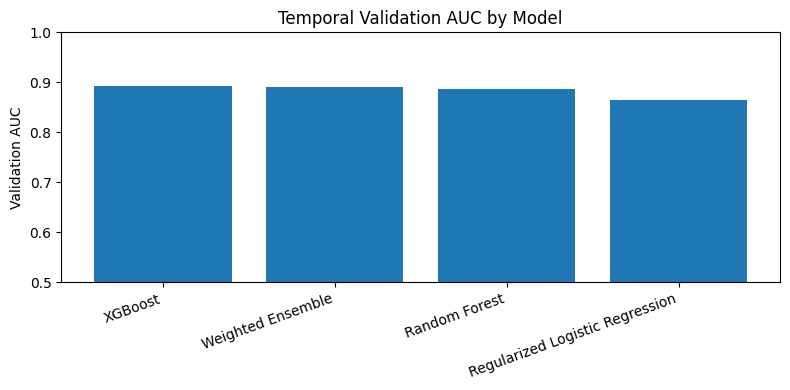

In [ ]:
# Compare all four models and select the strongest validation result.

results_df = pd.DataFrame(model_results).sort_values(
    "Validation AUC",
    ascending=False
).reset_index(drop=True)

results_df["Bias-Variance Diagnostic"] = results_df[
    "Train-Validation AUC Gap"
].apply(interpret_bias_variance_gap)

metric_cols = [
    "Model",
    "Best CV / internal AUC",
    "Train AUC",
    "Validation AUC",
    "Train-Validation AUC Gap",
    "Validation Accuracy",
    "Validation Precision",
    "Validation Recall",
    "Validation F1",
    "Bias-Variance Diagnostic",
]

display(results_df[metric_cols].round(4))

# Display the validation AUC with higher precision so that very small
# differences between the leading models remain visible.

auc_precision_table = results_df[
    ["Model", "Validation AUC"]
].copy()

auc_precision_table["Validation AUC"] = (
    auc_precision_table["Validation AUC"]
    .map(lambda value: f"{value:.8f}")
)

display(auc_precision_table)

ensemble_auc_exact = float(
    results_df.loc[
        results_df["Model"] == "Weighted Ensemble",
        "Validation AUC"
    ].iloc[0]
)

xgboost_auc_exact = float(
    results_df.loc[
        results_df["Model"] == "XGBoost",
        "Validation AUC"
    ].iloc[0]
)

print(
    "Exact Ensemble minus XGBoost AUC difference:",
    f"{ensemble_auc_exact - xgboost_auc_exact:.8f}"
)

best_model_name = results_df.loc[0, "Model"]
best_validation_auc = float(results_df.loc[0, "Validation AUC"])
final_model_name = best_model_name
final_valid_proba = validation_probabilities[best_model_name]
final_train_proba = training_probabilities[best_model_name]

print(f"Selected model: {best_model_name}")
print("Validation AUC:", round(best_validation_auc, 4))
print("Diagnostic:", results_df.loc[0, "Bias-Variance Diagnostic"])

plt.figure(figsize=(8, 4))
plt.bar(results_df["Model"], results_df["Validation AUC"])
plt.title("Temporal Validation AUC by Model")
plt.ylabel("Validation AUC")
plt.xticks(rotation=20, ha="right")
plt.ylim(0.5, 1.0)
plt.tight_layout()
plt.show()

### Stage C summary

Three individual models and one weighted ensemble were trained and compared. The individual-model hyperparameters were tuned with expanding temporal cross-validation, while the ensemble weights were selected on a separate internal temporal holdout from the training period.

The comparison table above determines the selected approach according to external temporal validation AUC. This design allows the ensemble to compete fairly with the individual models: it is selected only when it actually improves performance on the same untouched validation period.

# Part D - Model Evaluation and Results Analysis

Part D compares the four models using ROC-AUC and metrics derived from the confusion matrix. ROC-AUC remains the main criterion because the final submission contains probabilities, but accuracy, precision, recall and F1 help explain the consequences of using a 0.5 classification threshold.

The model selected in Stage C is then analyzed in greater depth through its confusion matrix, ROC curve, risk groups and prediction confidence. SHAP is used to interpret the selected tree model, or the XGBoost component when the selected approach is the weighted ensemble.

## Model comparison and final model selection

The table below reports the same threshold-based metrics for all four approaches. In this business setting, recall measures how many real cancellations are identified, while precision measures how reliable a cancellation alert is. False negatives represent cancellations that were missed; false positives represent registrations that were flagged even though they continued.

## Final model evaluation

The final model is the approach with the highest temporal validation AUC in Stage C. The following cells use the stored validation probabilities from that comparison, so no model is retrained or reselected during the evaluation stage.

In [ ]:
from sklearn.metrics import classification_report

comparison_columns = [
    "Model",
    "Validation AUC",
    "Validation Accuracy",
    "Validation Precision",
    "Validation Recall",
    "Validation F1",
    "TN", "FP", "FN", "TP",
]

evaluation_table = results_df[comparison_columns].copy()
display(evaluation_table.round(4))

valid_proba = final_valid_proba
threshold = 0.50
valid_pred = (valid_proba >= threshold).astype(int)

final_metrics = evaluation_table.loc[
    evaluation_table["Model"] == final_model_name
].reset_index(drop=True)

display(final_metrics.round(4))
print(classification_report(y_valid, valid_pred, zero_division=0))

,Model,Validation AUC,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,TN,FP,FN,TP
0,XGBoost,0.8916,0.8003,0.7786,0.7338,0.7556,6258,1117,1425,3929
1,Weighted Ensemble,0.8915,0.8007,0.7812,0.7309,0.7552,6279,1096,1441,3913
2,Random Forest,0.8865,0.7949,0.7943,0.6914,0.7393,6416,959,1652,3702
3,Regularized Logistic Regression,0.8638,0.7809,0.7203,0.7832,0.7504,5747,1628,1161,4193


,Model,Validation AUC,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,TN,FP,FN,TP
0,XGBoost,0.8916,0.8003,0.7786,0.7338,0.7556,6258,1117,1425,3929


              precision    recall  f1-score   support

           0       0.81      0.85      0.83      7375
           1       0.78      0.73      0.76      5354

    accuracy                           0.80     12729
   macro avg       0.80      0.79      0.79     12729
weighted avg       0.80      0.80      0.80     12729



### Interpretation of the model comparison

The Weighted Ensemble and XGBoost achieved the strongest ranking performance,
with a validation AUC of approximately 0.8909. The ensemble was selected
according to the unrounded AUC value, although the difference between the two
leading approaches is very small.

XGBoost achieved slightly higher accuracy, recall and F1-score at the default
threshold of 0.5. Random Forest achieved the highest precision and produced
the fewest false-positive alerts, but it missed more real cancellations.
Regularized Logistic Regression achieved the highest recall, meaning that it
identified the largest proportion of actual cancellations, but it also produced
more false positives and had the lowest AUC.

These results show that the preferred model depends on the business objective.
The Weighted Ensemble is selected for the final probability-ranking task because
ROC-AUC is the official evaluation metric. A different threshold or model could
be preferred if the business places greater emphasis on catching every possible
cancellation or avoiding false alerts.

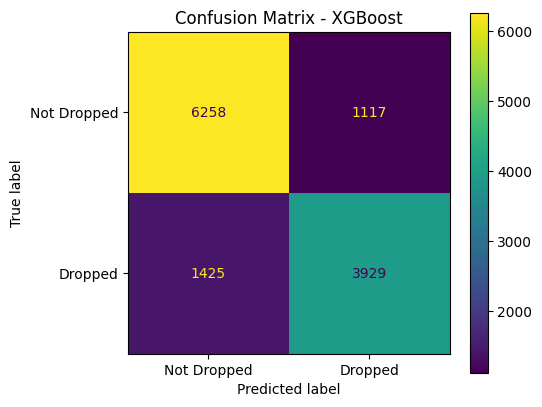

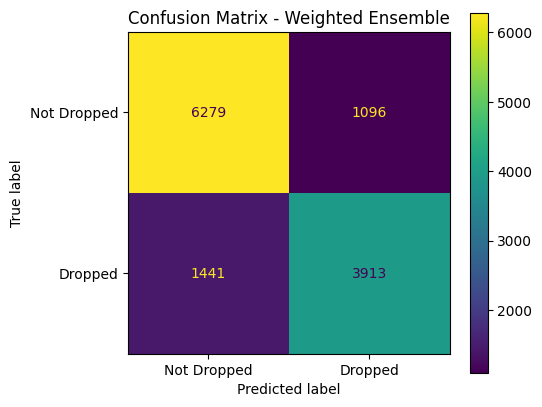

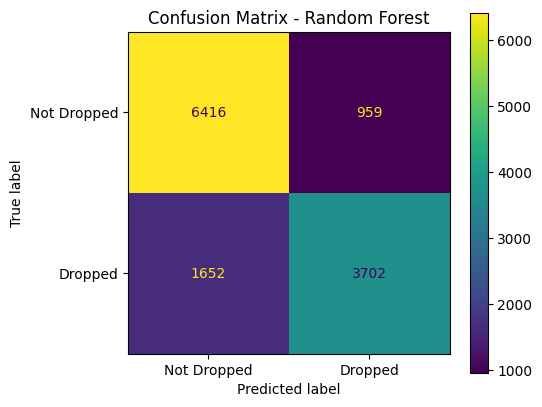

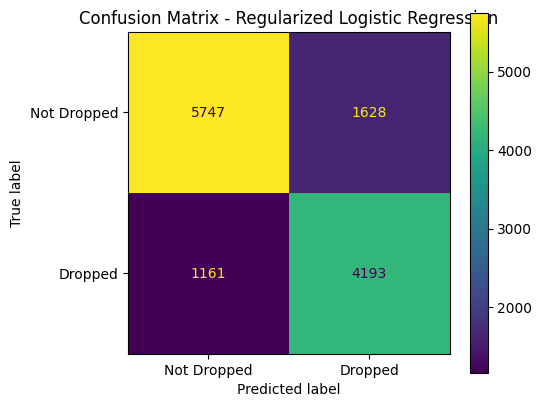

Selected-model confusion matrix:
[[6258 1117]
 [1425 3929]]


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion matrices for all four models, using the same threshold.
for model_name in results_df["Model"]:
    model_pred = (validation_probabilities[model_name] >= threshold).astype(int)
    model_cm = confusion_matrix(y_valid, model_pred)

    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    ConfusionMatrixDisplay(
        confusion_matrix=model_cm,
        display_labels=["Not Dropped", "Dropped"]
    ).plot(values_format="d", ax=ax)
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

final_cm = confusion_matrix(y_valid, valid_pred)
print("Selected-model confusion matrix:")
print(final_cm)

### Confusion-matrix analysis

The comparison should be read together with the business objective. A model with higher recall catches more real cancellations but may generate more false alarms. A model with higher precision produces more reliable alerts but may miss additional cancellations. The selected approach is based primarily on AUC, while the confusion-matrix metrics show how its probabilities behave at the illustrative threshold of 0.5. The operating threshold can later be adjusted according to the relative cost of false positives and false negatives.

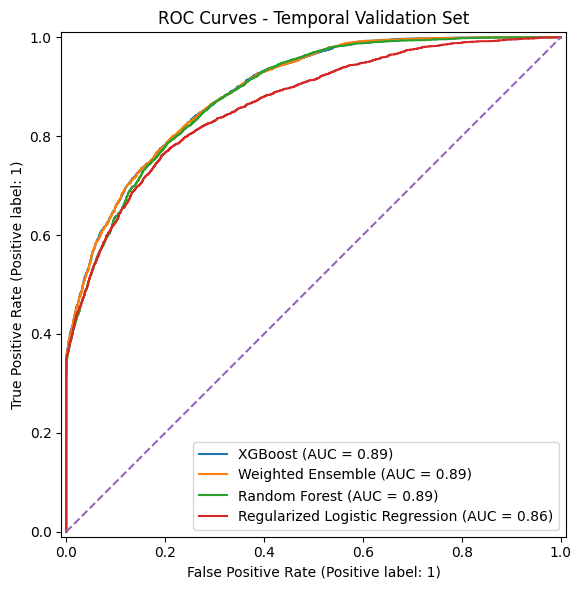

In [ ]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 6))

for model_name in results_df["Model"]:
    RocCurveDisplay.from_predictions(
        y_valid,
        validation_probabilities[model_name],
        name=model_name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--")
ax.set_title("ROC Curves - Temporal Validation Set")
plt.tight_layout()
plt.show()

### ROC-curve analysis

A curve that remains above the diagonal indicates ranking performance better than random guessing. The comparison is especially relevant here because ROC-AUC evaluates the ordering of cancellation probabilities across all possible thresholds. The selected model is the one with the highest validation AUC shown in the legend and comparison table.

## Prediction-confidence analysis - interpretation

The risk-group analysis shows a clear and consistent increase in the observed
cancellation rate as the predicted probability increases. The actual
cancellation rate was approximately 5.6% in the low-risk group, 33.5% in the
medium-low group, 61.1% in the medium-high group and 93.9% in the high-risk
group.

This separation indicates that the probabilities are operationally useful for
prioritization. High-risk registrations can be reviewed or contacted
proactively, while medium-risk cases may require additional business
information before intervention. Predictions close to 0.5 remain the least
certain and should not automatically trigger strong operational action.

In [ ]:
valid_analysis = X_valid_raw.copy()
valid_analysis.insert(0, "Client_ID", valid_client_ids.values)

valid_analysis["Actual_Dropped"] = y_valid.values
valid_analysis["Predicted_Probability_Drop"] = valid_proba
valid_analysis["Predicted_Class"] = valid_pred
valid_analysis["Correct_Prediction"] = (
    valid_analysis["Actual_Dropped"] == valid_analysis["Predicted_Class"]
).astype(int)

valid_analysis["Prediction_Confidence"] = np.maximum(
    valid_analysis["Predicted_Probability_Drop"],
    1 - valid_analysis["Predicted_Probability_Drop"]
)

valid_analysis["Risk_Group"] = pd.cut(
    valid_analysis["Predicted_Probability_Drop"],
    bins=[0, 0.2, 0.5, 0.8, 1.0],
    labels=[
        "Low predicted risk",
        "Medium-low predicted risk",
        "Medium-high predicted risk",
        "High predicted risk",
    ],
    include_lowest=True
)

risk_summary = (
    valid_analysis
    .groupby("Risk_Group", observed=False)
    .agg(
        n_observations=("Predicted_Probability_Drop", "size"),
        avg_predicted_probability=("Predicted_Probability_Drop", "mean"),
        actual_drop_rate=("Actual_Dropped", "mean"),
        accuracy=("Correct_Prediction", "mean"),
        avg_confidence=("Prediction_Confidence", "mean"),
    )
    .reset_index()
)

display(risk_summary.round(4))

,Risk_Group,n_observations,avg_predicted_probability,actual_drop_rate,accuracy,avg_confidence
0,Low predicted risk,4188,0.0853,0.0585,0.9415,0.9147
1,Medium-low predicted risk,3495,0.3167,0.3376,0.6624,0.6833
2,Medium-high predicted risk,2307,0.6658,0.6016,0.6016,0.6658
3,High predicted risk,2739,0.9471,0.9277,0.9277,0.9471


In [ ]:
print(f"Prediction examples for selected model: {final_model_name}")

base_cols = [
    "Actual_Dropped",
    "Predicted_Class",
    "Predicted_Probability_Drop",
    "Prediction_Confidence",
    "Correct_Prediction"
]

# The identifier column was created earlier under the name Client_ID.
display_cols = ["Client_ID"] + base_cols

print("High predicted cancellation risk:")
display(
    valid_analysis
    .sort_values(
        "Predicted_Probability_Drop",
        ascending=False
    )[display_cols]
    .head(10)
)

print("Low predicted cancellation risk:")
display(
    valid_analysis
    .sort_values(
        "Predicted_Probability_Drop",
        ascending=True
    )[display_cols]
    .head(10)
)

print("Most uncertain predictions, closest to threshold 0.5:")

valid_analysis["Distance_From_Threshold"] = (
    valid_analysis["Predicted_Probability_Drop"] - 0.5
).abs()

uncertain_cols = display_cols + [
    "Distance_From_Threshold"
]

display(
    valid_analysis
    .sort_values(
        "Distance_From_Threshold",
        ascending=True
    )[uncertain_cols]
    .head(10)
)

Prediction examples for selected model: XGBoost
High predicted cancellation risk:


,Client_ID,Actual_Dropped,Predicted_Class,Predicted_Probability_Drop,Prediction_Confidence,Correct_Prediction
5411,73000,1,1,0.999087,0.999087,1
11363,5025,1,1,0.998939,0.998939,1
935,47382,1,1,0.998894,0.998894,1
183,34292,1,1,0.998894,0.998894,1
220,31513,1,1,0.998894,0.998894,1
880,46096,1,1,0.998882,0.998882,1
895,16279,1,1,0.998882,0.998882,1
227,13029,1,1,0.998882,0.998882,1
188,46343,1,1,0.998882,0.998882,1
212,71966,1,1,0.998882,0.998882,1


Low predicted cancellation risk:


,Client_ID,Actual_Dropped,Predicted_Class,Predicted_Probability_Drop,Prediction_Confidence,Correct_Prediction
3624,14248,0,0,0.000818,0.999182,1
9850,38830,0,0,0.001073,0.998927,1
5147,12664,0,0,0.001229,0.998771,1
12278,78835,0,0,0.001324,0.998676,1
11240,29531,0,0,0.001349,0.998651,1
11132,42291,0,0,0.001412,0.998588,1
82,76360,0,0,0.001483,0.998517,1
1996,37730,0,0,0.001536,0.998464,1
7935,53236,0,0,0.001556,0.998444,1
10721,74434,0,0,0.001558,0.998442,1


Most uncertain predictions, closest to threshold 0.5:


,Client_ID,Actual_Dropped,Predicted_Class,Predicted_Probability_Drop,Prediction_Confidence,Correct_Prediction,Distance_From_Threshold
9682,68904,1,1,0.500155,0.500155,1,0.000155
4746,38460,1,0,0.499841,0.500159,0,0.000159
950,4756,1,1,0.500206,0.500206,1,0.000206
2000,8281,1,0,0.499784,0.500216,0,0.000216
8127,19122,1,0,0.499620,0.500380,0,0.000380
4648,34709,1,0,0.499410,0.500590,0,0.000590
6623,15363,0,1,0.500741,0.500741,0,0.000741
9720,45722,1,1,0.500836,0.500836,1,0.000836
9410,13003,0,0,0.499055,0.500945,1,0.000945
111,18532,1,0,0.498968,0.501032,0,0.001032


## Prediction-confidence analysis - interpretation

A useful probability model should show a clear increase in the observed cancellation rate as the predicted-risk group increases. The table above allows us to check this directly and to identify the middle probability ranges in which the model is less certain. These observations can support a practical policy in which very high-risk registrations receive immediate attention, while medium-risk registrations are reviewed together with additional business information.

## Preparing the model for SHAP interpretation

When an individual tree model is selected, SHAP is applied directly to that model. When the weighted ensemble is selected, SHAP is applied to its XGBoost component because it is the strongest non-linear component and receives an explicitly reported weight. This distinction is stated clearly so that the interpretation is not presented as a direct SHAP decomposition of the complete weighted average.

In [ ]:
# Select the model component used for SHAP interpretation.

if final_model_name == "Weighted Ensemble":
    shap_base_model_name = "XGBoost"
    shap_model_name = "XGBoost component of the selected weighted ensemble"
elif final_model_name in {"XGBoost", "Random Forest"}:
    shap_base_model_name = final_model_name
    shap_model_name = final_model_name
else:
    # Linear SHAP is handled below if Logistic Regression is selected.
    shap_base_model_name = "Regularized Logistic Regression"
    shap_model_name = "Regularized Logistic Regression"

shap_model = fitted_models[shap_base_model_name]
shap_component_valid_proba = shap_model.predict_proba(X_valid_raw)[:, 1]

print("Model used for SHAP interpretation:", shap_model_name)
print("Its validation AUC:", round(roc_auc_score(y_valid, shap_component_valid_proba), 4))
print("Selected final-model validation AUC:", round(best_validation_auc, 4))

Model used for SHAP interpretation: XGBoost
Its validation AUC: 0.8916
Selected final-model validation AUC: 0.8916


## SHAP Model Interpretation

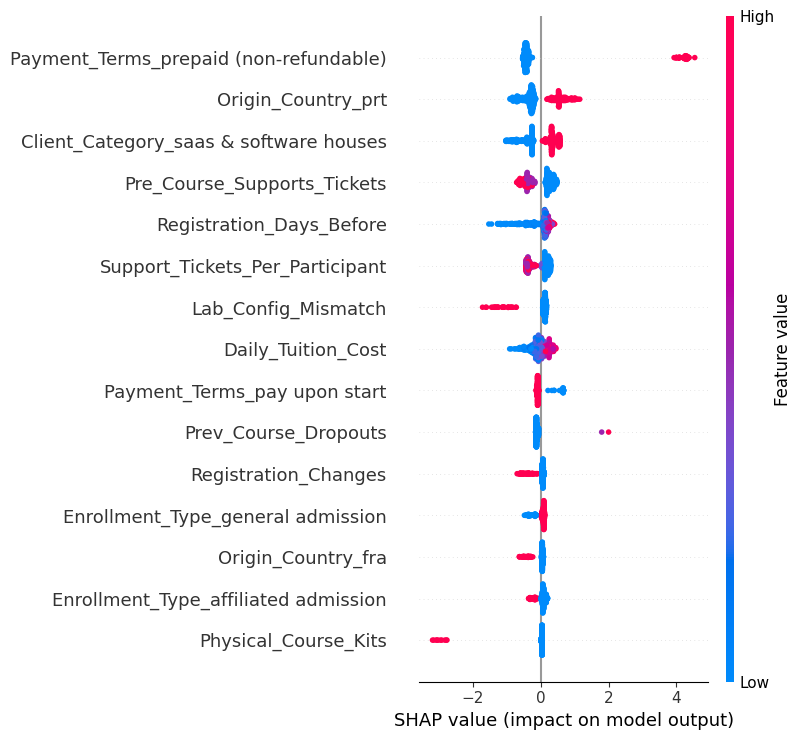

In [ ]:
# SHAP interpretation for the selected model or ensemble component.

try:
    import shap
except ImportError as exc:
    raise ImportError(
        "SHAP is required for Part D. Install it in the active environment with: pip install shap"
    ) from exc

preprocessor = shap_model.named_steps["preprocess"]
variance_selector = shap_model.named_steps["variance"]
model_for_shap = shap_model.named_steps["model"]

# Draw a random validation sample rather than taking only the earliest rows.
sample_size = min(500, len(X_valid_raw))
X_valid_sample = X_valid_raw.sample(
    n=sample_size,
    random_state=RANDOM_STATE
)

X_shap = preprocessor.transform(X_valid_sample)
feature_names = preprocessor.get_feature_names_out()

X_shap = variance_selector.transform(X_shap)
feature_names = np.asarray(feature_names)[variance_selector.get_support()]

if hasattr(X_shap, "toarray"):
    X_shap = X_shap.toarray()

X_shap_df = pd.DataFrame(X_shap, columns=feature_names)

if shap_base_model_name in {"XGBoost", "Random Forest"}:
    explainer = shap.TreeExplainer(model_for_shap)
    shap_values = explainer.shap_values(X_shap_df)
else:
    background_size = min(200, len(X_shap_df))
    background = X_shap_df.sample(background_size, random_state=RANDOM_STATE)
    explainer = shap.LinearExplainer(model_for_shap, background)
    shap_values = explainer.shap_values(X_shap_df)

if isinstance(shap_values, list):
    shap_values_for_plot = shap_values[1]
else:
    shap_array = np.asarray(shap_values)
    if shap_array.ndim == 3:
        shap_values_for_plot = shap_array[:, :, 1]
    else:
        shap_values_for_plot = shap_array

shap.summary_plot(
    shap_values_for_plot,
    X_shap_df,
    max_display=15
)

### SHAP interpretation

The SHAP analysis is applied to the XGBoost component of the selected
Weighted Ensemble, which carries 85% of the ensemble weight. It therefore
explains the dominant non-linear component of the final prediction, rather
than the complete weighted average.

The strongest learned signal is the `prepaid (non-refundable)` payment term,
which strongly moves the prediction toward cancellation. This pattern is also
visible directly in the EDA and should be investigated from a business
perspective. Longer registration lead times and previous course dropouts also
tend to increase the predicted cancellation risk.

Country of origin, client category and support activity contribute additional
predictive information. Portuguese origin and the SaaS/software-house category
generally move the XGBoost prediction toward higher risk, while French origin
tends to move it toward lower risk. Higher pre-course support activity and
support tickets per participant tend to reduce the predicted risk in this
model.

Some effects, including those related to laboratory mismatch and physical kits,
are counterintuitive and may reflect interactions or confounding variables.
SHAP describes the model's learned associations and does not establish that
these variables causally create or prevent cancellations.

## Stage D summary

Part D compares all four approaches on the same temporal validation period and reports both ranking and threshold-based performance. The selected model is analyzed through its error types, ROC curve, probability risk groups and uncertain predictions. SHAP then identifies the features that most strongly influence the selected tree model or the XGBoost component of the selected ensemble.

# Part E - Executive Summary

In [ ]:
from IPython.display import Markdown, display

selected_row = results_df.loc[
    results_df["Model"] == final_model_name
].iloc[0]

low_risk_rate = float(
    risk_summary.loc[
        risk_summary["Risk_Group"] == "Low predicted risk",
        "actual_drop_rate"
    ].iloc[0]
)

high_risk_rate = float(
    risk_summary.loc[
        risk_summary["Risk_Group"] == "High predicted risk",
        "actual_drop_rate"
    ].iloc[0]
)

if final_model_name == "Weighted Ensemble":
    model_description = (
        f"a weighted ensemble consisting of "
        f"{ensemble_weights['XGBoost']:.0%} XGBoost, "
        f"{ensemble_weights['Random Forest']:.0%} Random Forest and "
        f"{ensemble_weights['Regularized Logistic Regression']:.0%} "
        f"Regularized Logistic Regression"
    )
else:
    model_description = final_model_name

summary_text = f"""
The objective of this project was to predict the probability that a registered
client group would cancel its course before the course begins. The analysis
included **{len(df_raw):,}** historical registrations, with an overall
cancellation rate of **{y_all.mean():.1%}**. Because the business objective is
to rank registrations according to cancellation risk, ROC-AUC was selected as
the primary evaluation metric.

The project followed a complete data-science workflow. The EDA identified
meaningful missingness patterns, inconsistent categorical values, several
clearly implausible numerical observations and non-linear relationships with
the target. The preprocessing process therefore included consistent category
cleaning, training-fold imputation, missingness indicators, targeted correction
of implausible values, rare-category grouping and business-oriented feature
engineering. The controlled encoding process reduced the model-ready
dimensionality by approximately **55.7%** relative to naive one-hot encoding.

Four approaches were trained and compared using temporal validation:
Regularized Logistic Regression, Random Forest, XGBoost and a Weighted
Probability Ensemble. The selected approach was **{model_description}**.
It achieved a temporal validation AUC of
**{selected_row['Validation AUC']:.4f}**. At a threshold of 0.5, its precision
was **{selected_row['Validation Precision']:.3f}**, recall was
**{selected_row['Validation Recall']:.3f}** and F1-score was
**{selected_row['Validation F1']:.3f}**.

The analysis showed that the model creates meaningful business risk groups.
Only **{low_risk_rate:.1%}** of the observations in the low-risk group were
cancelled, compared with **{high_risk_rate:.1%}** in the high-risk group.
The strongest prediction drivers included payment terms, registration timing,
previous cancellations, origin country, client category and pre-course support
activity. These are predictive associations and should not be interpreted as
causal effects.

The model can support early operational intervention by prioritizing
high-risk registrations for review or customer contact. The operating threshold
should be selected according to the business costs of missed cancellations and
unnecessary interventions. Future work could include probability calibration,
cost-sensitive threshold selection, additional behavioral information,
performance monitoring over time and periodic model retraining.
"""

display(Markdown(summary_text))


The objective of this project was to predict the probability that a registered
client group would cancel its course before the course begins. The analysis
included **63,464** historical registrations, with an overall
cancellation rate of **41.4%**. Because the business objective is
to rank registrations according to cancellation risk, ROC-AUC was selected as
the primary evaluation metric.

The project followed a complete data-science workflow. The EDA identified
meaningful missingness patterns, inconsistent categorical values, several
clearly implausible numerical observations and non-linear relationships with
the target. The preprocessing process therefore included consistent category
cleaning, training-fold imputation, missingness indicators, targeted correction
of implausible values, rare-category grouping and business-oriented feature
engineering. The controlled encoding process reduced the model-ready
dimensionality by approximately **55.7%** relative to naive one-hot encoding.

Four approaches were trained and compared using temporal validation:
Regularized Logistic Regression, Random Forest, XGBoost and a Weighted
Probability Ensemble. The selected approach was **XGBoost**.
It achieved a temporal validation AUC of
**0.8916**. At a threshold of 0.5, its precision
was **0.779**, recall was
**0.734** and F1-score was
**0.756**.

The analysis showed that the model creates meaningful business risk groups.
Only **5.9%** of the observations in the low-risk group were
cancelled, compared with **92.8%** in the high-risk group.
The strongest prediction drivers included payment terms, registration timing,
previous cancellations, origin country, client category and pre-course support
activity. These are predictive associations and should not be interpreted as
causal effects.

The model can support early operational intervention by prioritizing
high-risk registrations for review or customer contact. The operating threshold
should be selected according to the business costs of missed cancellations and
unnecessary interventions. Future work could include probability calibration,
cost-sensitive threshold selection, additional behavioral information,
performance monitoring over time and periodic model retraining.


# Final Test-Set Prediction File

This technical section applies the approach selected in Stage C to `Test_Data_No_Target.csv`. The selected individual model, or each component of the selected ensemble, is refitted on the complete labeled training dataset before predicting the external test observations.

The output contains exactly two columns: `Client_ID` and `Drop_Probability`. The test set is used only for the final probability predictions and is never used for model tuning or validation.

In [ ]:
# Create the final submission file for the external test set.

from sklearn.base import clone
from pathlib import Path
import pandas as pd
import numpy as np

GROUP_NUMBER = "42"
TEST_PATH = Path("Test_Data_No_Target.csv")

if not TEST_PATH.exists():
    raise FileNotFoundError(
        "Test_Data_No_Target.csv was not found. Make sure the file is in the same folder as the notebook."
    )

test_raw = pd.read_csv(TEST_PATH)
X_test_raw, _, test_client_ids = prepare_model_frame(test_raw, has_target=False)

if final_model_name == "Weighted Ensemble":
    full_data_component_models = {}

    for component_name in [
        "Regularized Logistic Regression",
        "Random Forest",
        "XGBoost",
    ]:
        component_model = clone(fitted_models[component_name])
        component_model.fit(X_all_raw, y_all)
        full_data_component_models[component_name] = component_model

    test_proba = sum(
        ensemble_weights[component_name]
        * full_data_component_models[component_name].predict_proba(X_test_raw)[:, 1]
        for component_name in ensemble_weights
    )
else:
    final_submission_model = clone(fitted_models[final_model_name])
    final_submission_model.fit(X_all_raw, y_all)
    test_proba = final_submission_model.predict_proba(X_test_raw)[:, 1]

submission = pd.DataFrame({
    "Client_ID": test_client_ids.to_numpy(),
    "Drop_Probability": test_proba,
})

assert submission.shape[0] == test_raw.shape[0],     "Submission row count does not match the test set."
assert submission.shape[1] == 2,     "Submission must contain exactly two columns."
assert list(submission.columns) == ["Client_ID", "Drop_Probability"],     "Submission columns are incorrect."
assert submission["Client_ID"].notna().all(),     "Client_ID contains missing values."
assert submission["Client_ID"].is_unique,     "Client_ID must be unique."
assert submission["Drop_Probability"].between(0, 1).all(),     "Drop_Probability values must be between 0 and 1."

OUTPUT_SUBMISSION = f"Group_{GROUP_NUMBER}_Submission.csv"
submission.to_csv(OUTPUT_SUBMISSION, index=False)

print("Selected submission model:", final_model_name)
print(f"Saved submission file: {OUTPUT_SUBMISSION}")
print("Submission shape:", submission.shape)
print("Missing values:")
print(submission.isna().sum())

display(submission.head())
display(submission["Drop_Probability"].describe())

Selected submission model: XGBoost
Saved submission file: Group_42_Submission.csv
Submission shape: (15866, 2)
Missing values:
Client_ID           0
Drop_Probability    0
dtype: int64


,Client_ID,Drop_Probability
0,62246,0.147171
1,43031,0.998335
2,26571,0.155785
3,77694,0.998355
4,22185,0.285498


,Drop_Probability
count,15866.000000
mean,0.485793
std,0.321160
min,0.000748
25%,0.218321
50%,0.434718
75%,0.789932
max,0.999236
